In [ ]:

import pandas as pd
train= pd.read_csv("/content/train.csv")
print(train.head())

   id  Gender  Age  Driving_License  Region_Code  Previously_Insured  \
0   1    Male   44                1         28.0                   0   
1   2    Male   76                1          3.0                   0   
2   3    Male   47                1         28.0                   0   
3   4    Male   21                1         11.0                   1   
4   5  Female   29                1         41.0                   1   

  Vehicle_Age Vehicle_Damage  Annual_Premium  Policy_Sales_Channel  Vintage  \
0   > 2 Years            Yes         40454.0                  26.0      217   
1    1-2 Year             No         33536.0                  26.0      183   
2   > 2 Years            Yes         38294.0                  26.0       27   
3    < 1 Year             No         28619.0                 152.0      203   
4    < 1 Year             No         27496.0                 152.0       39   

   Response  
0         1  
1         0  
2         1  
3         0  
4         0  


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [ ]:
train.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


In [ ]:
train = train.drop('id',axis=1)

In [ ]:
train.shape

(381109, 11)

In [ ]:
train.isnull().sum()

,0
id,0
Gender,0
Age,0
Driving_License,0
Region_Code,0
Previously_Insured,0
Vehicle_Age,0
Vehicle_Damage,0
Annual_Premium,0
Policy_Sales_Channel,0


# EDA

Previously_Insured
0    206481
1    174628
Name: count, dtype: int64


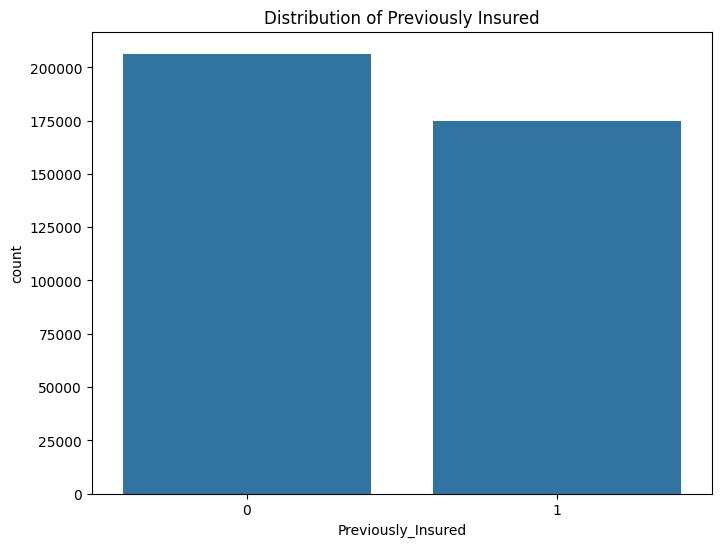

Response
0    334399
1     46710
Name: count, dtype: int64


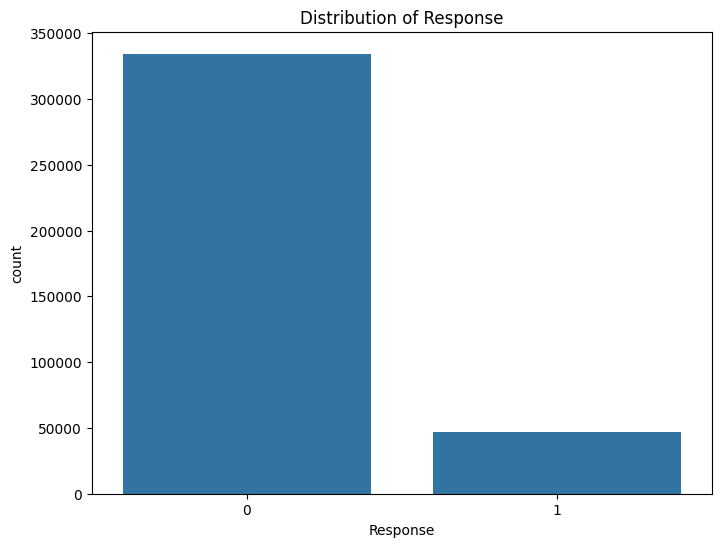

Percentage Distribution of Response:
 Response
0    87.743664
1    12.256336
Name: proportion, dtype: float64


In [ ]:
# prompt: Perform univariate analysis Previously Insured and response are categorical

import matplotlib.pyplot as plt
# Univariate Analysis for Categorical Features: Previously Insured and Response

# Previously Insured
print(train['Previously_Insured'].value_counts())
plt.figure(figsize=(8, 6))
sns.countplot(x='Previously_Insured', data=train)
plt.title('Distribution of Previously Insured')
plt.show()

# Response
print(train['Response'].value_counts())
plt.figure(figsize=(8, 6))
sns.countplot(x='Response', data=train)
plt.title('Distribution of Response')
plt.show()

# Calculate and print the percentage distribution for 'Response'
response_counts = train['Response'].value_counts(normalize=True) * 100
print("Percentage Distribution of Response:\n", response_counts)


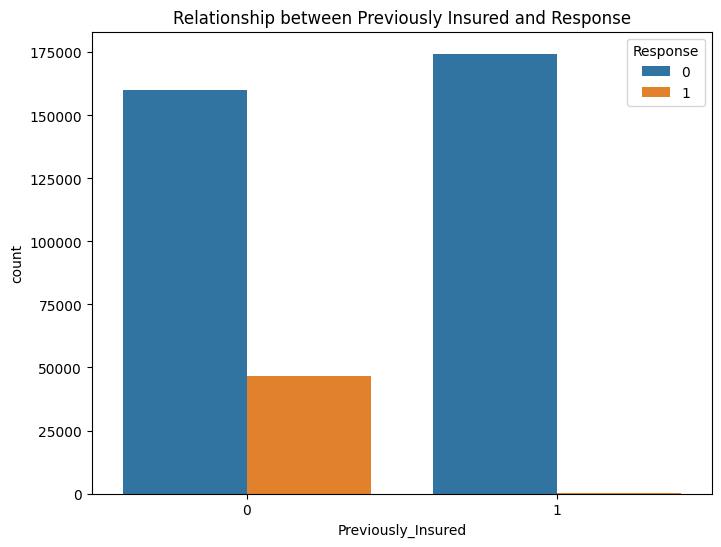

Percentage Distribution of Response by Previously Insured:
 Previously_Insured  Response
0                   0           77.454584
                    1           22.545416
1                   0           99.909522
                    1            0.090478
Name: proportion, dtype: float64


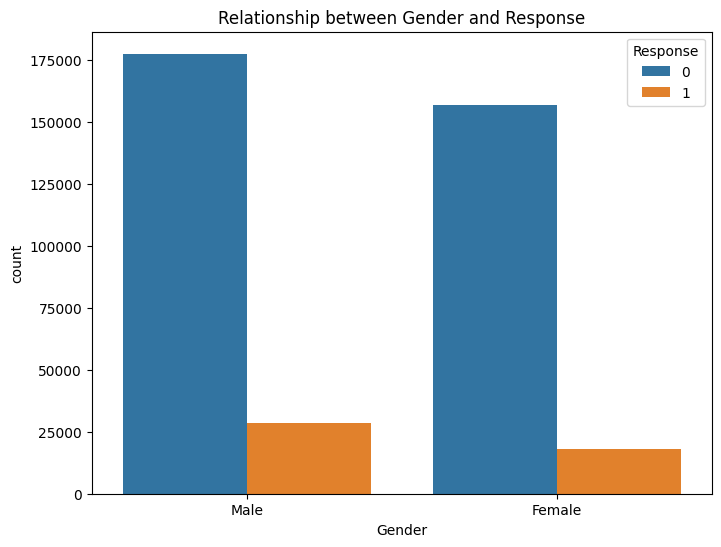

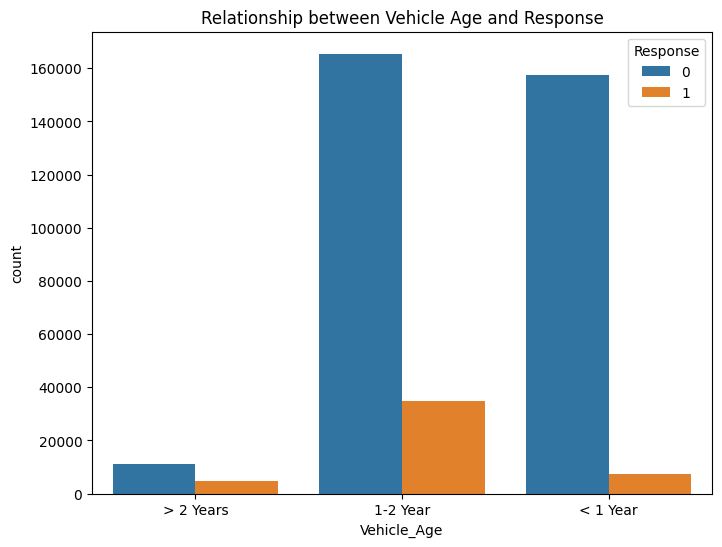

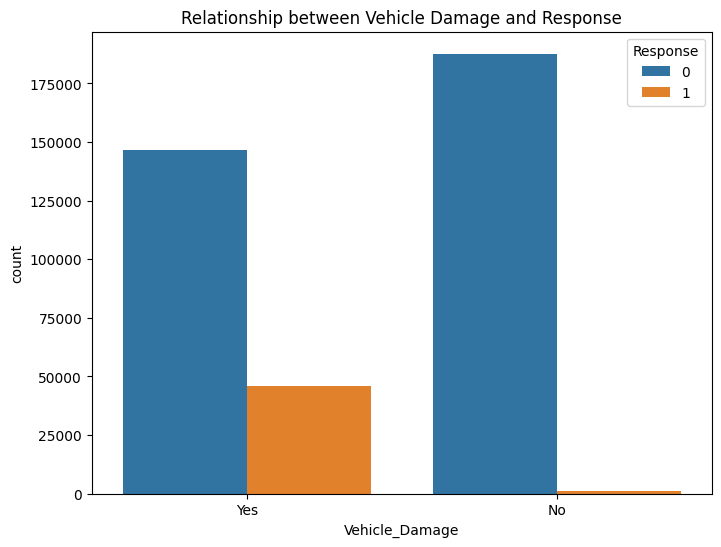

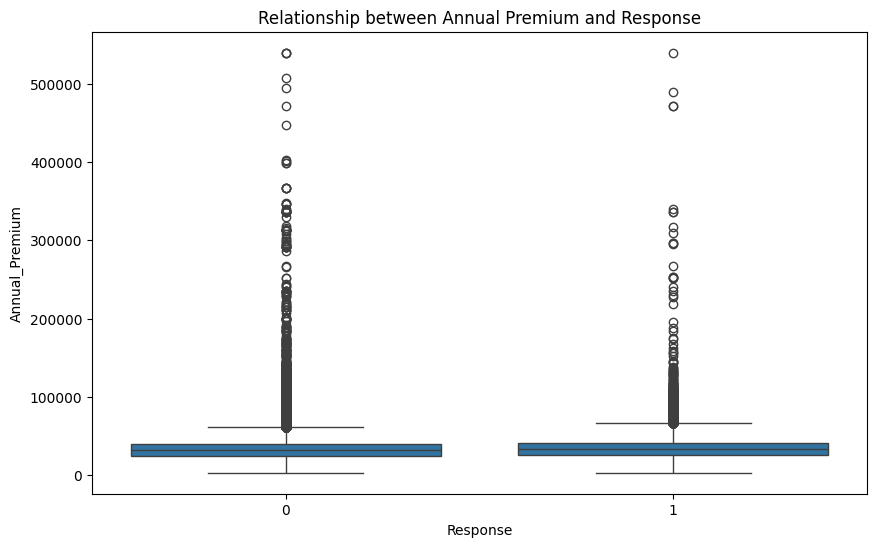

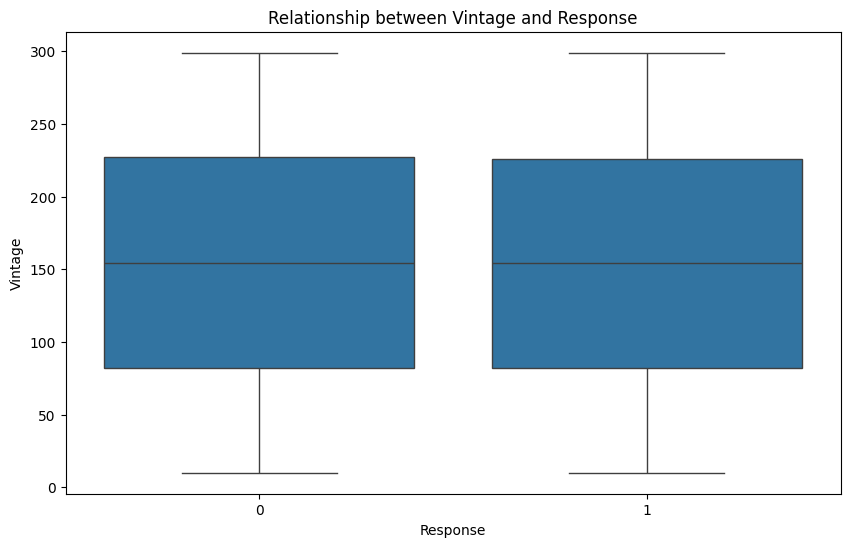

In [ ]:
# prompt: Perform bivariate analysis

import matplotlib.pyplot as plt
# Bivariate Analysis: Relationship between 'Previously_Insured' and 'Response'
plt.figure(figsize=(8, 6))
sns.countplot(x='Previously_Insured', hue='Response', data=train)
plt.title('Relationship between Previously Insured and Response')
plt.show()

# Calculate and print the percentage distribution for 'Response' based on 'Previously_Insured'
response_by_insured = train.groupby('Previously_Insured')['Response'].value_counts(normalize=True) * 100
print("Percentage Distribution of Response by Previously Insured:\n", response_by_insured)

#More bivariate analysis examples
#Gender vs Response
plt.figure(figsize=(8, 6))
sns.countplot(x='Gender', hue='Response', data=train)
plt.title('Relationship between Gender and Response')
plt.show()

#Vehicle Age vs Response
plt.figure(figsize=(8, 6))
sns.countplot(x='Vehicle_Age', hue='Response', data=train)
plt.title('Relationship between Vehicle Age and Response')
plt.show()

#Vehicle Damage vs Response
plt.figure(figsize=(8, 6))
sns.countplot(x='Vehicle_Damage', hue='Response', data=train)
plt.title('Relationship between Vehicle Damage and Response')
plt.show()

#Annual Premium vs Response (using a box plot)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Response', y='Annual_Premium', data=train)
plt.title('Relationship between Annual Premium and Response')
plt.show()

#Vintage vs Response
plt.figure(figsize=(10,6))
sns.boxplot(x='Response', y='Vintage', data=train)
plt.title('Relationship between Vintage and Response')
plt.show()


In [ ]:
#Coversion rate analysis
def ConversionRateCalc(cat_col):
    df_cr = train.copy()
    df_cr['Age_group'] = pd.cut(train['Age'], bins = [0, 18, 35, 50, 65, 100],
                                labels = ['0-18', '19-35', '36-50', '51-65', '66+'])
    df_cr['Annual_Premium_group'] = pd.cut(train['Annual_Premium'], bins = 5)
    df_cr['Vintage_group'] = pd.cut(train['Vintage'], bins = 3)
    grouped_by = df_cr.groupby(df_cr[cat_col])
    conversion_rate = grouped_by['Response'].mean() * 100
    conversion_rate_top5 = conversion_rate.sort_values(ascending = False).head(5)
    conversion_rate_top5_table = pd.DataFrame(conversion_rate_top5)
    return conversion_rate_top5_table
ConversionRateCalc('Gender')


,Response
Gender,
Male,13.841107
Female,10.390241


In [ ]:
ConversionRateCalc('Age_group')


<ipython-input-5-2f87de853e6e>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_by = df_cr.groupby(df_cr[cat_col])


,Response
Age_group,
36-50,21.332728
51-65,15.824721
66+,8.318786
19-35,6.554718
0-18,NaN


In [ ]:
ConversionRateCalc('Driving_License')


,Response
Driving_License,
1,12.271724
0,5.049261


In [ ]:
ConversionRateCalc('Region_Code')

,Response
Region_Code,
38.0,19.200395
28.0,18.716346
19.0,16.286645
4.0,15.824542
23.0,15.306122


In [ ]:
ConversionRateCalc('Previously_Insured')

,Response
Previously_Insured,
0,22.545416
1,0.090478


In [ ]:
ConversionRateCalc('Vehicle_Age')

,Response
Vehicle_Age,
> 2 Years,29.374649
1-2 Year,17.375547
< 1 Year,4.370517


In [ ]:
ConversionRateCalc('Vehicle_Damage')


,Response
Vehicle_Damage,
Yes,23.765546
No,0.520414


In [ ]:
ConversionRateCalc('Annual_Premium_group')


<ipython-input-5-2f87de853e6e>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_by = df_cr.groupby(df_cr[cat_col])


,Response
Annual_Premium_group,
"(432658.0, 540165.0]",36.363636
"(217644.0, 325151.0]",23.076923
"(110137.0, 217644.0]",14.173228
"(2092.465, 110137.0]",12.251890
"(325151.0, 432658.0]",12.000000


In [ ]:
ConversionRateCalc('Vintage_group')

<ipython-input-5-2f87de853e6e>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_by = df_cr.groupby(df_cr[cat_col])


,Response
Vintage_group,
"(106.333, 202.667]",12.289958
"(202.667, 299.0]",12.241767
"(9.711, 106.333]",12.237614


In [ ]:
ConversionRateCalc('Policy_Sales_Channel')


,Response
Policy_Sales_Channel,
123.0,100.000000
43.0,100.000000
27.0,33.333333
28.0,33.333333
36.0,32.692308


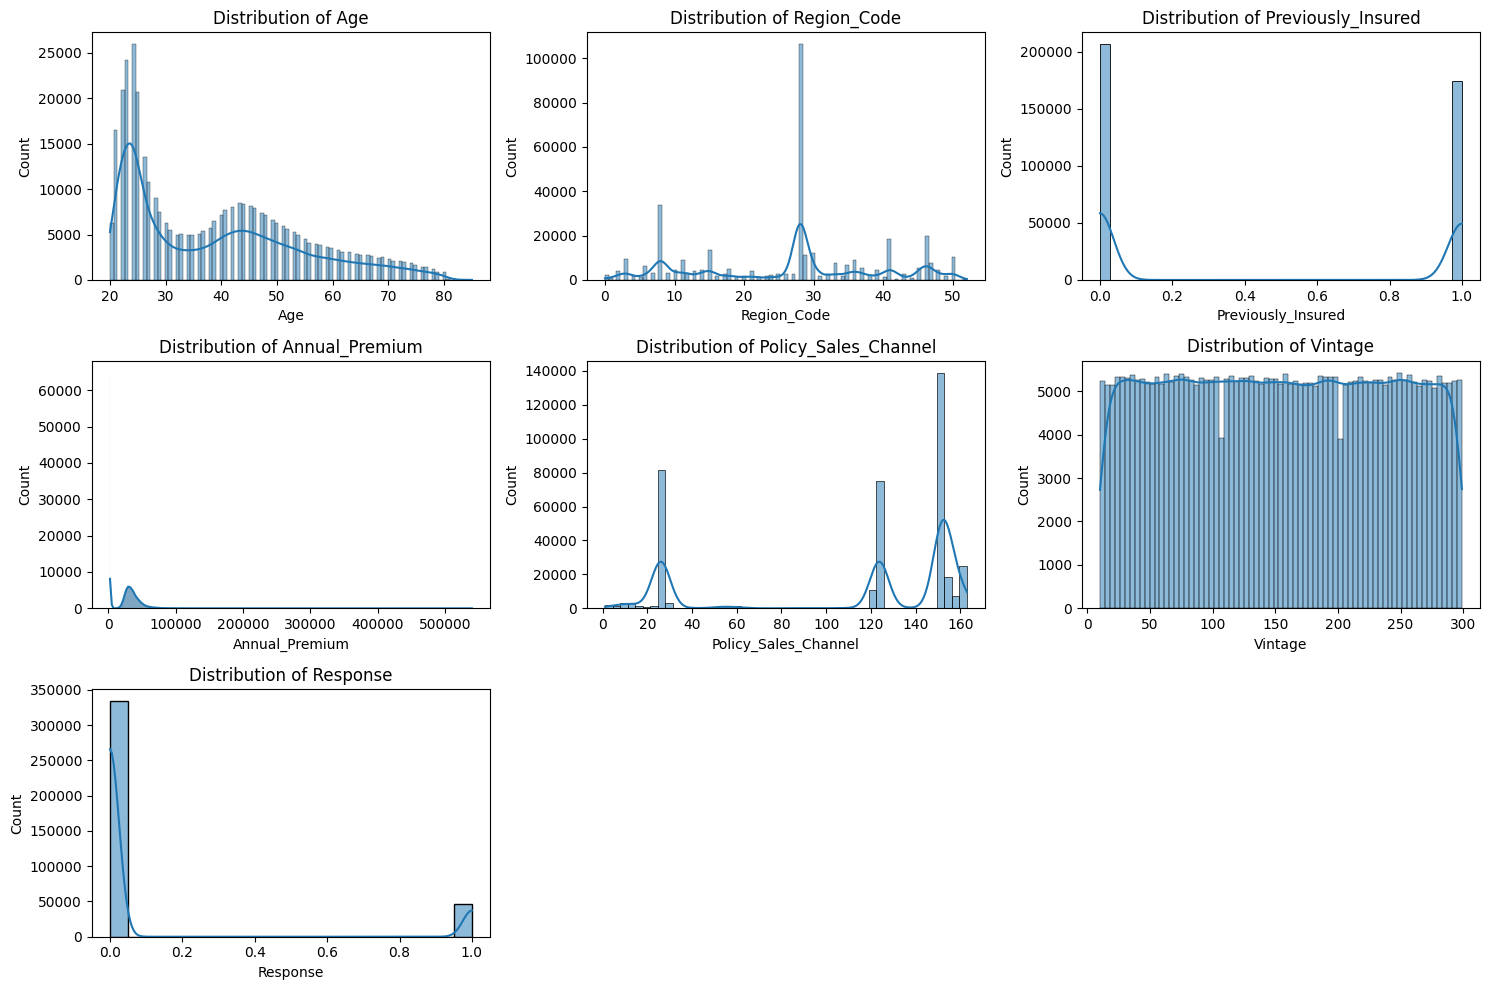

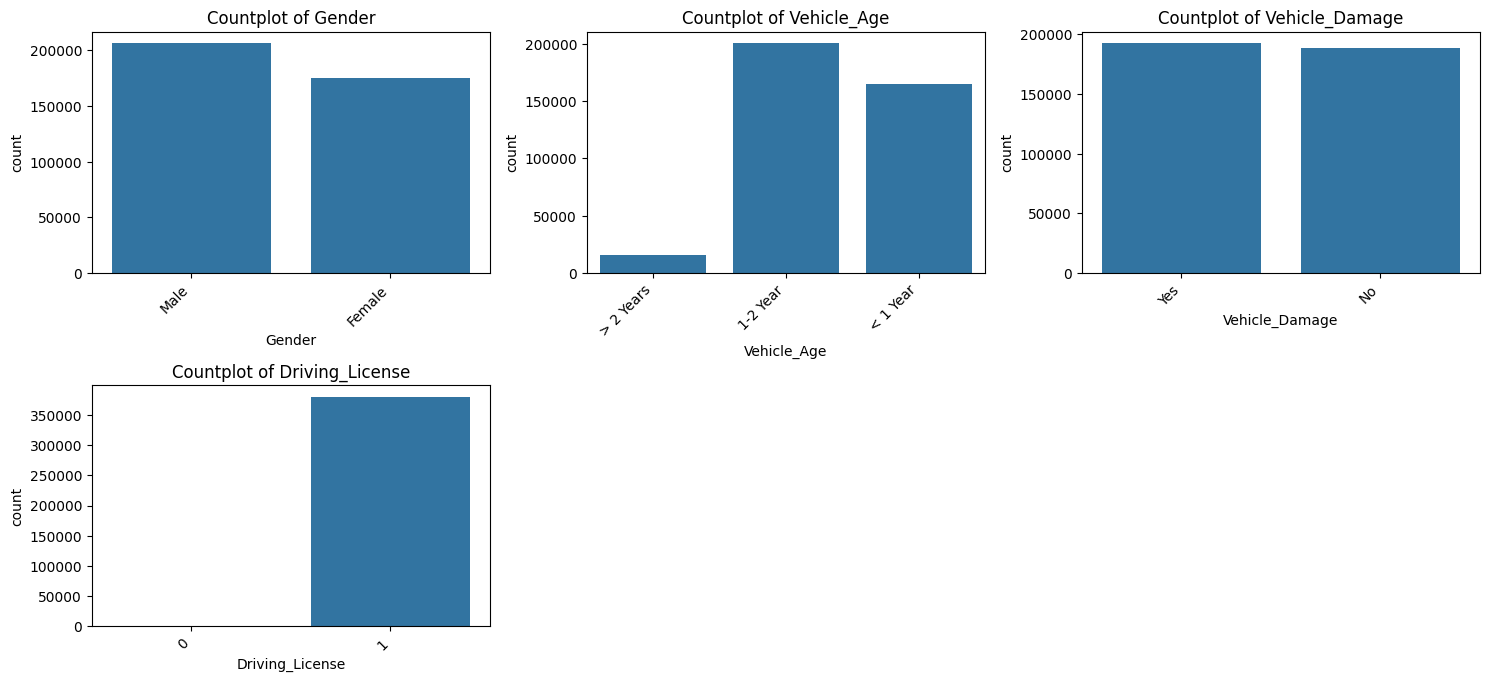

In [ ]:
# prompt: Visualize the train data separately for numerical columns  and categorical varaiables including driving lincense it should come under categorical

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'train' DataFrame is already loaded as in the previous code

# Identify numerical and categorical columns
numerical_cols = train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = train.select_dtypes(exclude=np.number).columns.tolist()

# Ensure 'Driving_License' is treated as categorical
if 'Driving_License' in numerical_cols:
    numerical_cols.remove('Driving_License')
    categorical_cols.append('Driving_License')


# Visualize numerical columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)  # Adjust subplot grid if necessary
    sns.histplot(train[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


# Visualize categorical columns
plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)  # Adjust subplot grid if necessary
    sns.countplot(x=col, data=train)
    plt.title(f'Countplot of {col}')
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels if needed
plt.tight_layout()
plt.show()


Categorical features analysis in train dataset:


<ipython-input-7-b1a2aa284938>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=train, palette="Set2")


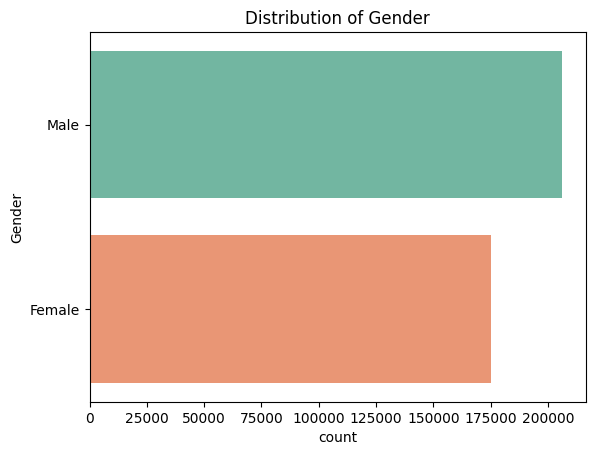

<ipython-input-7-b1a2aa284938>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=train, palette="Set2")


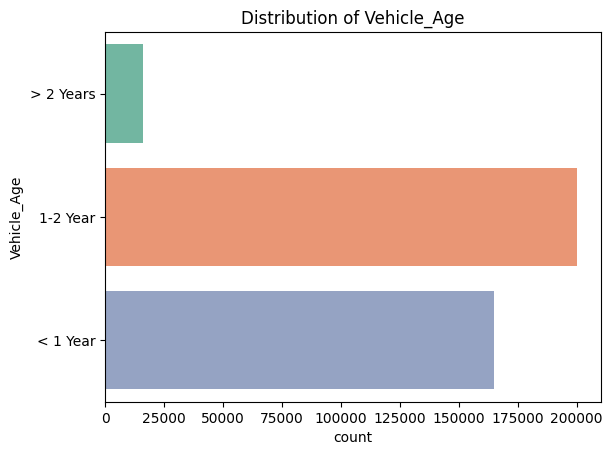

<ipython-input-7-b1a2aa284938>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=train, palette="Set2")


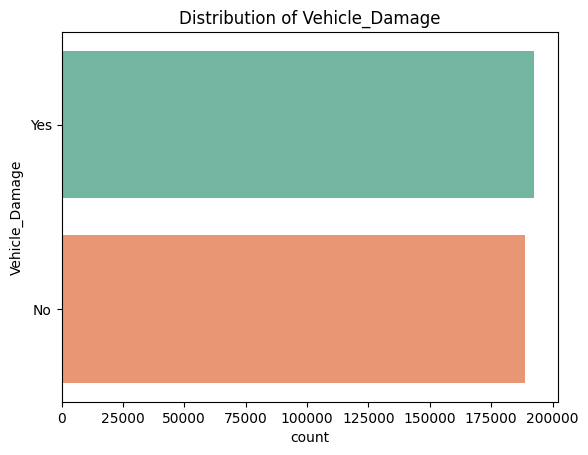

In [ ]:
print(f"\nCategorical features analysis in train dataset:")
for col in train.select_dtypes(include=['object']).columns:
    sns.countplot(y=col, data=train, palette="Set2")
    plt.title(f'Distribution of {col}')
    plt.show()

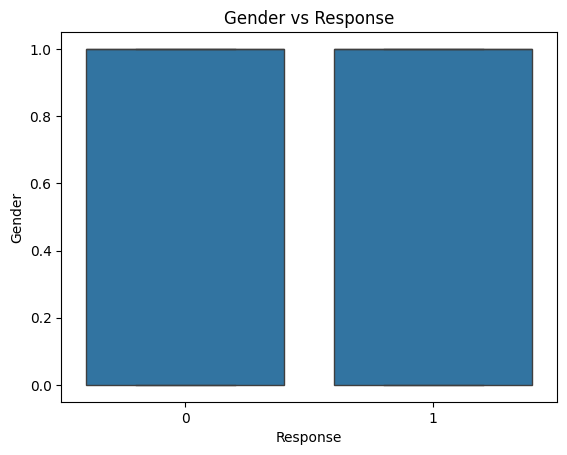

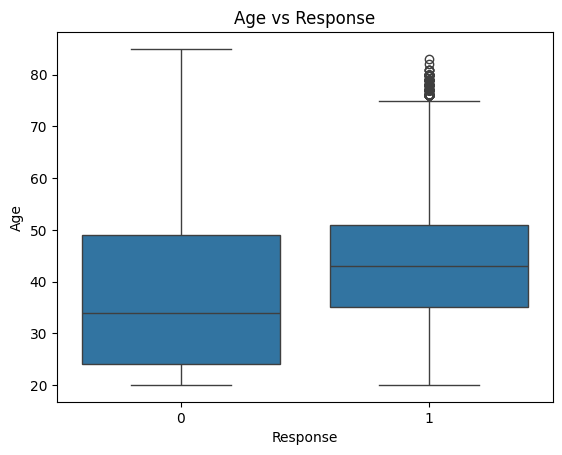

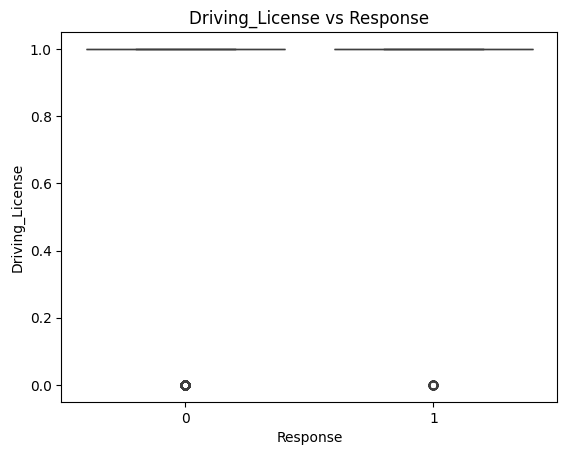

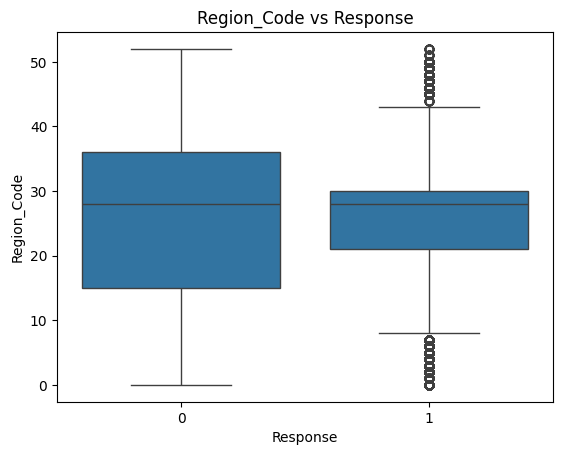

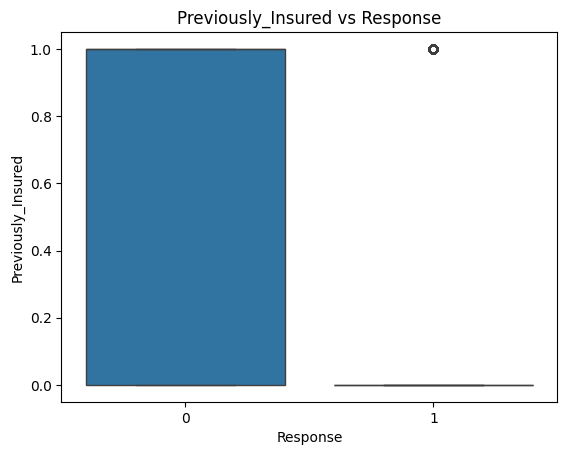

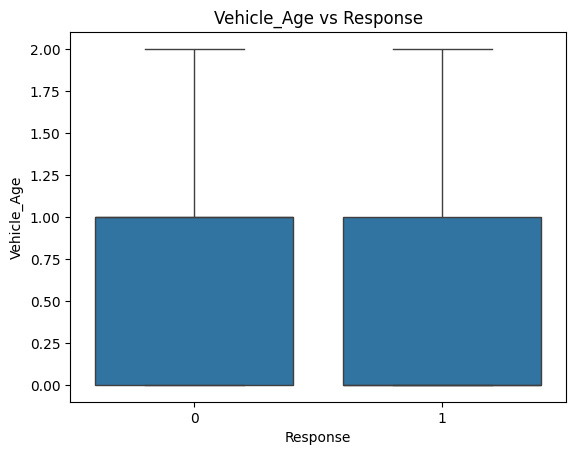

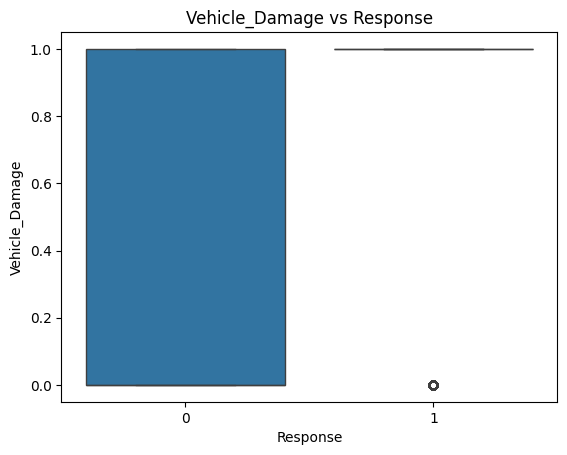

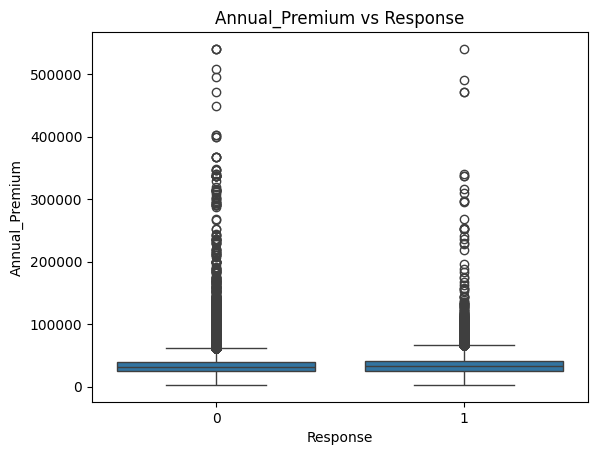

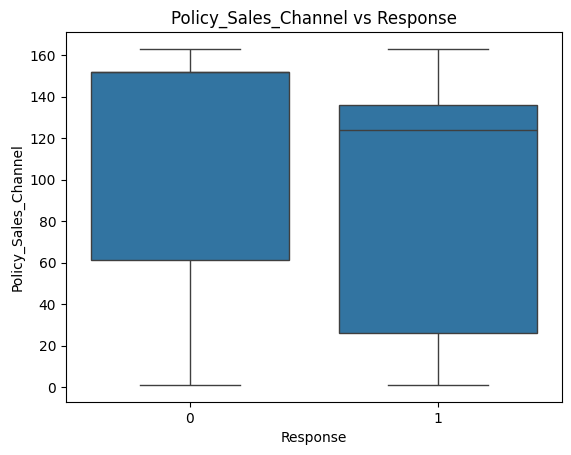

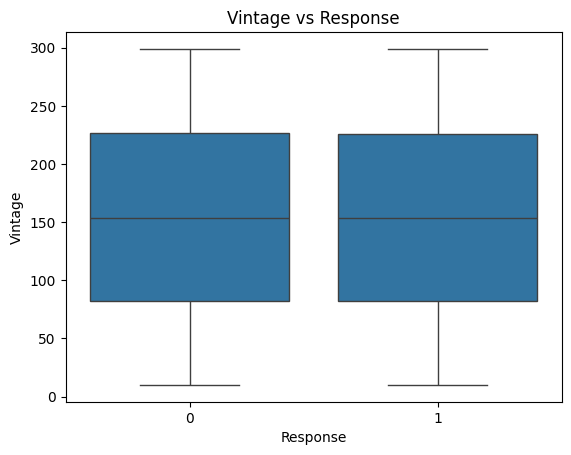

In [ ]:
#BIVARIATE ANALYSIS
for col in train.select_dtypes(include=['float64', 'int64']).columns:
    if col != 'Response':
        sns.boxplot(x= train['Response'], y=col, data=train)
        plt.title(f'{col} vs Response')
        plt.show()

In [ ]:
#IMPORTING TEST DATA
test= pd.read_csv("/content/test.csv")
print(test.head())

       id Gender  Age  Driving_License  Region_Code  Previously_Insured  \
0  381110   Male   25                1         11.0                   1   
1  381111   Male   40                1         28.0                   0   
2  381112   Male   47                1         28.0                   0   
3  381113   Male   24                1         27.0                   1   
4  381114   Male   27                1         28.0                   1   

  Vehicle_Age Vehicle_Damage  Annual_Premium  Policy_Sales_Channel  Vintage  
0    < 1 Year             No         35786.0                 152.0       53  
1    1-2 Year            Yes         33762.0                   7.0      111  
2    1-2 Year            Yes         40050.0                 124.0      199  
3    < 1 Year            Yes         37356.0                 152.0      187  
4    < 1 Year             No         59097.0                 152.0      297  


In [ ]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127037 entries, 0 to 127036
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    127037 non-null  int64  
 1   Gender                127037 non-null  object 
 2   Age                   127037 non-null  int64  
 3   Driving_License       127037 non-null  int64  
 4   Region_Code           127037 non-null  float64
 5   Previously_Insured    127037 non-null  int64  
 6   Vehicle_Age           127037 non-null  object 
 7   Vehicle_Damage        127037 non-null  object 
 8   Annual_Premium        127037 non-null  float64
 9   Policy_Sales_Channel  127037 non-null  float64
 10  Vintage               127037 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 10.7+ MB


In [ ]:
test.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage
count,127037.000000,127037.000000,127037.000000,127037.000000,127037.000000,127037.000000,127037.000000,127037.000000
mean,444628.000000,38.765903,0.998134,26.459866,0.460039,30524.643576,111.800468,154.318301
std,36672.567411,15.465814,0.043152,13.209916,0.498403,16945.297103,54.371765,83.661588
min,381110.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000
25%,412869.000000,25.000000,1.000000,15.000000,0.000000,24325.000000,26.000000,82.000000
50%,444628.000000,36.000000,1.000000,28.000000,0.000000,31642.000000,135.000000,154.000000
75%,476387.000000,49.000000,1.000000,35.000000,1.000000,39408.000000,152.000000,227.000000
max,508146.000000,85.000000,1.000000,52.000000,1.000000,472042.000000,163.000000,299.000000


In [ ]:
test.isnull().sum()

,0
id,0
Gender,0
Age,0
Driving_License,0
Region_Code,0
Previously_Insured,0
Vehicle_Age,0
Vehicle_Damage,0
Annual_Premium,0
Policy_Sales_Channel,0


In [ ]:
test.shape

(127037, 11)

In [ ]:
test = test.drop('id',axis=1)

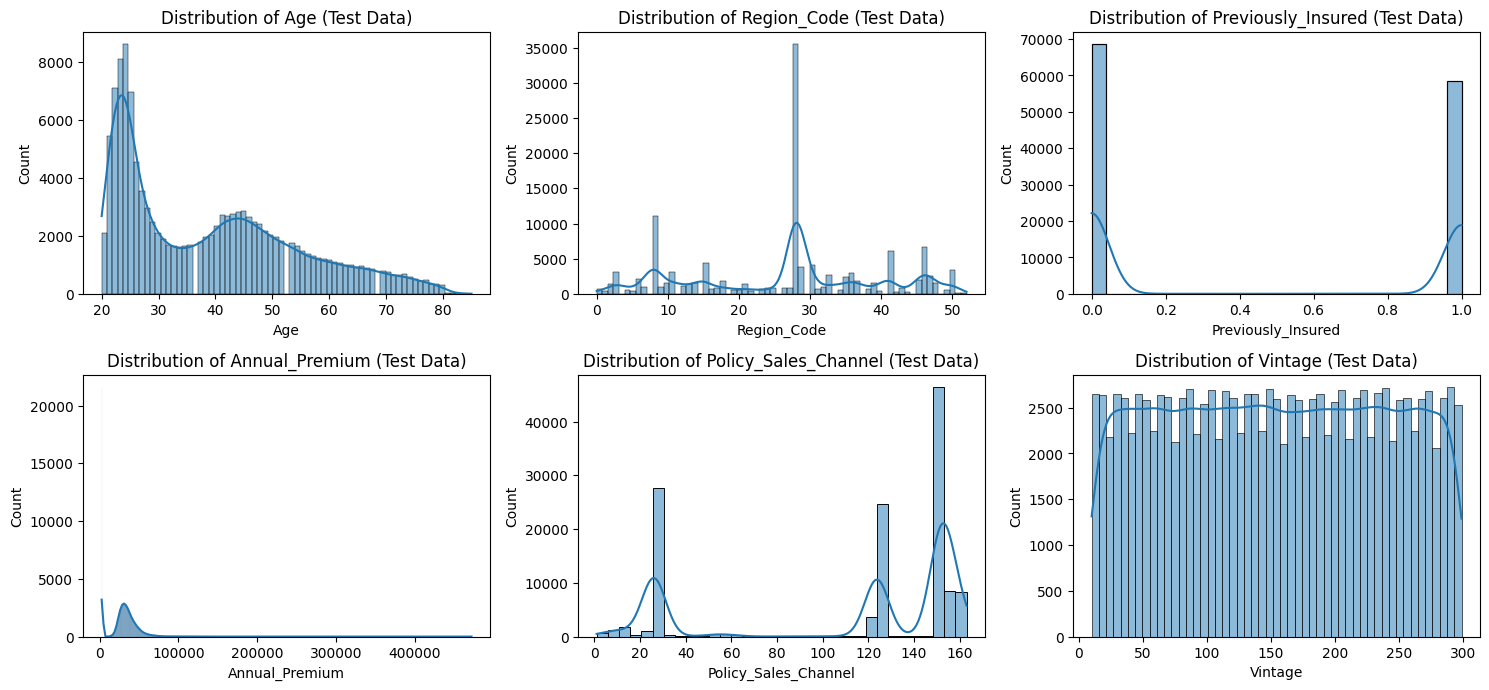

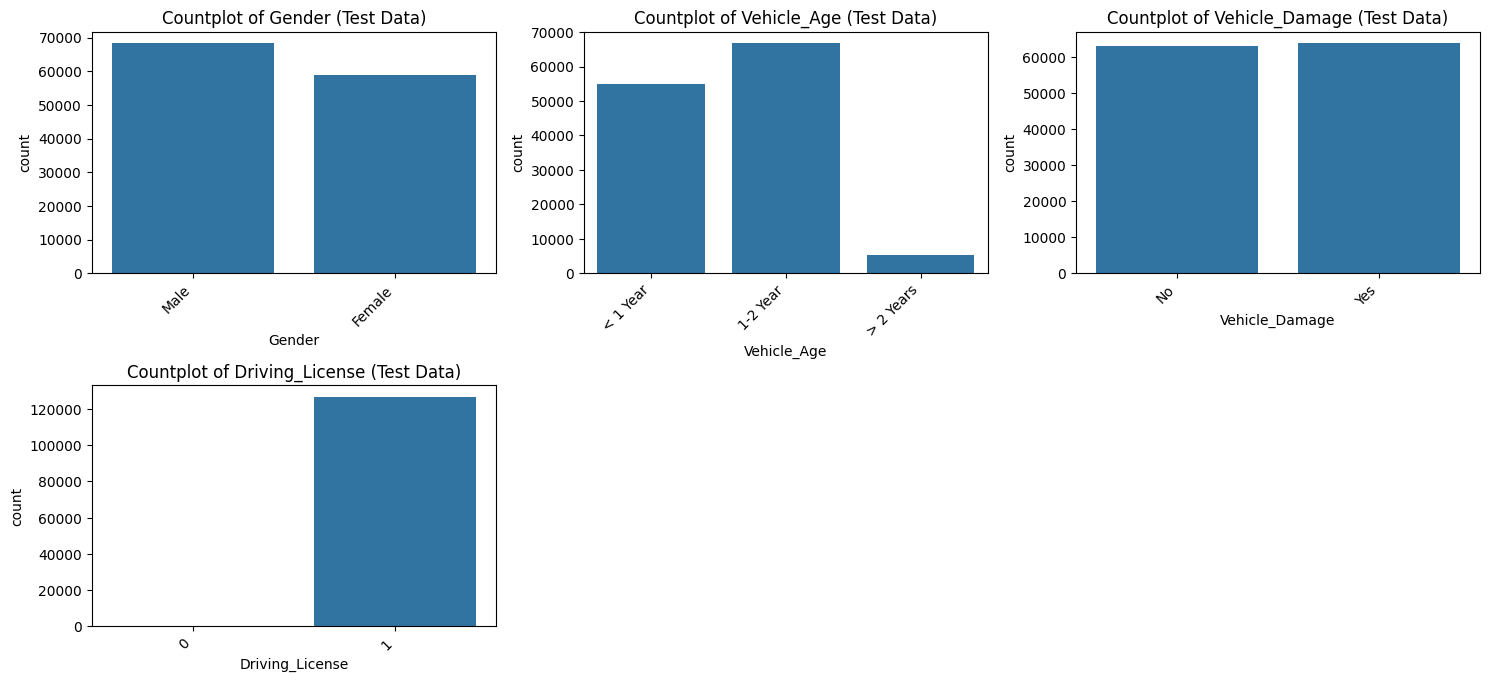


Categorical features analysis in test dataset:


<ipython-input-30-e1efead42f1d>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=test, palette="Set2")


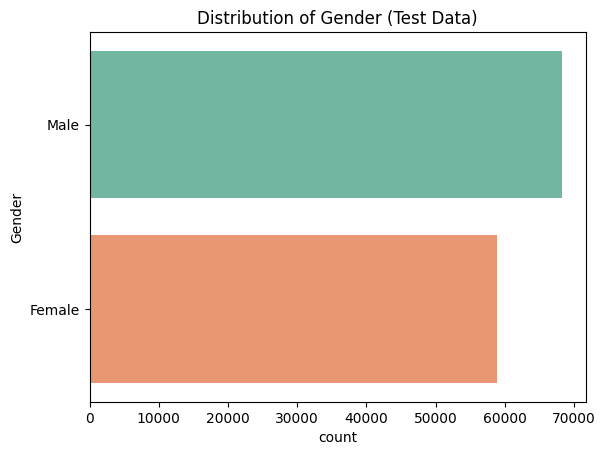

<ipython-input-30-e1efead42f1d>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=test, palette="Set2")


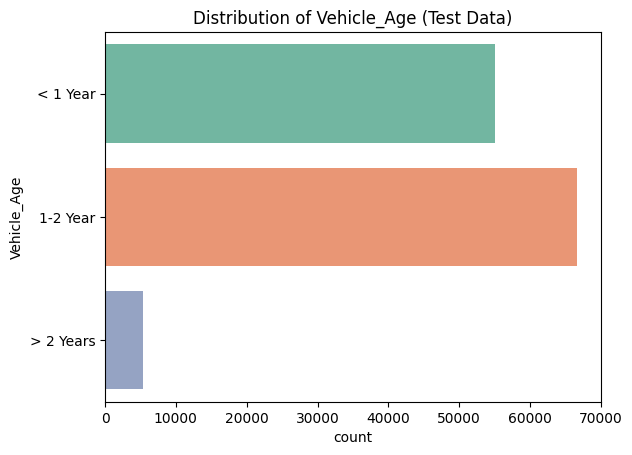

<ipython-input-30-e1efead42f1d>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=test, palette="Set2")


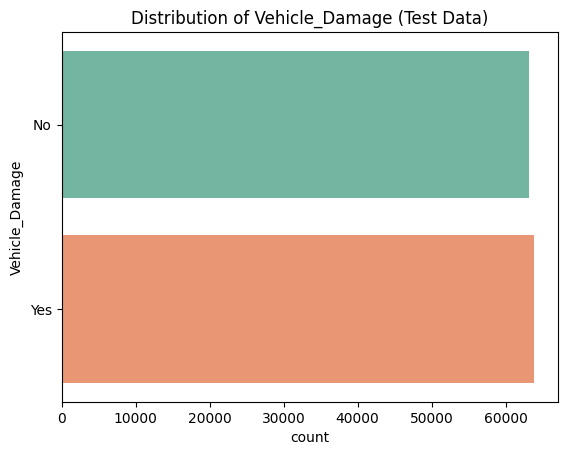

In [ ]:
# prompt: Visualize the test data separately for numerical columns  and categorical varaiables including driving lincense it should come under categorical

# Assuming 'test' DataFrame is already loaded as in the previous code

# Identify numerical and categorical columns in the test dataset
numerical_cols_test = test.select_dtypes(include=np.number).columns.tolist()
categorical_cols_test = test.select_dtypes(exclude=np.number).columns.tolist()

# Ensure 'Driving_License' is treated as categorical in the test dataset
if 'Driving_License' in numerical_cols_test:
    numerical_cols_test.remove('Driving_License')
    categorical_cols_test.append('Driving_License')


# Visualize numerical columns in the test dataset
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols_test):
    plt.subplot(3, 3, i + 1)  # Adjust subplot grid if necessary
    sns.histplot(test[col], kde=True)
    plt.title(f'Distribution of {col} (Test Data)')
plt.tight_layout()
plt.show()


# Visualize categorical columns in the test dataset
plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols_test):
    plt.subplot(3, 3, i + 1)  # Adjust subplot grid if necessary
    sns.countplot(x=col, data=test)
    plt.title(f'Countplot of {col} (Test Data)')
    plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels if needed
plt.tight_layout()
plt.show()

print(f"\nCategorical features analysis in test dataset:")
for col in test.select_dtypes(include=['object']).columns:
    sns.countplot(y=col, data=test, palette="Set2")
    plt.title(f'Distribution of {col} (Test Data)')
    plt.show()

In [ ]:
#ENCODING
le = LabelEncoder()

le = LabelEncoder()
categorical_columns = ['Gender', 'Vehicle_Age', 'Vehicle_Damage']

for col in categorical_columns:
    le.fit(train[col])
    train[col] = le.transform(train[col])


In [ ]:
#ENCODING
le = LabelEncoder()

le = LabelEncoder()
categorical_columns = ['Gender', 'Vehicle_Age', 'Vehicle_Damage']

for col in categorical_columns:
    le.fit(test[col])
    test[col] = le.transform(test[col])

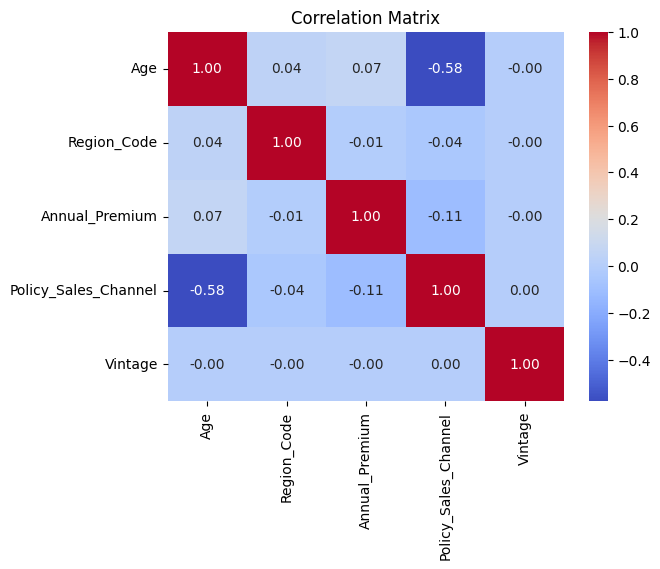

In [ ]:
data=train[["Age",'Region_Code',"Annual_Premium","Policy_Sales_Channel","Vintage"]]
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

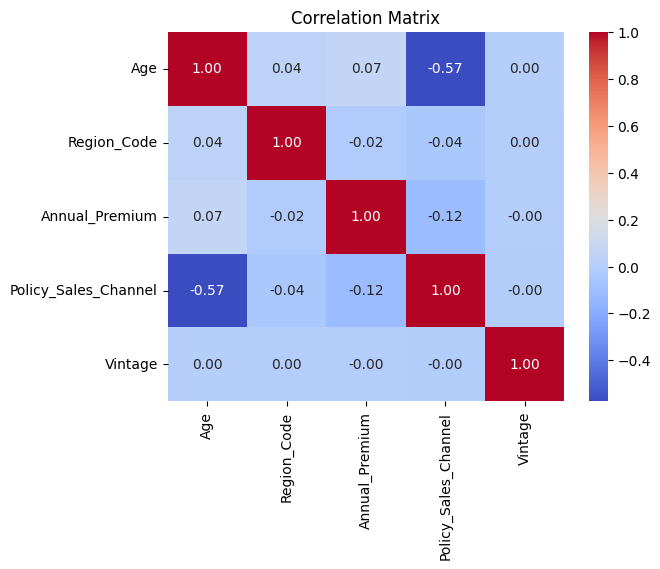

In [ ]:
data=test[["Age",'Region_Code',"Annual_Premium","Policy_Sales_Channel","Vintage"]]
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

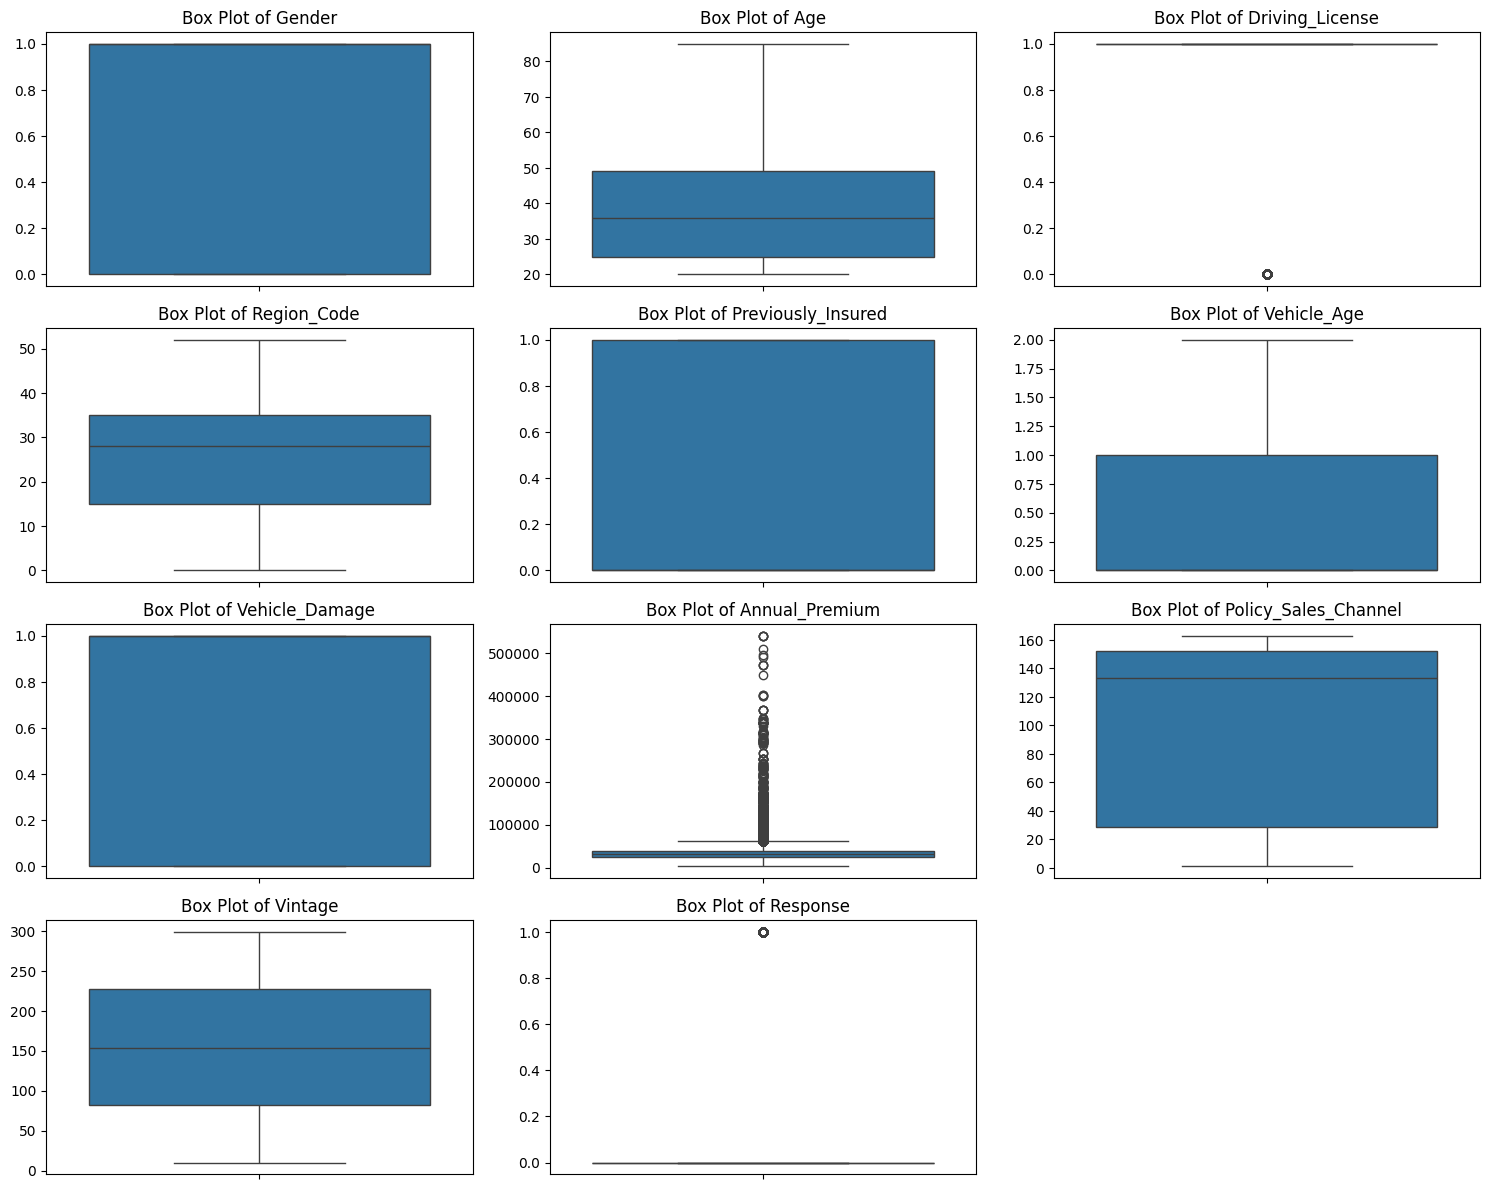

In [ ]:
# Box plots for all numerical features to visualize outliers
plt.figure(figsize=(15, 12))

# Calculate the number of rows and columns for the subplot grid
num_cols = train.select_dtypes(include=np.number).shape[1]
num_rows = int(np.ceil(num_cols / 3))  # Calculate rows to fit all columns

for i, col in enumerate(train.select_dtypes(include=np.number).columns):
    plt.subplot(num_rows, 3, i + 1)  # Adjust grid size dynamically
    sns.boxplot(y=train[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# prompt: Remove outliers from the above data with columns having outliers using iqr method

def remove_outliers_iqr(df, columns):
    df_cleaned = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]
    return df_cleaned

# Example usage (replace with your actual column names):
numerical_cols_with_outliers = ['Annual_Premium']
train_no_outliers = remove_outliers_iqr(train, numerical_cols_with_outliers)

# Now train_no_outliers contains the data with outliers removed
print(train_no_outliers.head())

   Gender  Age  Driving_License  Region_Code  Previously_Insured  Vehicle_Age  \
0       1   44                1         28.0                   0            2   
1       1   76                1          3.0                   0            0   
2       1   47                1         28.0                   0            2   
3       1   21                1         11.0                   1            1   
4       0   29                1         41.0                   1            1   

   Vehicle_Damage  Annual_Premium  Policy_Sales_Channel  Vintage  Response  
0               1         40454.0                  26.0      217         1  
1               0         33536.0                  26.0      183         0  
2               1         38294.0                  26.0       27         1  
3               0         28619.0                 152.0      203         0  
4               0         27496.0                 152.0       39         0  


In [ ]:
train_no_outliers.shape

(370789, 11)

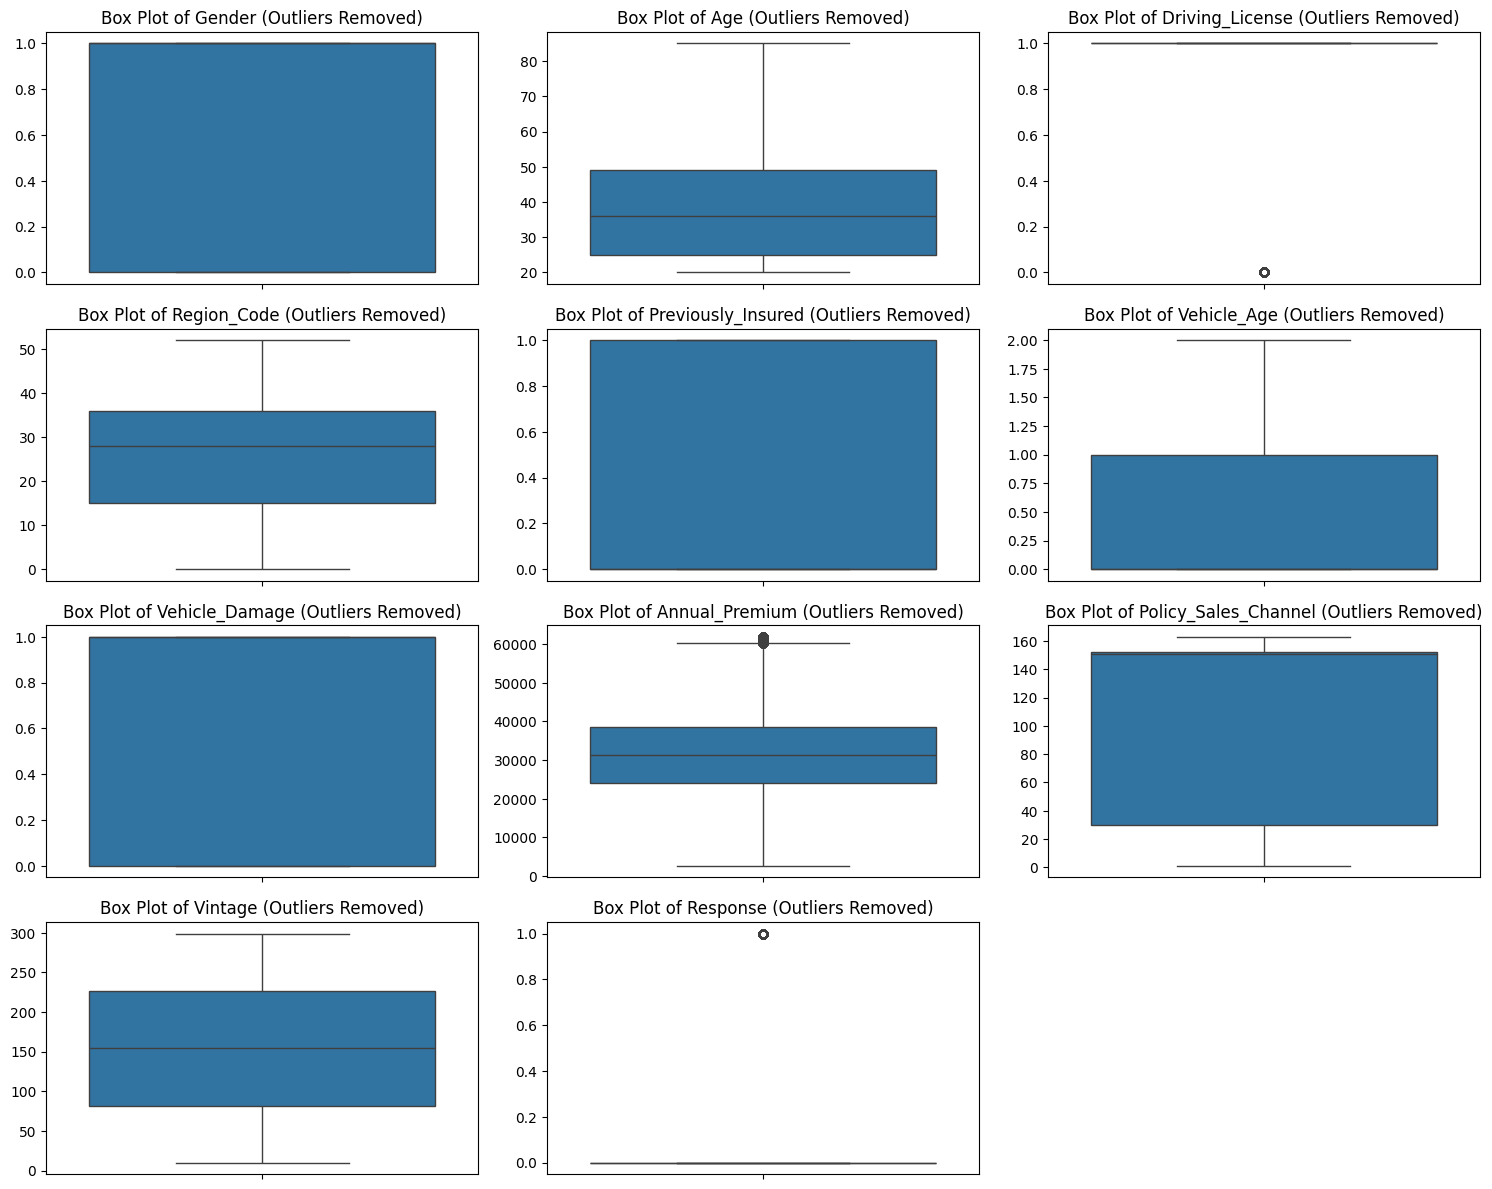

In [ ]:
# prompt: Visualize the data without outliers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming train_no_outliers DataFrame is already created as in your previous code

plt.figure(figsize=(15, 12))
num_cols = train_no_outliers.select_dtypes(include=np.number).shape[1]
num_rows = int(np.ceil(num_cols / 3))

for i, col in enumerate(train_no_outliers.select_dtypes(include=np.number).columns):
    plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=train_no_outliers[col])
    plt.title(f'Box Plot of {col} (Outliers Removed)')
    plt.ylabel('')

plt.tight_layout()
plt.show()

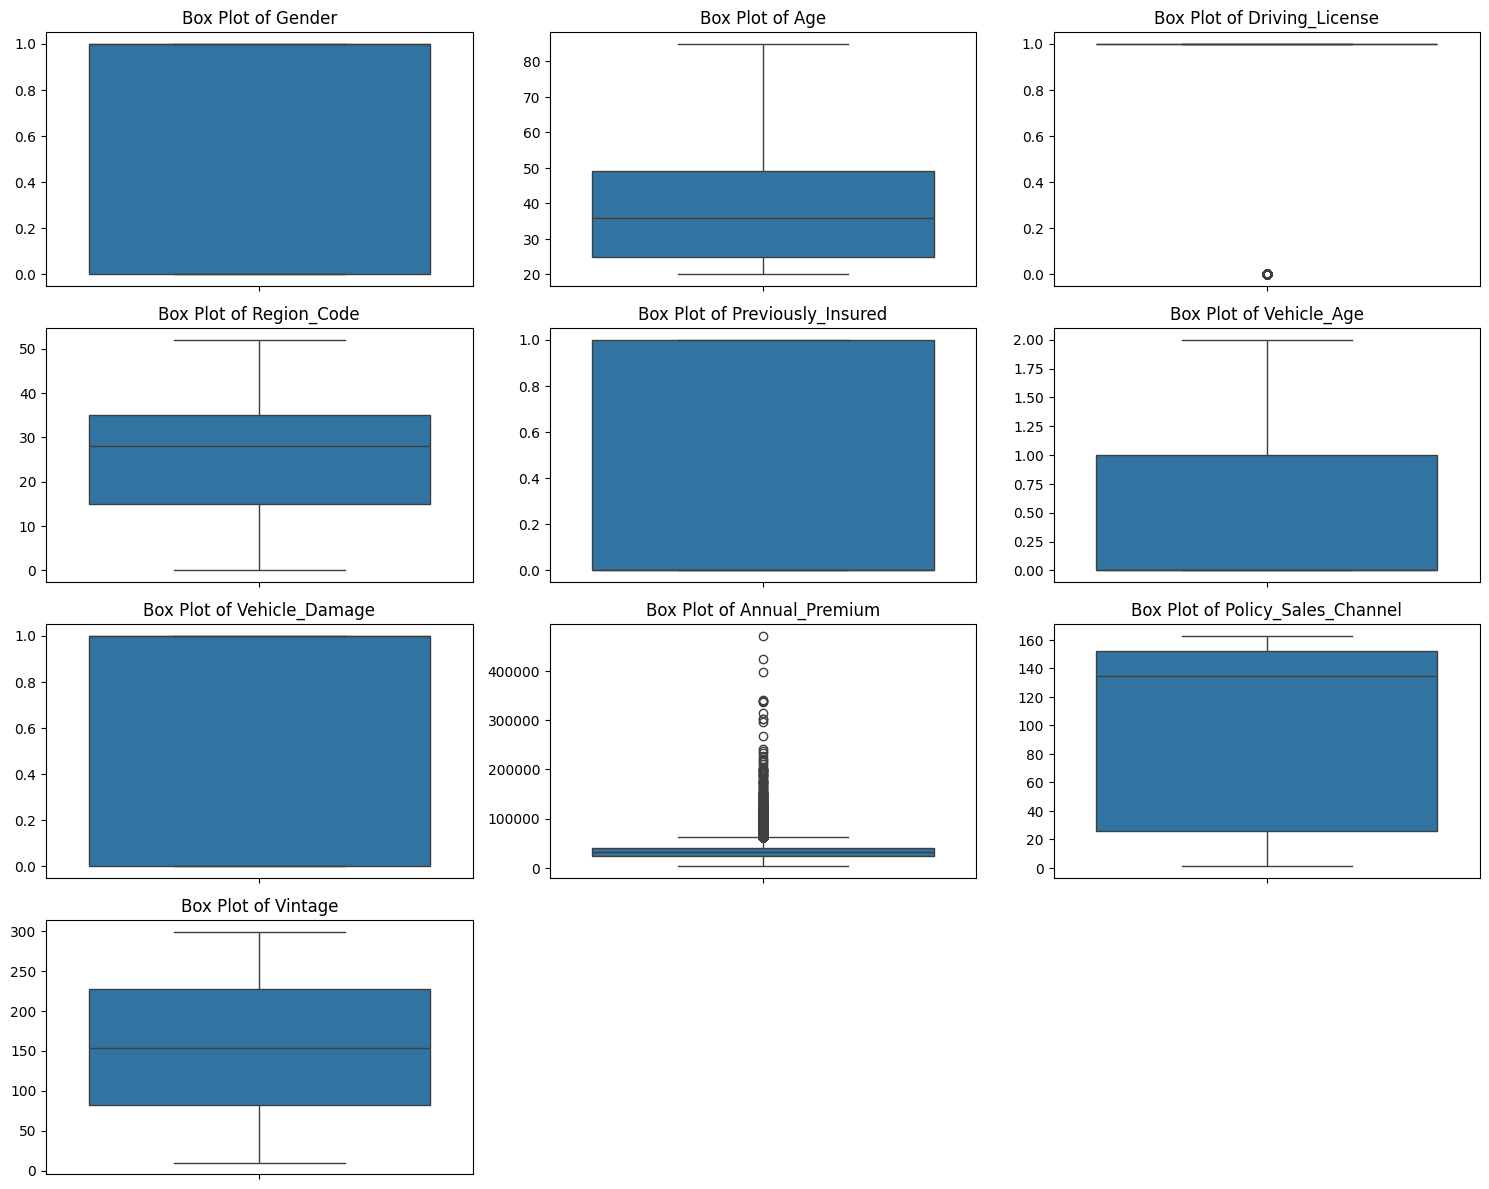

In [ ]:
# Box plots for all numerical features to visualize outliers
plt.figure(figsize=(15, 12))

# Calculate the number of rows and columns for the subplot grid
num_cols = test.select_dtypes(include=np.number).shape[1]
num_rows = int(np.ceil(num_cols / 3))  # Calculate rows to fit all columns

for i, col in enumerate(test.select_dtypes(include=np.number).columns):
    plt.subplot(num_rows, 3, i + 1)  # Adjust grid size dynamically
    sns.boxplot(y=test[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# prompt: Remove outliers from the above data with columns having outliers using iqr method

def remove_outliers_iqr(df, columns):
    df_cleaned = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]
    return df_cleaned

# Example usage (replace with your actual column names):
numerical_cols_with_outliers = ['Annual_Premium']
test_no_outliers = remove_outliers_iqr(test, numerical_cols_with_outliers)

# Now test_no_outliers contains the data with outliers removed
print(test_no_outliers.head())

       id  Gender  Age  Driving_License  Region_Code  Previously_Insured  \
0  381110       1   25                1         11.0                   1   
1  381111       1   40                1         28.0                   0   
2  381112       1   47                1         28.0                   0   
3  381113       1   24                1         27.0                   1   
4  381114       1   27                1         28.0                   1   

   Vehicle_Age  Vehicle_Damage  Annual_Premium  Policy_Sales_Channel  Vintage  
0            1               0         35786.0                 152.0       53  
1            0               1         33762.0                   7.0      111  
2            0               1         40050.0                 124.0      199  
3            1               1         37356.0                 152.0      187  
4            1               0         59097.0                 152.0      297  


In [ ]:
test_no_outliers.shape

(123667, 10)

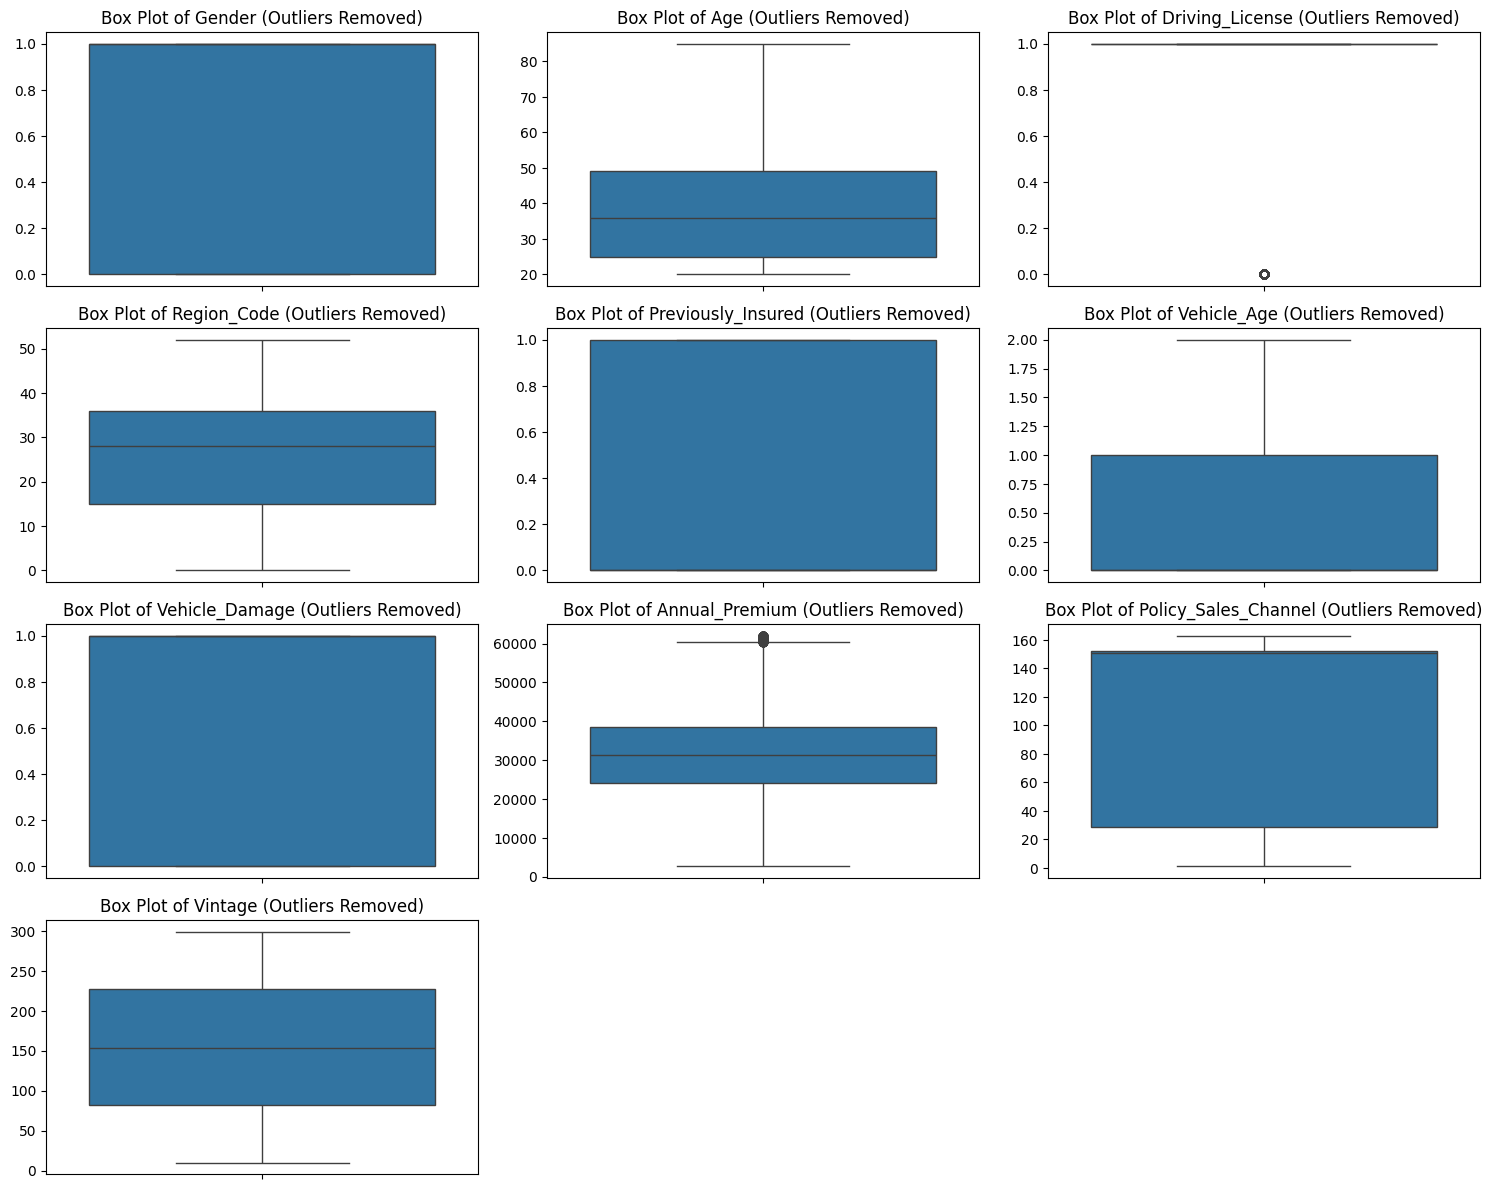

In [ ]:
# prompt: Visualize the data without outliers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming test_no_outliers DataFrame is already created as in your previous code

plt.figure(figsize=(15, 12))
num_cols = test_no_outliers.select_dtypes(include=np.number).shape[1]
num_rows = int(np.ceil(num_cols / 3))

for i, col in enumerate(test_no_outliers.select_dtypes(include=np.number).columns):
    plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=test_no_outliers[col])
    plt.title(f'Box Plot of {col} (Outliers Removed)')
    plt.ylabel('')

plt.tight_layout()
plt.show()

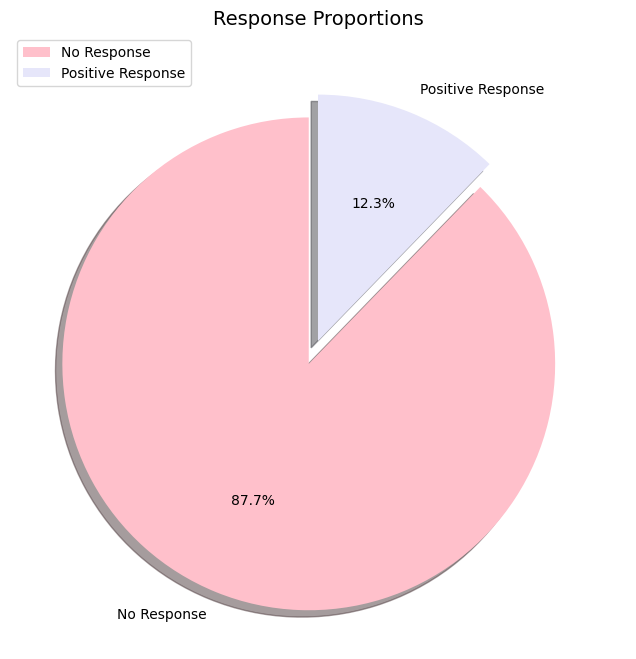

In [ ]:
if 'Response' in train.columns and train['Response'].nunique() > 1:
    response_counts = train['Response'].value_counts()

    plt.figure(figsize=(8, 8))
    explode = (0.1, 0)

    plt.pie(response_counts, labels=['No Response', 'Positive Response'], autopct='%1.1f%%',
            colors=['pink','lavender'], startangle=90, shadow=True, explode=explode)

    plt.title('Response Proportions', fontsize=14)
    plt.legend(loc="best")
    plt.show()
else:
    print("The 'Response' column is missing or does not have enough categories to plot.")

In [ ]:
scaled_features = ['Age','Region_Code','Annual_Premium', 'Vintage','Policy_Sales_Channel']
test_no_outliers[scaled_features] = scaler.fit_transform(test_no_outliers[scaled_features])

# BALANCING THE DATASET

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

# Normalize/Scale numeric features
scaler = StandardScaler()
scaled_features = ['Age','Region_Code','Annual_Premium', 'Vintage','Policy_Sales_Channel']
train_no_outliers[scaled_features] = scaler.fit_transform(train_no_outliers[scaled_features])

# Split features and target variable
X = train_no_outliers.drop(columns='Response')  # Drop ID and target column
y = train_no_outliers['Response']

# Balance the dataset using SMOTE
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X, y)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_balanced, y_balanced, test_size=0.2, random_state=42)

# Display the shapes of the resulting datasets
print("Training Features Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

Training Features Shape: (521014, 10)
Training Labels Shape: (521014,)
Testing Features Shape: (130254, 10)
Testing Labels Shape: (130254,)


ValueError: num must be an integer with 1 <= num <= 9, not 10

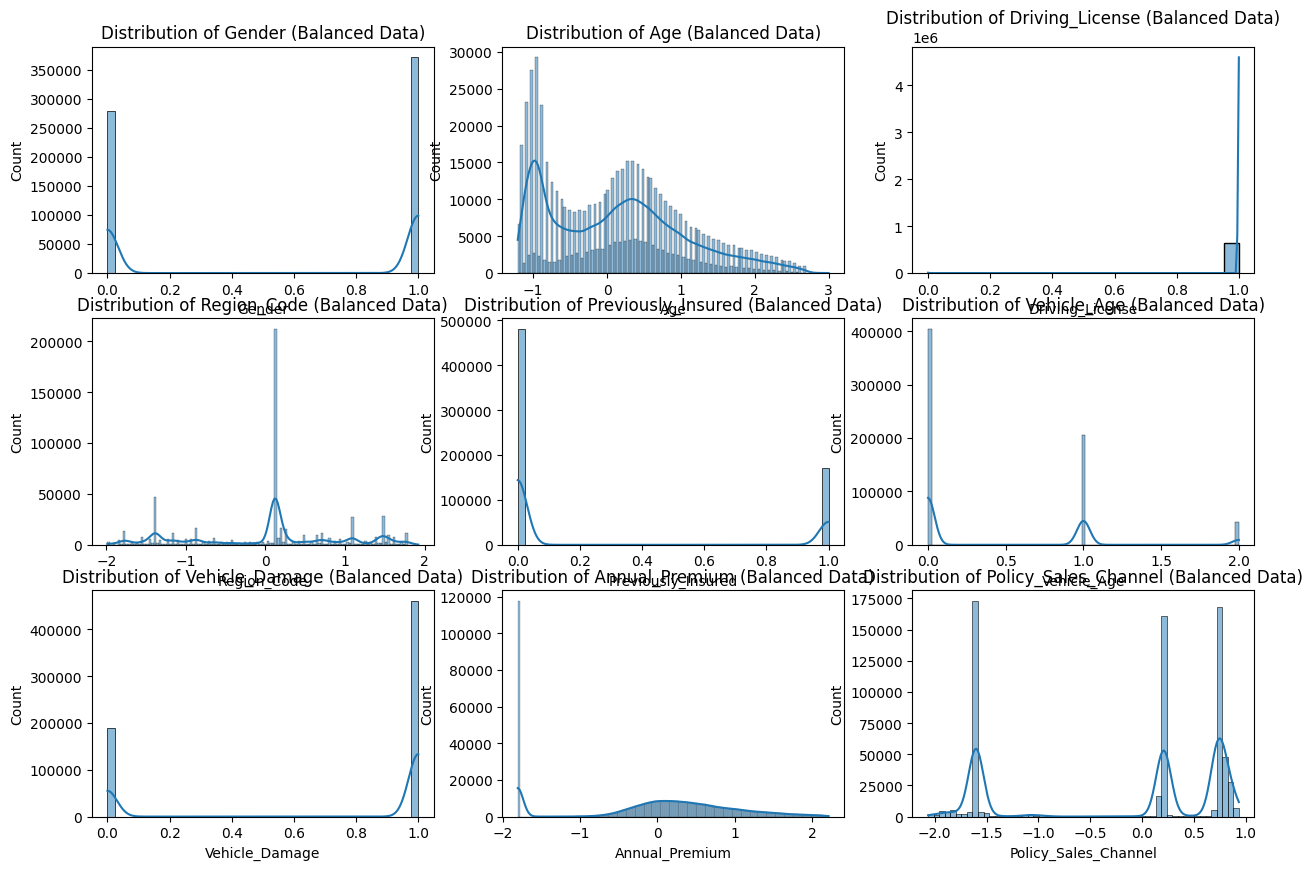

In [ ]:
# prompt: Univariate and bivariate analysis after balancing the data
numerical_cols = X_balanced.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_balanced.select_dtypes(exclude=np.number).columns.tolist()

import matplotlib.pyplot as plt
# Univariate analysis for balanced data
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(X_balanced[col], kde=True)  # Use X_balanced for balanced data
    plt.title(f'Distribution of {col} (Balanced Data)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)
    sns.countplot(x=col, data=X_balanced)  # Use X_balanced for balanced data
    plt.title(f'Countplot of {col} (Balanced Data)')
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Bivariate analysis for balanced data
for col in X_balanced.select_dtypes(include=['float64', 'int64']).columns:
    sns.boxplot(x=y_balanced, y=X_balanced[col], data=X_balanced) # Use X_balanced and y_balanced
    plt.title(f'{col} vs Response (Balanced Data)')
    plt.show()

# You can also calculate and print the percentage distribution of the 'Response' variable after balancing
y_balanced_counts = y_balanced.value_counts(normalize=True) * 100
print("Percentage Distribution of Response (Balanced Data):\n", y_balanced_counts)


ValueError: num must be an integer with 1 <= num <= 9, not 10

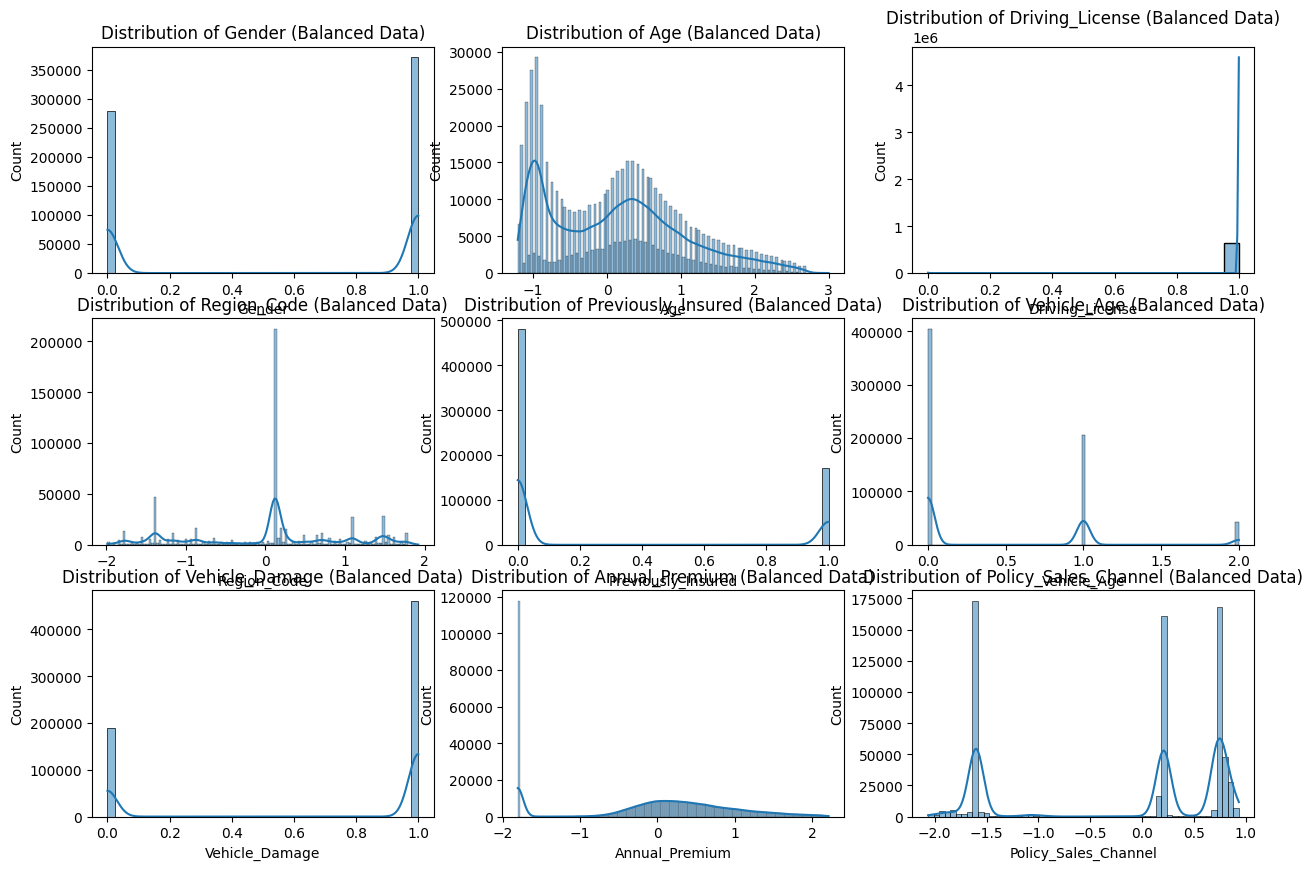

In [ ]:
# prompt: Univariate analysis for balanced data with no negative

import matplotlib.pyplot as plt
# Assuming X_balanced and y_balanced are already defined as in your previous code

# Univariate analysis for balanced data (Numerical Features)
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(X_balanced[col], kde=True)  # Use X_balanced for balanced data
    plt.title(f'Distribution of {col} (Balanced Data)')
plt.tight_layout()
plt.show()

# Univariate analysis for balanced data (Categorical Features)
plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)
    sns.countplot(x=col, data=X_balanced)  # Use X_balanced for balanced data
    plt.title(f'Countplot of {col} (Balanced Data)')
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


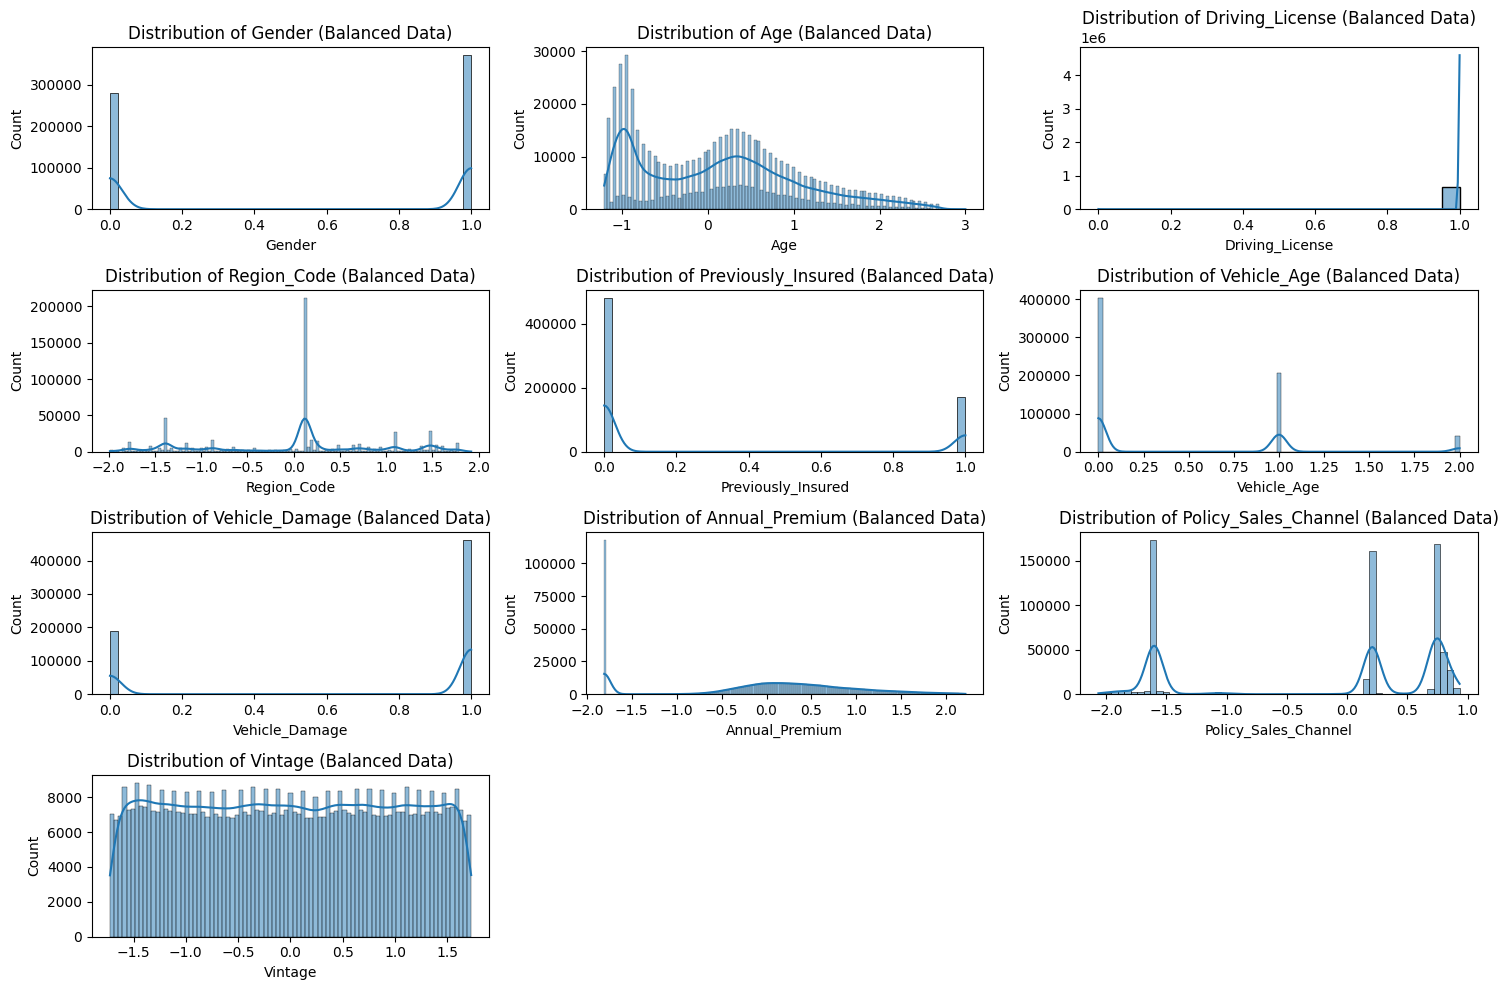

In [ ]:
import matplotlib.pyplot as plt
import numpy as np  # Import numpy for calculating subplot grid

# ... (Your existing code)

# Univariate analysis for balanced data (Numerical Features)
# Calculate the number of rows and columns for the subplot grid
num_cols = len(numerical_cols)  # Get the total number of numerical columns
num_rows = int(np.ceil(num_cols / 3))  # Calculate rows to fit all columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, 3, i + 1)  # Adjust grid size dynamically
    sns.histplot(X_balanced[col], kde=True)
    plt.title(f'Distribution of {col} (Balanced Data)')
plt.tight_layout()
plt.show()

# ... (Rest of your code)

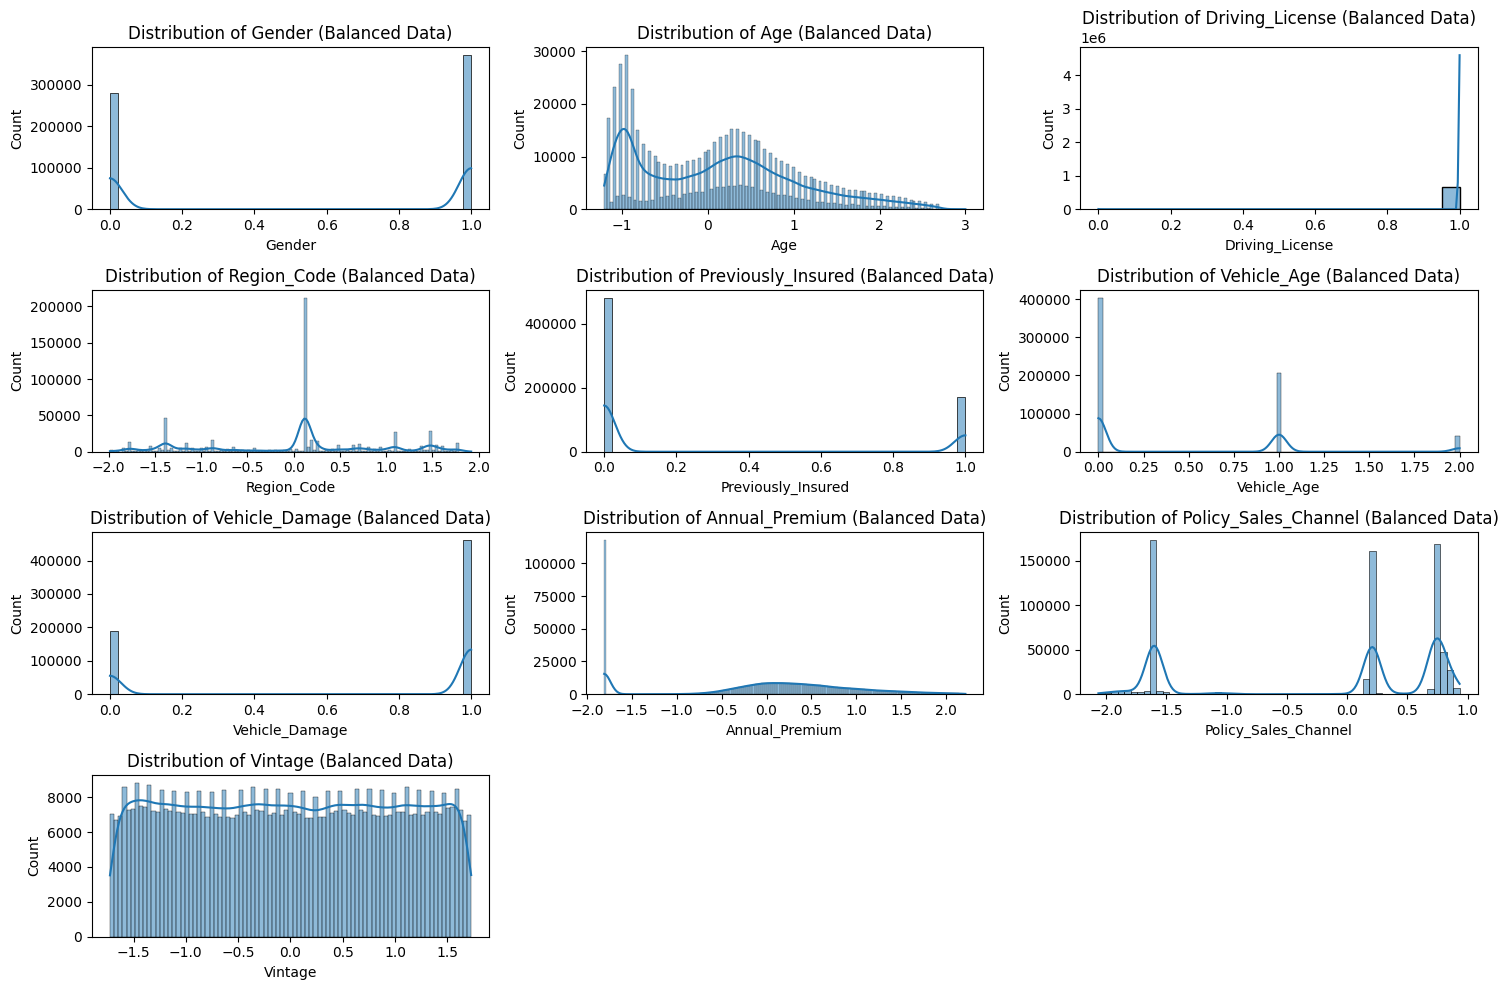

<Figure size 1500x1000 with 0 Axes>

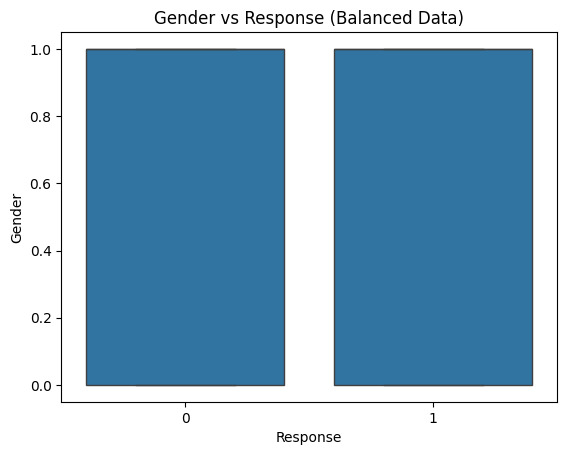

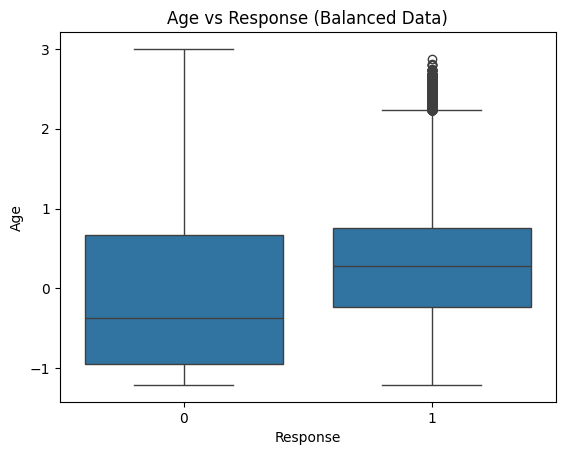

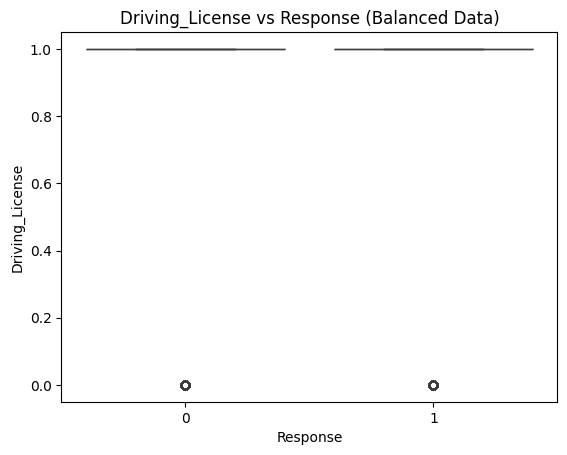

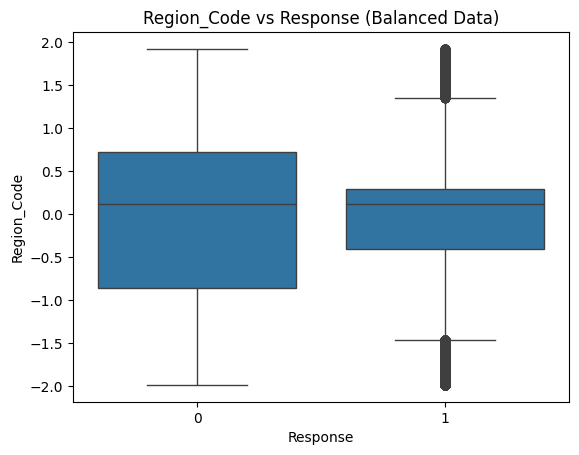

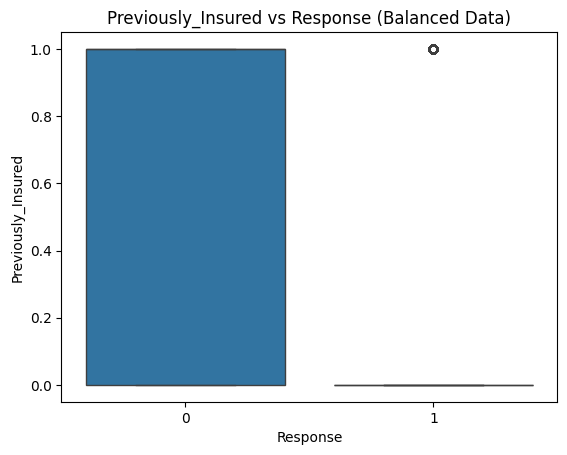

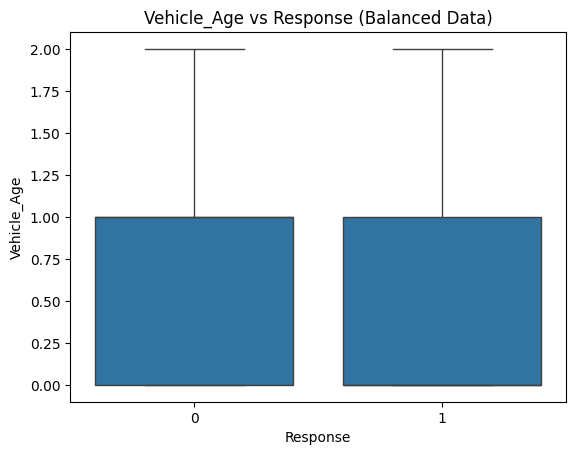

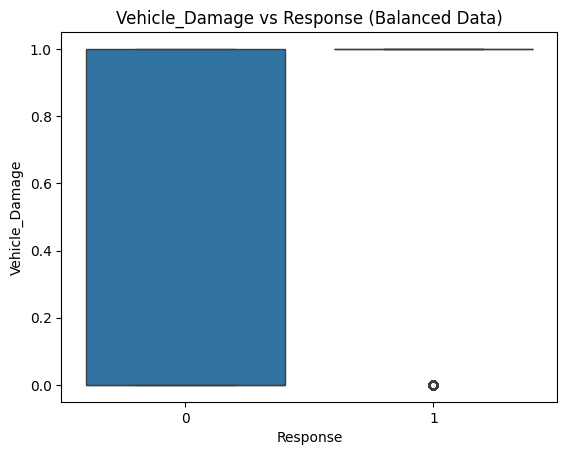

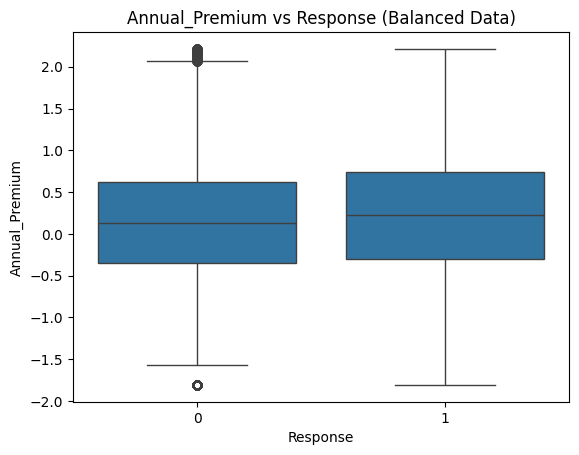

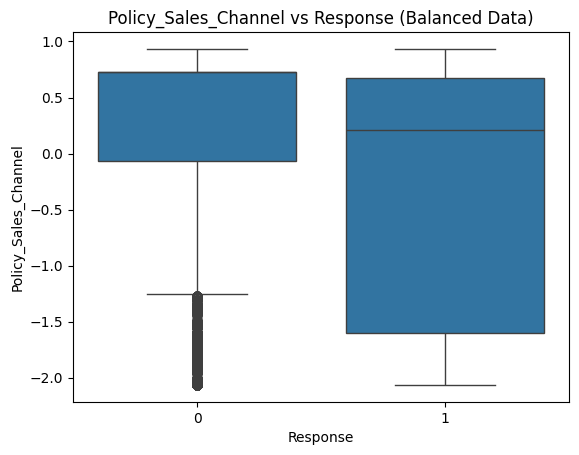

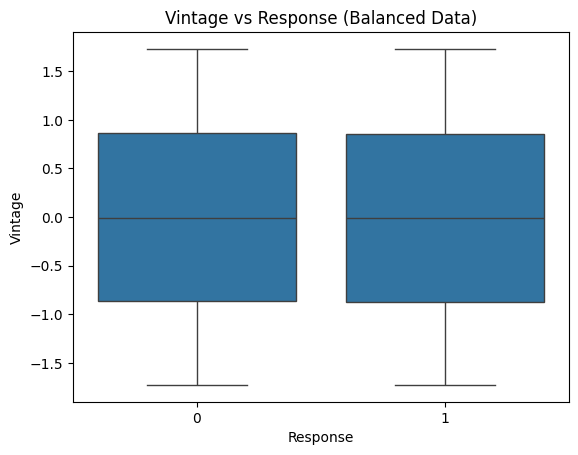

Percentage Distribution of Response (Balanced Data):
 Response
1    50.0
0    50.0
Name: proportion, dtype: float64


In [ ]:
# prompt: Univariate and bivariate analysis after balancing the data
numerical_cols = X_balanced.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_balanced.select_dtypes(exclude=np.number).columns.tolist()

import matplotlib.pyplot as plt
# Univariate analysis for balanced data
# Calculate the number of rows and columns for the subplot grid
num_cols = len(numerical_cols)  # Get the total number of numerical columns
num_rows = int(np.ceil(num_cols / 3))  # Calculate rows to fit all columns


plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(num_rows, 3, i + 1)  # Adjust grid size dynamically
    sns.histplot(X_balanced[col], kde=True)  # Use X_balanced for balanced data
    plt.title(f'Distribution of {col} (Balanced Data)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)  # Adjust subplot grid if necessary
    sns.countplot(x=col, data=X_balanced)  # Use X_balanced for balanced data
    plt.title(f'Countplot of {col} (Balanced Data)')
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Bivariate analysis for balanced data
for col in X_balanced.select_dtypes(include=['float64', 'int64']).columns:
    sns.boxplot(x=y_balanced, y=X_balanced[col], data=X_balanced) # Use X_balanced and y_balanced
    plt.title(f'{col} vs Response (Balanced Data)')
    plt.show()

# You can also calculate and print the percentage distribution of the 'Response' variable after balancing
y_balanced_counts = y_balanced.value_counts(normalize=True) * 100
print("Percentage Distribution of Response (Balanced Data):\n", y_balanced_counts)

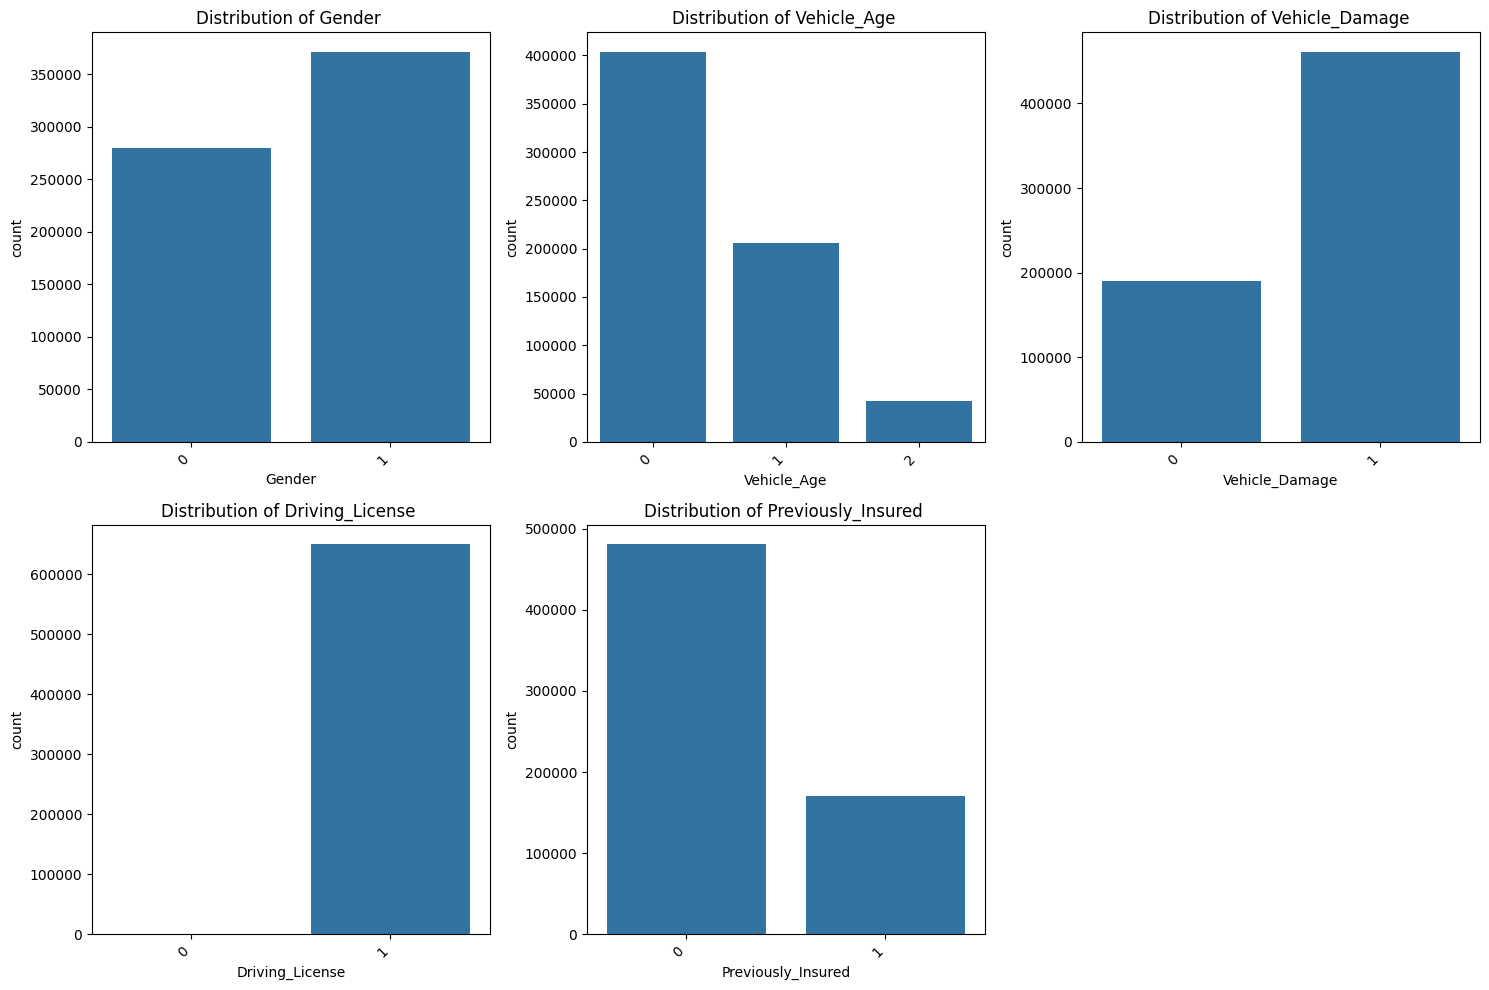

In [ ]:
# prompt: PERFORM UNIVARIATE ANALYSIS FOR  THE BALANCED DATA ,GENDER ,VEHIICLE AGE,VEHICLE DAMAGE,RESPONSE,PREVIOUSLY INSURED DRIVING LICENSE ARE CATEGORICAL

import matplotlib.pyplot as plt
# Univariate analysis for specified categorical columns in the balanced dataset
categorical_cols_to_analyze = ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Driving_License', 'Previously_Insured']

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols_to_analyze):
    if col in X_balanced.columns:  # Check if the column exists
        plt.subplot(2, 3, i + 1)
        sns.countplot(x=col, data=X_balanced)
        plt.title(f'Distribution of {col} ')
        plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


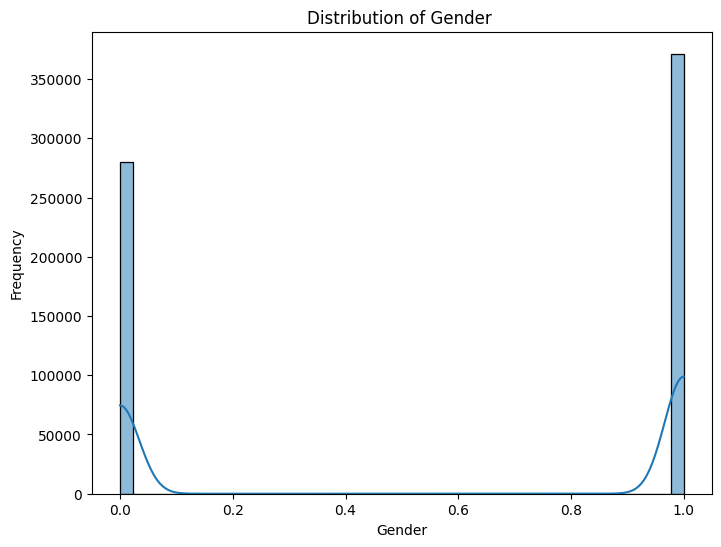

Descriptive statistics for Gender:
count    651268.000000
mean          0.570264
std           0.495039
min           0.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: Gender, dtype: float64
--------------------


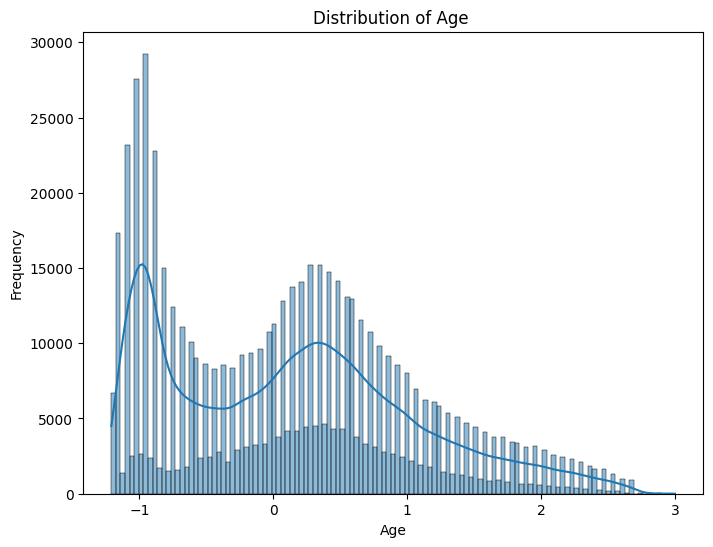

Descriptive statistics for Age:
count    651268.000000
mean          0.126357
std           0.919893
min          -1.209208
25%          -0.755844
50%           0.114777
75%           0.733779
max           3.000597
Name: Age, dtype: float64
--------------------


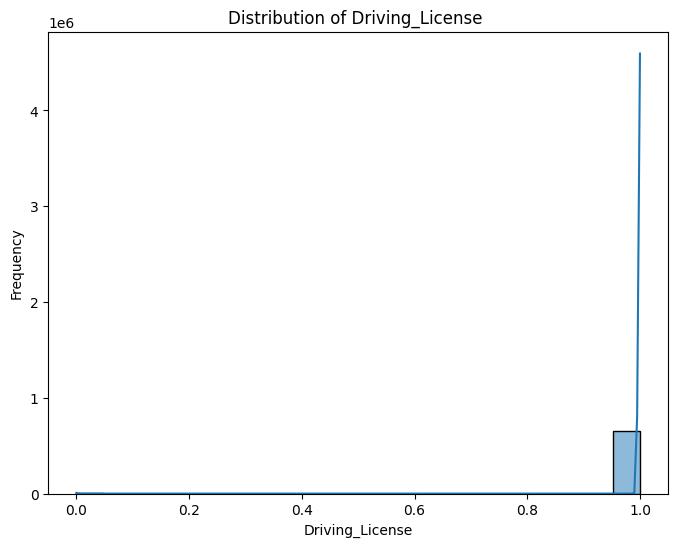

Descriptive statistics for Driving_License:
count    651268.000000
mean          0.998468
std           0.039116
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: Driving_License, dtype: float64
--------------------


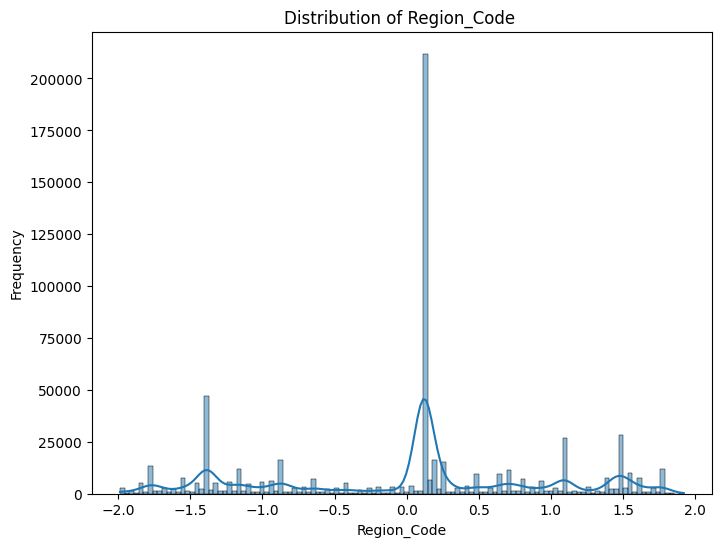

Descriptive statistics for Region_Code:
count    651268.000000
mean          0.009451
std           0.953221
min          -1.986216
25%          -0.818707
50%           0.117406
75%           0.586961
max           1.920511
Name: Region_Code, dtype: float64
--------------------


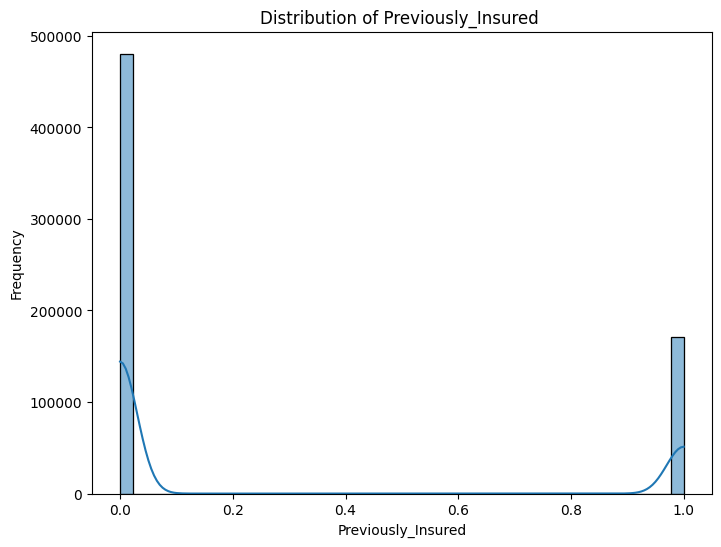

Descriptive statistics for Previously_Insured:
count    651268.000000
mean          0.262060
std           0.439755
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           1.000000
Name: Previously_Insured, dtype: float64
--------------------


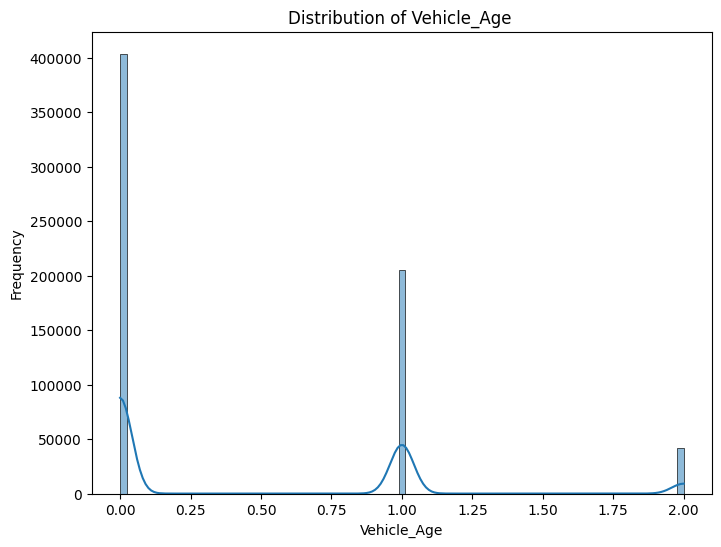

Descriptive statistics for Vehicle_Age:
count    651268.000000
mean          0.444375
std           0.612865
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           2.000000
Name: Vehicle_Age, dtype: float64
--------------------


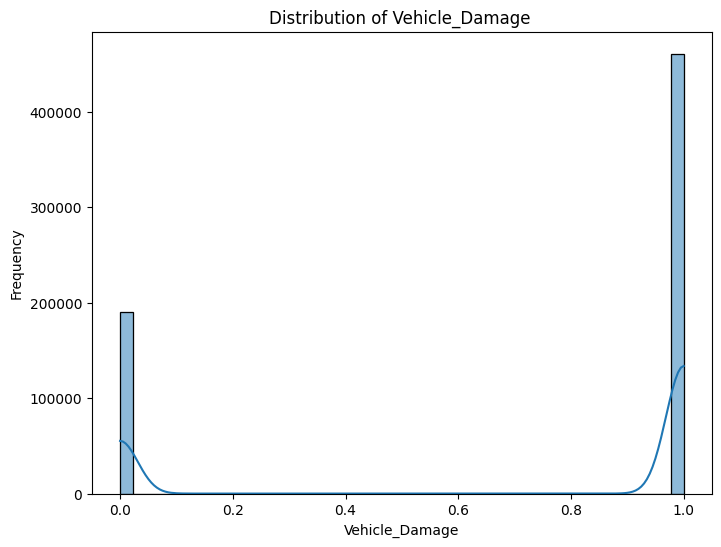

Descriptive statistics for Vehicle_Damage:
count    651268.000000
mean          0.707752
std           0.454796
min           0.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: Vehicle_Damage, dtype: float64
--------------------


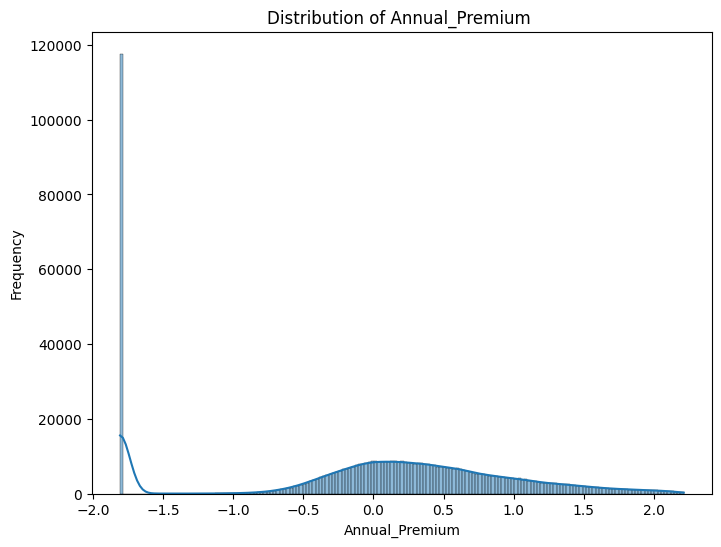

Descriptive statistics for Annual_Premium:
count    651268.000000
mean          0.021732
std           1.021049
min          -1.806591
25%          -0.330777
50%           0.174100
75%           0.678711
max           2.213069
Name: Annual_Premium, dtype: float64
--------------------


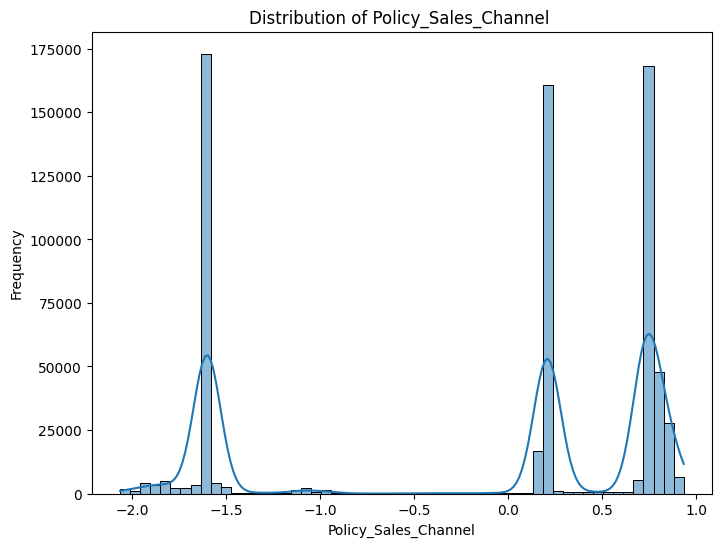

Descriptive statistics for Policy_Sales_Channel:
count    651268.000000
mean         -0.158519
std           1.030406
min          -2.064098
25%          -1.601474
50%           0.212013
75%           0.730152
max           0.933707
Name: Policy_Sales_Channel, dtype: float64
--------------------


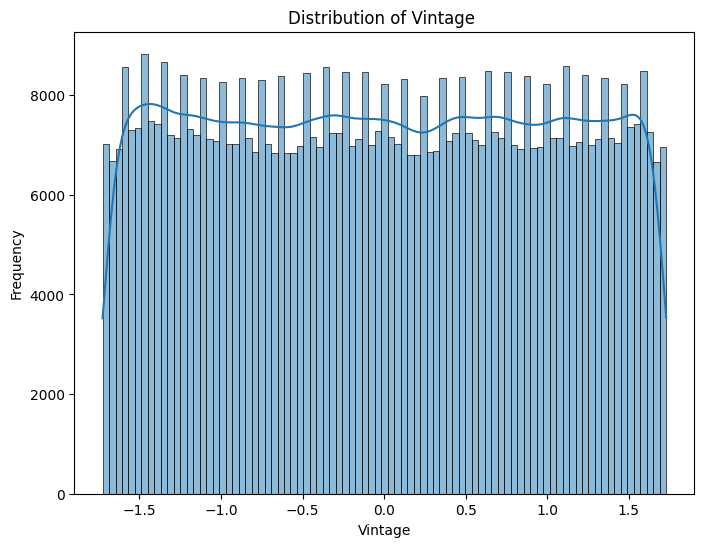

Descriptive statistics for Vintage:
count    651268.000000
mean         -0.001419
std           0.997430
min          -1.725168
25%          -0.867819
50%          -0.004129
75%           0.864236
max           1.728863
Name: Vintage, dtype: float64
--------------------


In [ ]:
# prompt: Univariate analysis for numerical columns

import matplotlib.pyplot as plt
# Assuming X_balanced and numerical_cols are already defined as in your provided code

# Univariate analysis for numerical columns in the balanced dataset
for col in numerical_cols:
    plt.figure(figsize=(8, 6))  # Adjust figure size as needed
    sns.histplot(X_balanced[col], kde=True)
    plt.title(f'Distribution of {col} ')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    # Descriptive statistics
    print(f"Descriptive statistics for {col}:")
    print(X_balanced[col].describe())
    print("-" * 20)


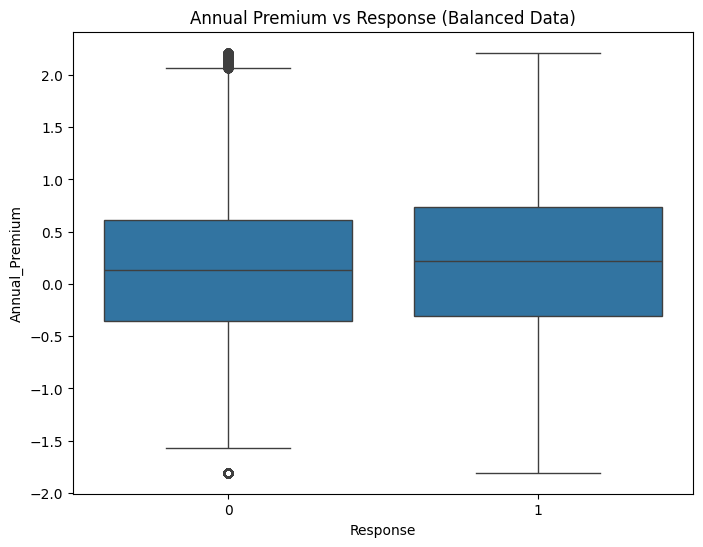

Correlation between Annual Premium and Response (Balanced Data): 0.028054767656600574


In [ ]:
# prompt: Perform bivariate analysis for annual premium ,response for balanced data

import matplotlib.pyplot as plt
# Bivariate analysis for 'Annual_Premium' vs 'Response' in the balanced dataset
plt.figure(figsize=(8, 6))
sns.boxplot(x=y_balanced, y=X_balanced['Annual_Premium'])
plt.title('Annual Premium vs Response (Balanced Data)')
plt.show()

# Calculate the correlation between 'Annual_Premium' and 'Response'
correlation = X_balanced['Annual_Premium'].corr(y_balanced)
print(f"Correlation between Annual Premium and Response (Balanced Data): {correlation}")


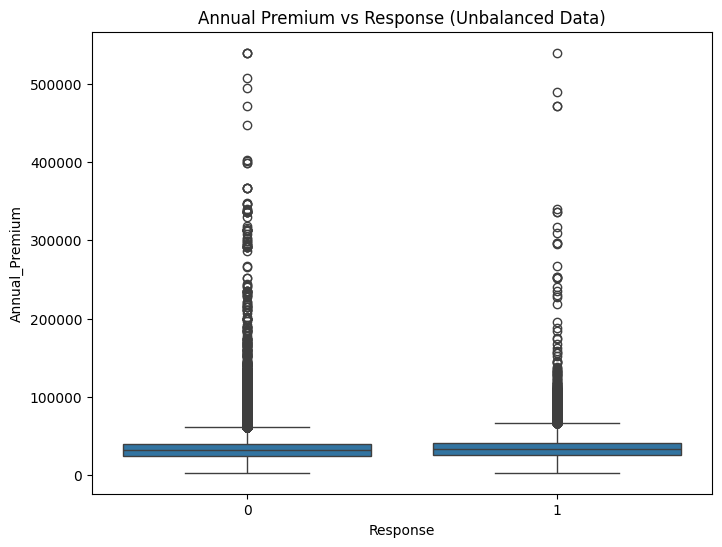

Correlation between Annual Premium and Response (Unbalanced Data): 0.022574695542560037


In [ ]:
# prompt: Perform bivariate analysis for annual premium ,response before balancing the data

import matplotlib.pyplot as plt
# Bivariate analysis for 'Annual_Premium' vs 'Response' before balancing
plt.figure(figsize=(8, 6))
sns.boxplot(x='Response', y='Annual_Premium', data=train)
plt.title('Annual Premium vs Response (Unbalanced Data)')
plt.show()

# Calculate the correlation between 'Annual_Premium' and 'Response' before balancing
correlation = train['Annual_Premium'].corr(train['Response'])
print(f"Correlation between Annual Premium and Response (Unbalanced Data): {correlation}")


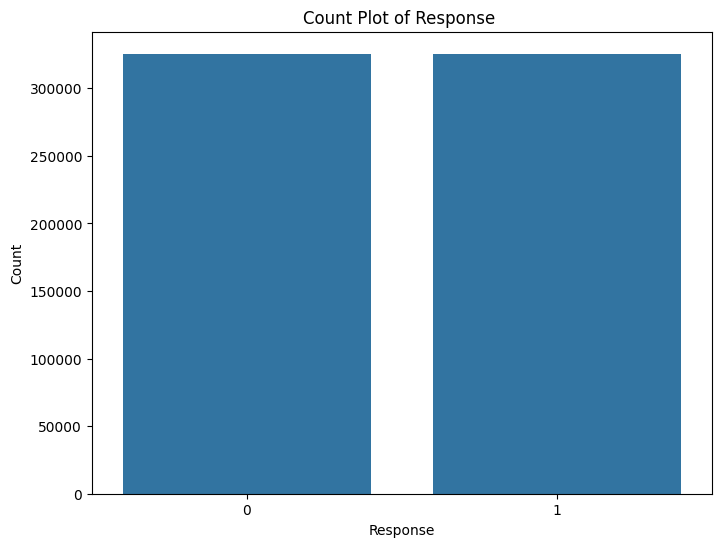

In [ ]:
# prompt: Count plot for response

import matplotlib.pyplot as plt
# Assuming X_balanced and y_balanced are already defined as in your provided code

plt.figure(figsize=(8, 6))
sns.countplot(x=y_balanced)  # Directly plot the 'Response' variable
plt.title('Count Plot of Response ')
plt.xlabel('Response')
plt.ylabel('Count')
plt.show()


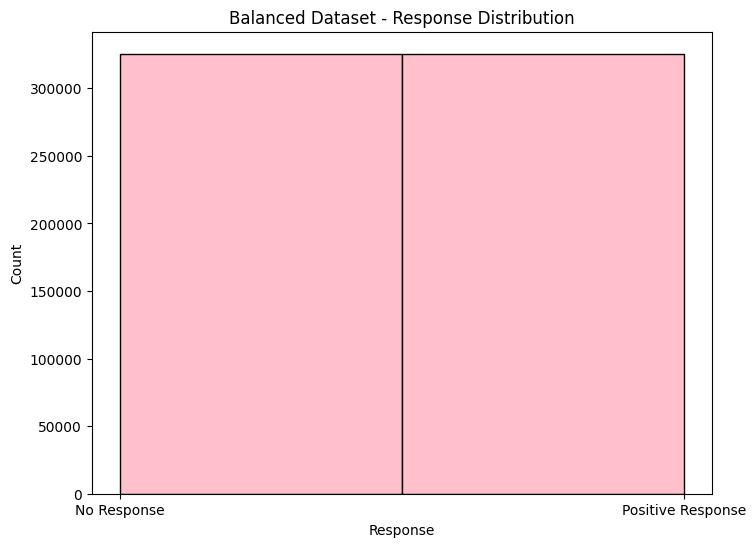

In [ ]:

import matplotlib.pyplot as plt
# Visualize the balanced dataset
plt.figure(figsize=(8, 6))
plt.title('Balanced Dataset - Response Distribution')
plt.hist(y_balanced, bins=2, edgecolor='black',color="pink")
plt.xlabel('Response')
plt.ylabel('Count')
plt.xticks([0, 1], ['No Response', 'Positive Response'])
plt.show()

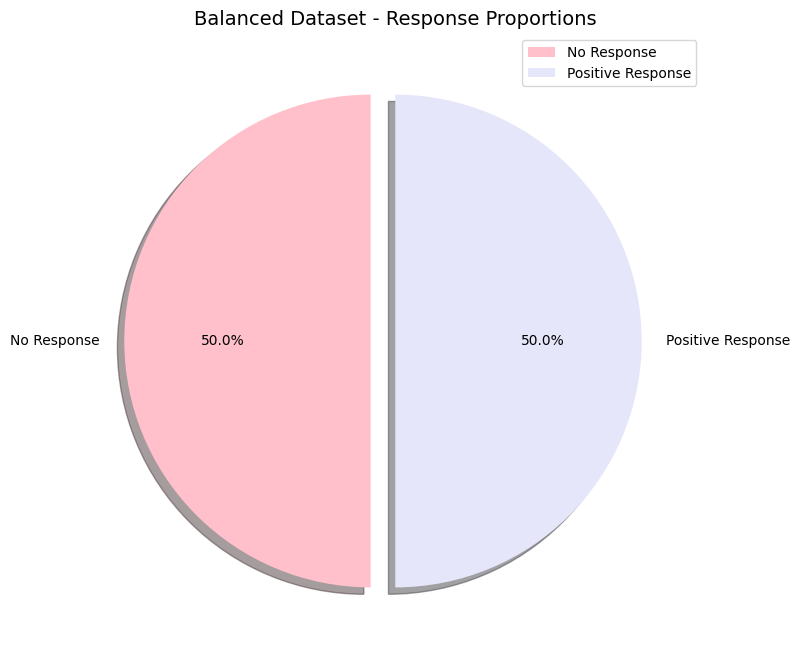

In [ ]:
# prompt: Visualize the balanced dataset using piechart

import matplotlib.pyplot as plt

# Assuming y_balanced is the balanced target variable
if 'y_balanced' in locals():
    response_counts = y_balanced.value_counts()
    plt.figure(figsize=(8, 8))
    plt.pie(response_counts, labels=['No Response', 'Positive Response'], autopct='%1.1f%%',
            colors=['pink', 'lavender'], startangle=90, shadow=True, explode=(0.1, 0))
    plt.title('Balanced Dataset - Response Proportions', fontsize=14)
    plt.legend(loc="best")
    plt.show()
else:
    print("y_balanced variable not found. Please ensure the code to create the balanced dataset has been executed.")

In [ ]:
# prompt: Remove the highly correlated variables

# Assuming train_no_outliers DataFrame is available

# Calculate the correlation matrix
correlation_matrix = train_no_outliers.corr()

# Set a threshold for correlation
threshold = 0.8

# Find highly correlated features
highly_correlated_features = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            highly_correlated_features.add(colname)

# Remove highly correlated features from the DataFrame
train_no_outliers = train_no_outliers.drop(columns=highly_correlated_features)

# Print the remaining columns
print("Remaining columns after removing highly correlated features:")
print(train_no_outliers.columns.tolist())


Remaining columns after removing highly correlated features:
['Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']


In [ ]:
# prompt: Remove from the data above outlier removed data

# The code to remove outliers using IQR has already been provided.
# The code to remove outliers using Z-score has also been provided.
# The `train_no_outliers` DataFrame already contains the data with outliers removed based on Z-score.

# If you want to use the IQR method instead:
# numerical_cols_with_outliers = ['Annual_Premium'] # Or other columns you want to treat
# train_no_outliers = remove_outliers_iqr(train, numerical_cols_with_outliers)

# Now proceed with the rest of your analysis using the outlier-removed data in train_no_outliers
# For example, balancing, scaling, and model training.
# The code provided already does this with the Z-score outlier removal.

# Example usage with the IQR outlier removed data (if you choose this method)
# ... your code to balance, scale and model training


# LOGISTIC REGRESSION

In [ ]:
# prompt: Build a logistic regression model for the above balanced data

# Initialize and train the Logistic Regression model
logreg_model = LogisticRegression(random_state=42)
logreg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_logreg = logreg_model.predict(X_test)
y_pred_logreg1 = logreg_model.predict(X_train)


# Evaluate the model
print("Logistic Regression Classification Report:\n", classification_report(y_test, y_pred_logreg))
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logreg))
print("Logistic Regression Test Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("Logistic Regression Train Accuracy:", accuracy_score(y_train, y_pred_logreg1))

# ROC AUC score
logreg_roc_auc = roc_auc_score(y_test, logreg_model.predict_proba(X_test)[:, 1])
print("Logistic Regression ROC AUC Score:", logreg_roc_auc)

Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.59      0.73     65188
           1       0.71      0.98      0.82     65066

    accuracy                           0.79    130254
   macro avg       0.83      0.79      0.78    130254
weighted avg       0.83      0.79      0.78    130254

Logistic Regression Confusion Matrix:
 [[38727 26461]
 [ 1511 63555]]
Logistic Regression Test Accuracy: 0.7852503569947948
Logistic Regression Train Accuracy: 0.7852859999923226
Logistic Regression ROC AUC Score: 0.8219601890878422


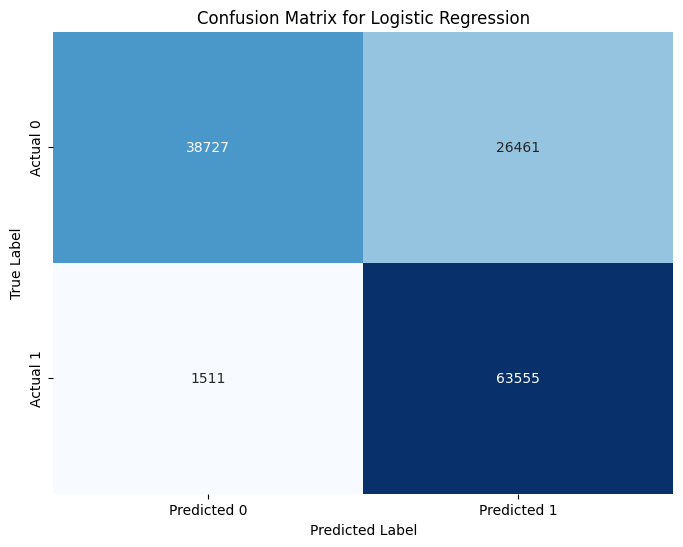

In [ ]:
# prompt: Visualize the confusion matrix for the above logistic regression model

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_logreg are defined from the previous code
cm = confusion_matrix(y_test, y_pred_logreg)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

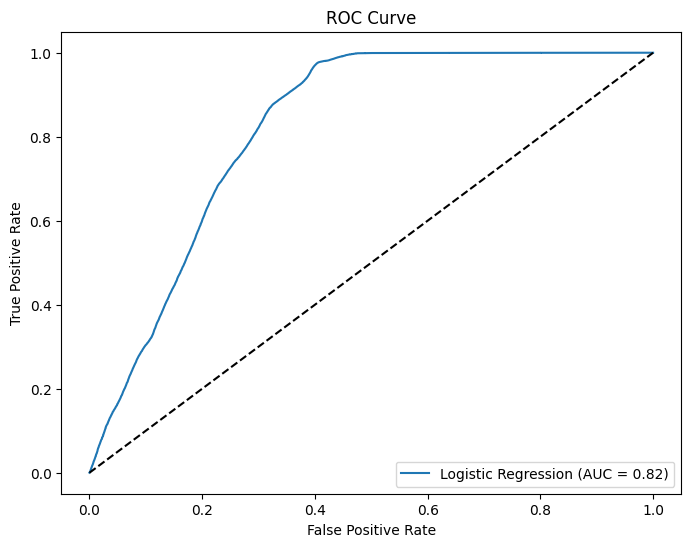

In [ ]:

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, logreg_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {logreg_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

# RANDOM FOREST

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.90      0.92     65188
           1       0.90      0.94      0.92     65066

    accuracy                           0.92    130254
   macro avg       0.92      0.92      0.92    130254
weighted avg       0.92      0.92      0.92    130254

Random Forest Confusion Matrix:
 [[58688  6500]
 [ 3966 61100]]
Random Forest Test Accuracy: 0.9196493005972946
Random Forest ROC AUC Score: 0.9809588727274738


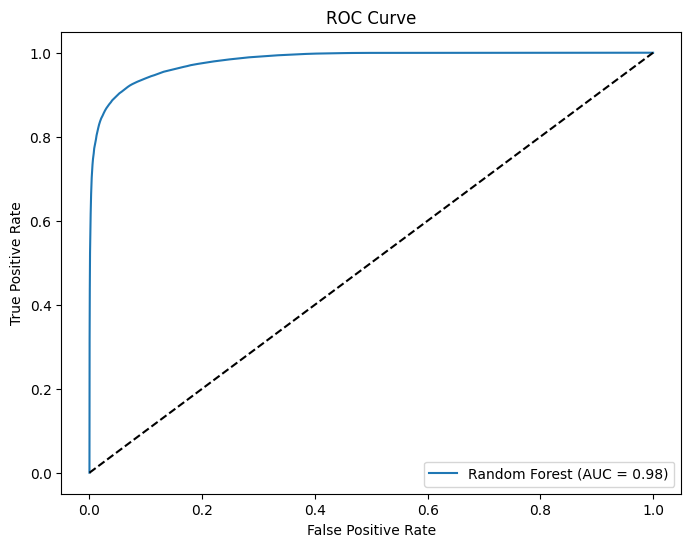

In [ ]:
# prompt: Build a random forest model for the above outlier removed train data

# Assuming X_train, y_train, X_test, y_test from the previous code are available

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)


# Evaluate the model
print("Random Forest Classification Report:\n", classification_report(y_test, y_pred_rf))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_rf))

# ROC AUC score
rf_roc_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])
print("Random Forest ROC AUC Score:", rf_roc_auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, rf_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {rf_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

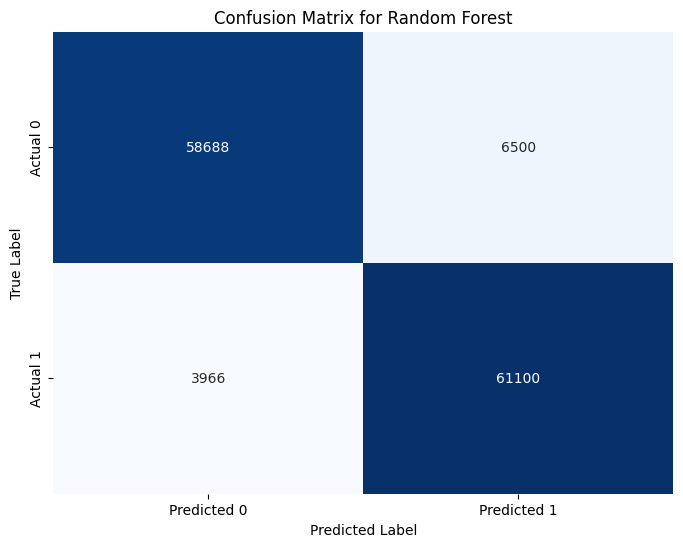

In [ ]:
# prompt: Visualize the confusion matrix for the above Random forest

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_rf are defined from the previous code
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
# prompt: My random forest model is overfitting ....adjust the overfitting

# ... (Your existing code)

# RANDOM FOREST WITH HYPERPARAMETER TUNING

# Define the parameter grid for RandomizedSearchCV
param_grid = {
    'n_estimators': [58],  # Number of trees in the forest
    'max_depth': [50],     # Maximum depth of the trees
    'min_samples_split': [8], # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1],  # Minimum number of samples required to be at a leaf node
    'max_features': ['sqrt'],   # Number of features to consider at every split
}

# Initialize the RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)

# Initialize RandomizedSearchCV
rf_random = RandomizedSearchCV(estimator=rf_model, param_distributions=param_grid, n_iter=50, cv=5, verbose=2, random_state=42, n_jobs=-1)

# Fit the model with hyperparameter tuning
rf_random.fit(X_train, y_train)

# Print the best hyperparameters found
print("Best Hyperparameters:", rf_random.best_params_)

# Evaluate the best model
best_rf_model = rf_random.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)
y_pred_rf1 = best_rf_model.predict(X_train)


print("Random Forest (Tuned) Classification Report:\n", classification_report(y_test, y_pred_rf))
print("Random Forest (Tuned) Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Random Forest (Tuned) Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest (Tuned) Train Accuracy:", accuracy_score(y_train, y_pred_rf1))

rf_roc_auc = roc_auc_score(y_test, best_rf_model.predict_proba(X_test)[:, 1])
print("Random Forest (Tuned) ROC AUC Score:", rf_roc_auc)


# ... (Rest of your code)


Fitting 5 folds for each of 1 candidates, totalling 5 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=50. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best Hyperparameters: {'n_estimators': 58, 'min_samples_split': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 50}
Random Forest (Tuned) Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.88      0.91     65127
           1       0.89      0.94      0.91     65127

    accuracy                           0.91    130254
   macro avg       0.91      0.91      0.91    130254
weighted avg       0.91      0.91      0.91    130254

Random Forest (Tuned) Confusion Matrix:
 [[57325  7802]
 [ 3938 61189]]
Random Forest (Tuned) Test Accuracy: 0.9098684109509113
Random Forest (Tuned) Train Accuracy: 0.9779622044705133
Random Forest (Tuned) ROC AUC Score: 0.977169400693323


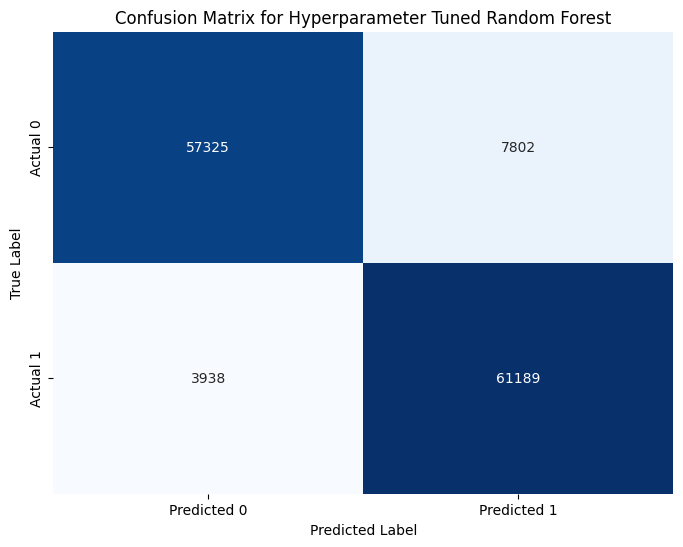

In [ ]:
# prompt: Visualize the confusion matrix  above hyperparameter tuned random forest

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_rf are defined from the previous code
# where y_pred_rf are the predictions from the hyperparameter tuned model
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Hyperparameter Tuned Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


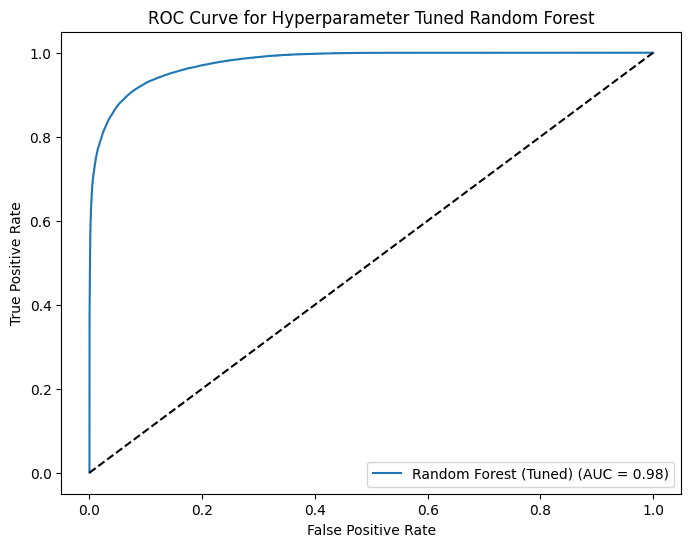

In [ ]:
# prompt: Roc curve for selected parameters

import matplotlib.pyplot as plt
# Calculate ROC curve for the hyperparameter-tuned Random Forest
fpr, tpr, thresholds = roc_curve(y_test, best_rf_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (Tuned) (AUC = {rf_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Hyperparameter Tuned Random Forest')
plt.legend(loc='lower right')
plt.show()


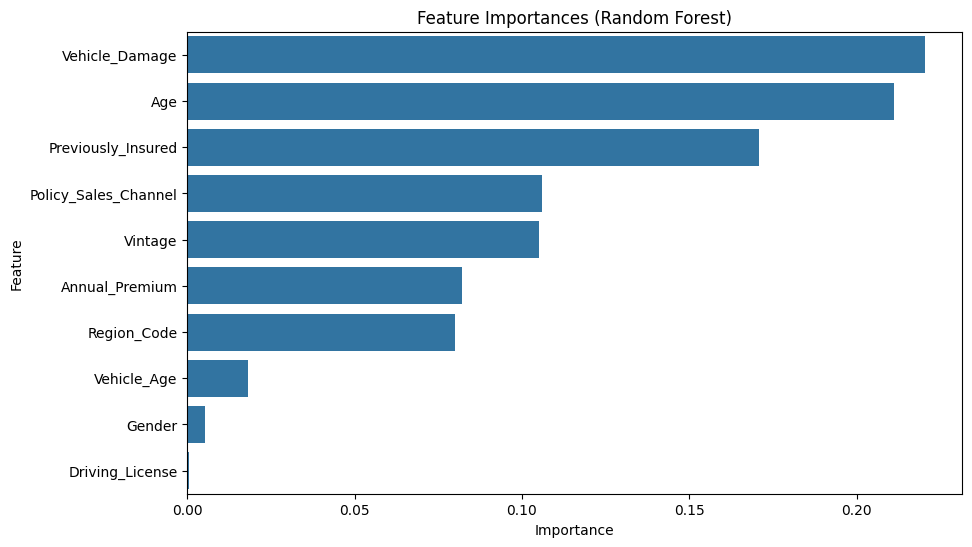

In [ ]:
# prompt: perform feature importance for the random forest

import pandas as pd
import matplotlib.pyplot as plt
# Get feature importances from the best random forest model
importances = best_rf_model.feature_importances_

# Create a DataFrame for visualization
feature_importances = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances)
plt.title('Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()


Random Forest (Selected Features) Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.87      0.90     65188
           1       0.88      0.94      0.91     65066

    accuracy                           0.90    130254
   macro avg       0.91      0.90      0.90    130254
weighted avg       0.91      0.90      0.90    130254

Random Forest (Selected Features) Confusion Matrix:
 [[56570  8618]
 [ 3979 61087]]
Random Forest (Selected Features) Accuracy: 0.9032889584964762
Random Forest (Selected Features) ROC AUC Score: 0.9749160792362364


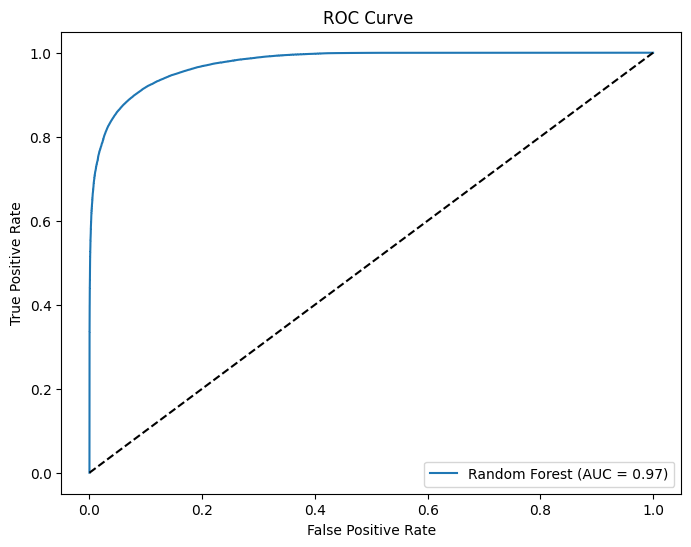

In [ ]:
# prompt: perform feature selection for the random forest modeland complete model training and evaluation

import matplotlib.pyplot as plt
# Assuming 'best_rf_model' and 'X_train' are available from previous code

# Get feature importances
feature_importances = best_rf_model.feature_importances_

# Set a threshold for feature importance
threshold = 0.01  # Adjust this threshold as needed

# Select features above the threshold
selected_features = X_train.columns[feature_importances > threshold]

# Create new training and testing sets with selected features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
# Store the best hyperparameters in a variable
best_params_rf = rf_random.best_params_ # Assign best parameters here



# Train a new Random Forest model with selected features
rf_model_selected = RandomForestClassifier(random_state=42, **best_params_rf) # Use best hyperparameters
rf_model_selected.fit(X_train_selected, y_train)

# Make predictions on the test set with selected features
y_pred_selected = rf_model_selected.predict(X_test_selected)


# Evaluate the model with selected features
print("Random Forest (Selected Features) Classification Report:\n", classification_report(y_test, y_pred_selected))
print("Random Forest (Selected Features) Confusion Matrix:\n", confusion_matrix(y_test, y_pred_selected))
print("Random Forest (Selected Features) Accuracy:", accuracy_score(y_test, y_pred_selected))

# ROC AUC score for the model with selected features
selected_roc_auc = roc_auc_score(y_test, rf_model_selected.predict_proba(X_test_selected)[:, 1])
print("Random Forest (Selected Features) ROC AUC Score:", selected_roc_auc)

# Calculate ROC curve for the model with selected features
fpr, tpr, thresholds = roc_curve(y_test, rf_model_selected.predict_proba(X_test_selected)[:, 1])

# Plot ROC curve for the model with selected features
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {selected_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve ')
plt.legend(loc='lower right')
plt.show()


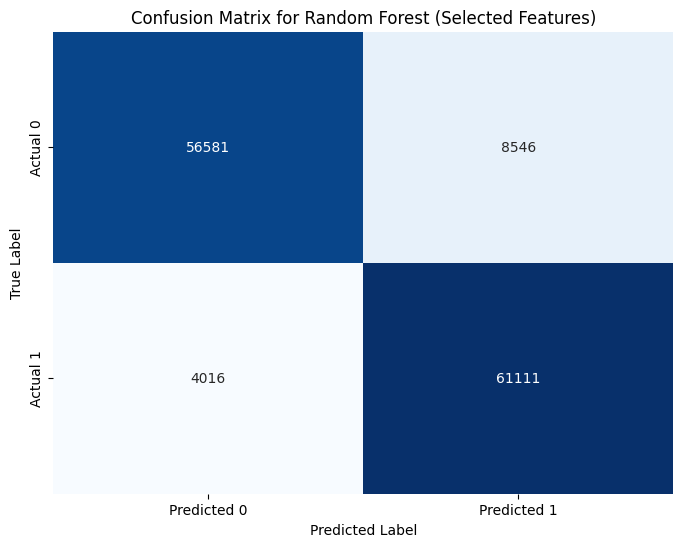

In [ ]:
# prompt: Visualize the confusion matrix

import matplotlib.pyplot as plt
# Assuming y_test and y_pred_selected are defined from the previous code
cm = confusion_matrix(y_test, y_pred_selected)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Random Forest (Selected Features)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


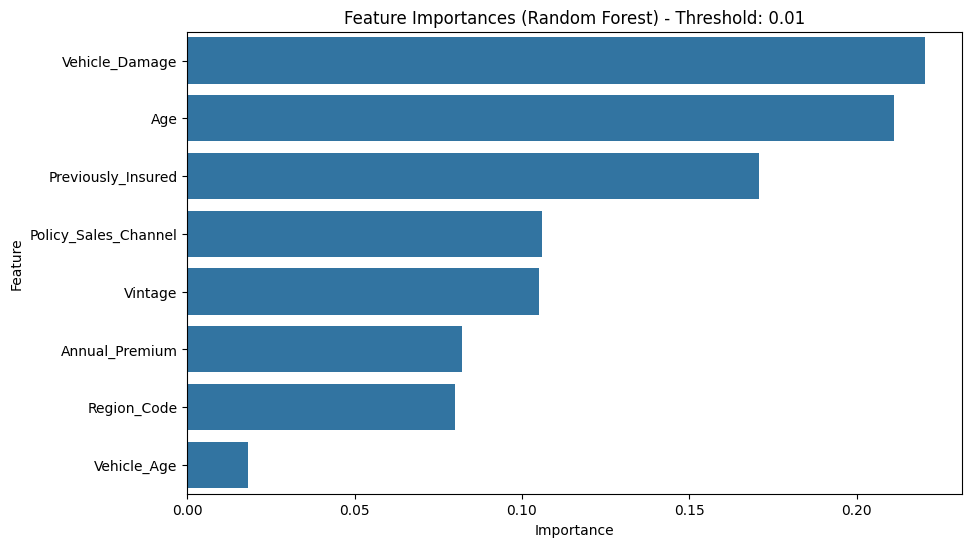

In [ ]:
# prompt: Visualize the selected features that are selected based on threshold

import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'feature_importances' DataFrame is available from previous code
# Recreating the DataFrame using the original logic from cell #33

# Get feature importances from the best random forest model
importances = best_rf_model.feature_importances_ # Assumed to be available from cell #35
feature_importances = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}) # Recreate the DataFrame
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)


# Set a threshold for feature importance
threshold = 0.01

# Select features above the threshold
selected_features = feature_importances[feature_importances['Importance'] > threshold] # Now this indexing works

# Plot feature importances for selected features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=selected_features)
plt.title(f'Feature Importances (Random Forest) - Threshold: {threshold}')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

# GRADIENT BOOSTING

Gradient Boosting Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.69      0.80     65188
           1       0.76      0.96      0.84     65066

    accuracy                           0.82    130254
   macro avg       0.85      0.82      0.82    130254
weighted avg       0.85      0.82      0.82    130254

Gradient Boosting Confusion Matrix:
 [[45212 19976]
 [ 2851 62215]]
Gradient Boosting Accuracy: 0.8247501036436501
Gradient Boosting ROC AUC Score: 0.9153732216944119


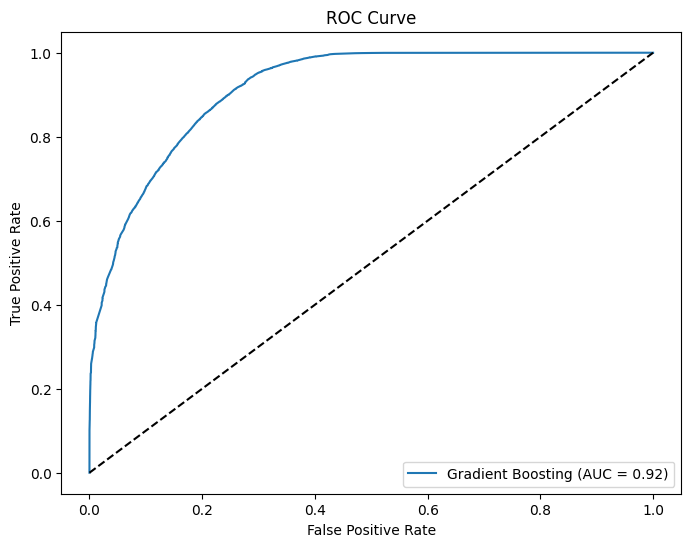

In [ ]:
# prompt: Build a gradient boosting for the above outlier removed train data

# Initialize and train the Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_gb = gb_model.predict(X_test)

# Evaluate the model
print("Gradient Boosting Classification Report:\n", classification_report(y_test, y_pred_gb))
print("Gradient Boosting Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))
print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))

# ROC AUC score
gb_roc_auc = roc_auc_score(y_test, gb_model.predict_proba(X_test)[:, 1])
print("Gradient Boosting ROC AUC Score:", gb_roc_auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, gb_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Gradient Boosting (AUC = {gb_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

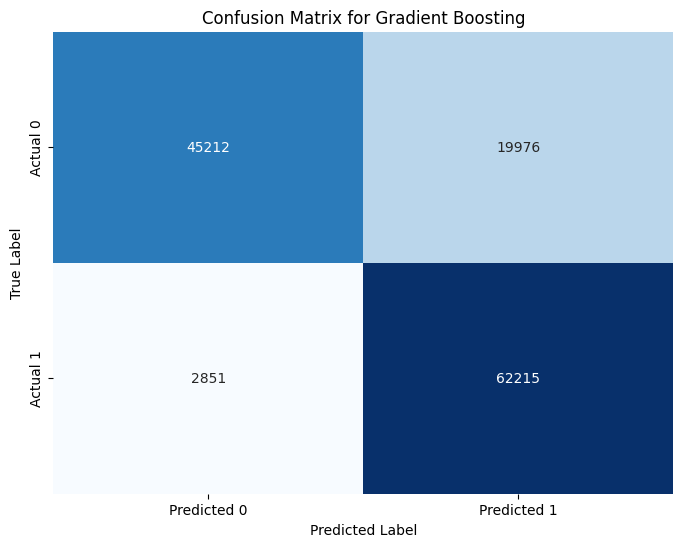

In [ ]:
# prompt: Visualize the confusion matrix for the above ada boost model

# Assuming y_test and y_pred_gb are defined from the previous code
cm = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Gradient Boosting')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# LGBM

/usr/local/lib/python3.11/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


[LightGBM] [Info] Number of positive: 260568, number of negative: 260446
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.041189 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1282
[LightGBM] [Info] Number of data points in the train set: 521014, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500117 -> initscore=0.000468
[LightGBM] [Info] Start training from score 0.000468
LightGBM Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.86      0.88     65188
           1       0.87      0.89      0.88     65066

    accuracy                           0.88    130254
   macro avg       0.88      0.88      0.88    130254
weighted avg       0.88      0.88      0.88    130254

LightGBM Confusion Matrix:
 [[56263  8925]
 [ 6961 58105]]
LightGBM Accuracy: 0.87

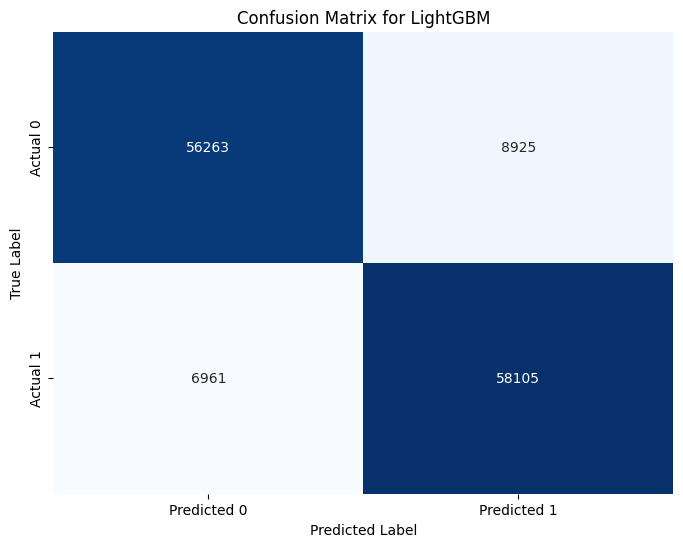

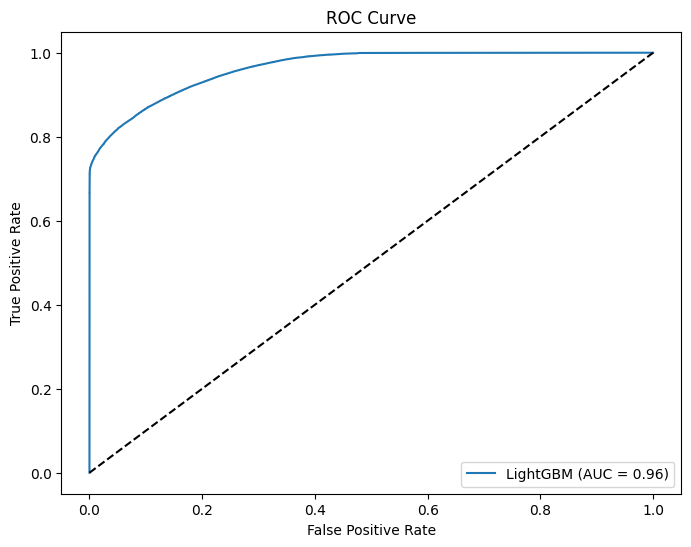

In [ ]:
# prompt: Build a lgbm model for the above balanced data without hyperparameter tuning

import lightgbm as lgb

# Assuming X_train, y_train, X_test, y_test are already defined from the previous code

# Create and train the LightGBM model without hyperparameter tuning
lgbm_model = lgb.LGBMClassifier(random_state=42)
lgbm_model.fit(X_train, y_train)

# Make predictions
y_pred_lgbm = lgbm_model.predict(X_test)


# Evaluate the model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
print("LightGBM Classification Report:\n", classification_report(y_test, y_pred_lgbm))
print("LightGBM Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lgbm))
print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgbm))

# ROC AUC score
lgbm_roc_auc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
print("LightGBM ROC AUC Score:", lgbm_roc_auc)

# Plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for LightGBM')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, lgbm_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'LightGBM (AUC = {lgbm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


In [ ]:
y_pred_lgbm = lgbm_model.predict(X_train)
print("LightGBM Accuracy:", accuracy_score(y_train, y_pred_lgbm))

LightGBM Accuracy: 0.878580997823475


# ADA BOOST

AdaBoost Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.64      0.75     65188
           1       0.72      0.94      0.81     65066

    accuracy                           0.79    130254
   macro avg       0.81      0.79      0.78    130254
weighted avg       0.81      0.79      0.78    130254

AdaBoost Confusion Matrix:
 [[41546 23642]
 [ 4172 60894]]
AdaBoost Accuracy: 0.7864633715663243
AdaBoost ROC AUC Score: 0.8370404054222788


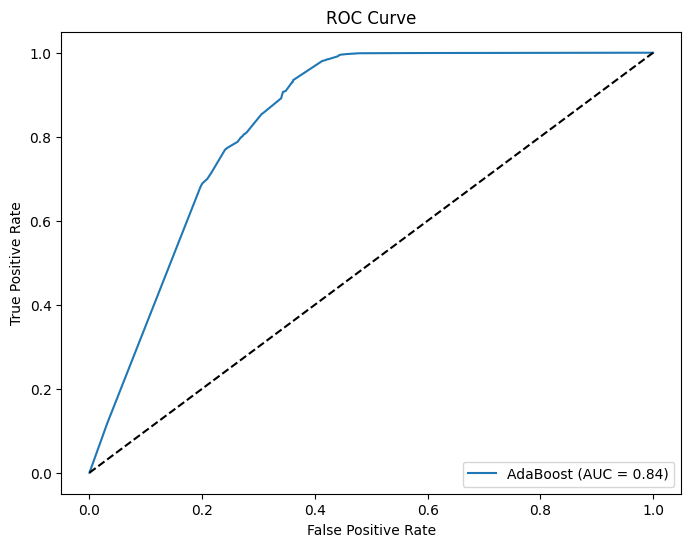

In [ ]:
# prompt: Build a Ada boost model for the above outlier removed train data

from sklearn.ensemble import AdaBoostClassifier

# Initialize and train the AdaBoost Classifier
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_ada = ada_model.predict(X_test)

# Evaluate the model
print("AdaBoost Classification Report:\n", classification_report(y_test, y_pred_ada))
print("AdaBoost Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ada))
print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))

# ROC AUC score
ada_roc_auc = roc_auc_score(y_test, ada_model.predict_proba(X_test)[:, 1])
print("AdaBoost ROC AUC Score:", ada_roc_auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, ada_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AdaBoost (AUC = {ada_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

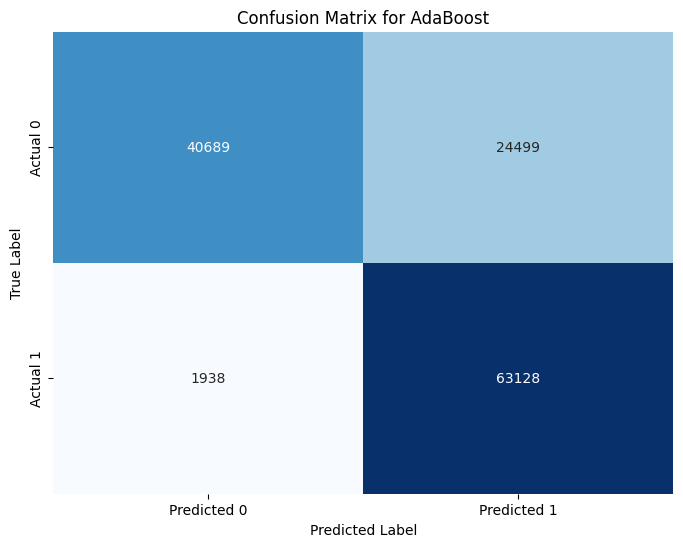

In [ ]:
# prompt: Visualize the confusion matrix for the ada boost model

# Assuming y_test and y_pred_ada are defined from the previous code
from sklearn.ensemble import AdaBoostClassifier
cm = confusion_matrix(y_test, y_pred_ada)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for AdaBoost')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Naive Bayes

Naive Bayes Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.59      0.73     65188
           1       0.71      0.98      0.82     65066

    accuracy                           0.79    130254
   macro avg       0.83      0.79      0.78    130254
weighted avg       0.83      0.79      0.78    130254

Naive Bayes Confusion Matrix:
 [[38727 26461]
 [ 1511 63555]]
Naive Bayes Accuracy: 0.7852503569947948
Naive Bayes ROC AUC Score: 0.8284535656047393


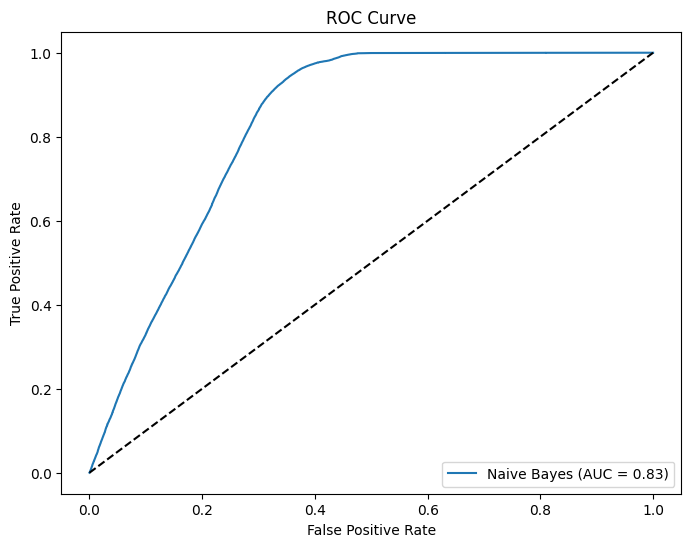

In [ ]:
# prompt: Build a Naive Bayes for the above outlier removed train data

from sklearn.naive_bayes import GaussianNB

# Initialize and train the Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_nb = nb_model.predict(X_test)

# Evaluate the model
print("Naive Bayes Classification Report:\n", classification_report(y_test, y_pred_nb))
print("Naive Bayes Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

# ROC AUC score
nb_roc_auc = roc_auc_score(y_test, nb_model.predict_proba(X_test)[:, 1])
print("Naive Bayes ROC AUC Score:", nb_roc_auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, nb_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Naive Bayes (AUC = {nb_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

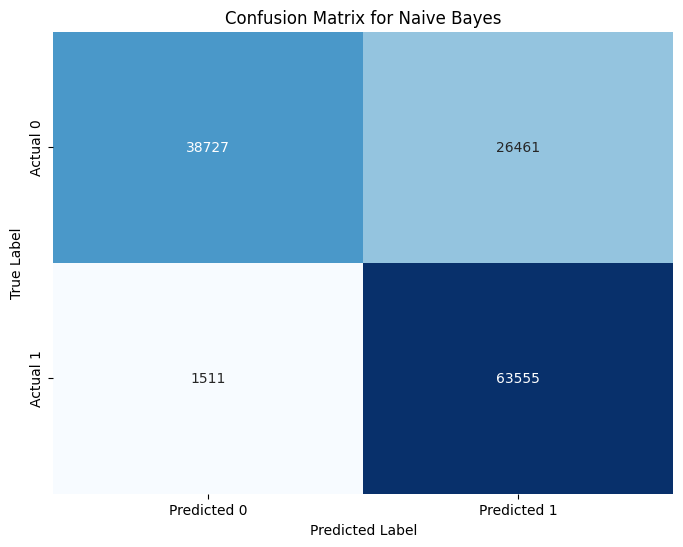

In [ ]:
# prompt: Visualize the confusion matrix for the naive bayes model

# Assuming y_test and y_pred_nb are defined from the previous code
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# KNN

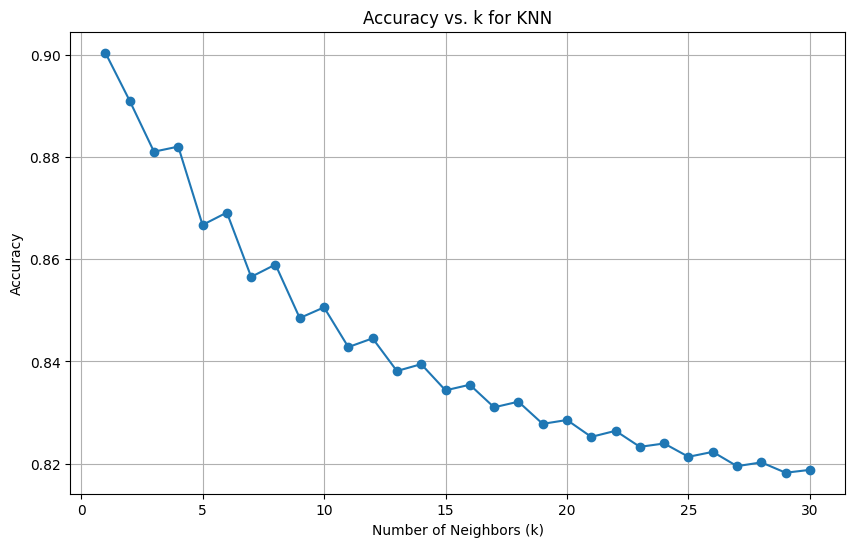

In [ ]:
# prompt: Perform k nearest neighbor and visualize how to choose k value

import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Assuming X_train, X_test, y_train, y_test are defined from your previous code
# Example: X = train_no_outliers.drop(columns='Response'), y = train_no_outliers['Response']
# Then, X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Define a range of k values to test
k_values = range(1, 31)  # Test k from 1 to 30
accuracies = []

for k in k_values:
    # Initialize the KNN classifier with the current k value
    knn = KNeighborsClassifier(n_neighbors=k)

    # Train the classifier
    knn.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = knn.predict(X_test)

    # Calculate the accuracy of the model
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)


# Plot the accuracy vs k value
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. k for KNN')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7, metric='minkowski', p=2)
knn.fit(X_train, y_train)

print('Accuracy of K-NN classifier on training set: {:.2f}'.format(knn.score(X_train, y_train)))

test_pred_knn = knn.predict(X_test)

Accuracy of K-NN classifier on training set: 0.88


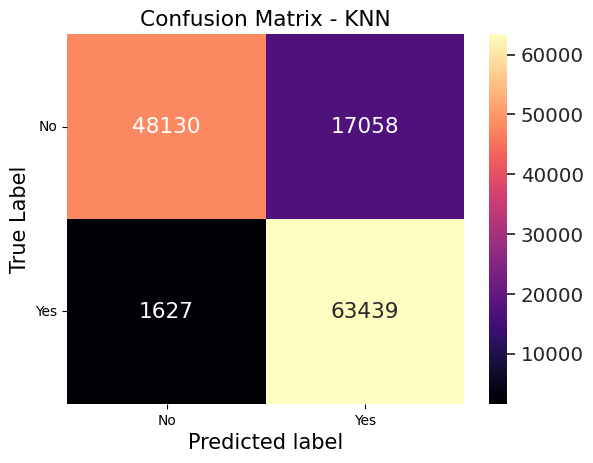

<Figure size 1500x1000 with 0 Axes>

In [ ]:
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test, test_pred_knn)
matrix_df = pd.DataFrame(confusion_matrix)

ax = plt.axes()
sns.set(font_scale=1.3)
plt.figure(figsize=(15,10))
sns.heatmap(matrix_df, annot=True, fmt="g", ax=ax, cmap="magma")

# Set axis titles
ax.set_title('Confusion Matrix - KNN')
ax.set_xlabel("Predicted label", fontsize=15)
ax.set_xticklabels(['No', 'Yes'])
ax.set_ylabel("True Label", fontsize=15)
ax.set_yticklabels(['No', 'Yes'], rotation=0)
plt.show()

# DECISION TREE

Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.89      0.90     65188
           1       0.89      0.91      0.90     65066

    accuracy                           0.90    130254
   macro avg       0.90      0.90      0.90    130254
weighted avg       0.90      0.90      0.90    130254

Decision Tree Confusion Matrix:
 [[57832  7356]
 [ 6176 58890]]
Decision Tree Accuracy: 0.896110676063691
Decision Tree ROC AUC Score: 0.8961329698107775


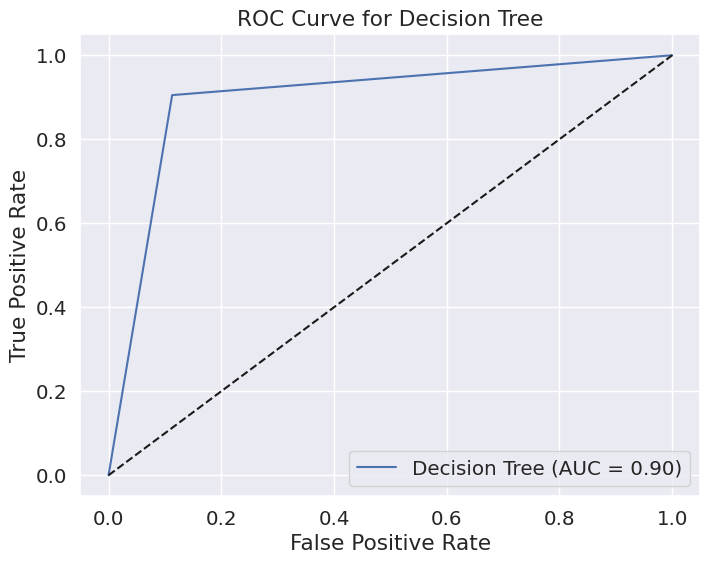

In [ ]:
# prompt: Build a decision tree for the above balanced training dataset

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Initialize and train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Classification Report:\n", classification_report(y_test, y_pred_dt))
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

# ROC AUC score
dt_roc_auc = roc_auc_score(y_test, dt_model.predict_proba(X_test)[:, 1])
print("Decision Tree ROC AUC Score:", dt_roc_auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, dt_model.predict_proba(X_test)[:, 1])

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Decision Tree (AUC = {dt_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Decision Tree')
plt.legend(loc='lower right')
plt.show()

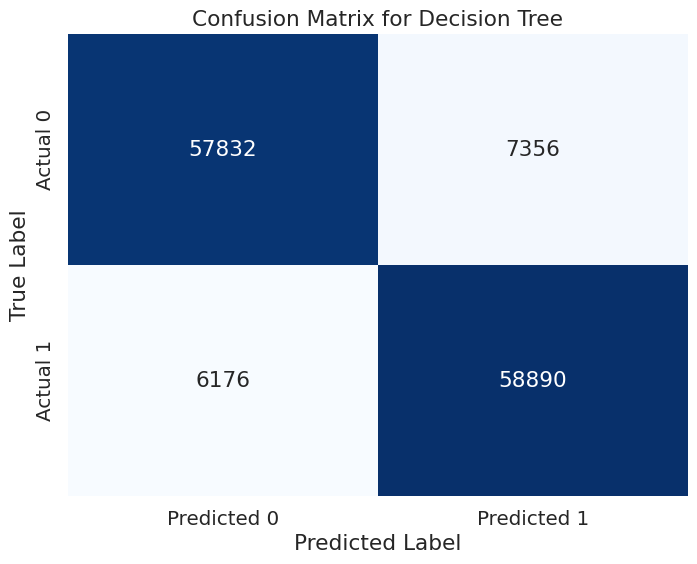

In [ ]:
# prompt: Confusion matrix for the above decion tree

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_dt are defined from the previous code
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Decision Tree')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: Cross validation for all the models to choose the model with best accuracy

import numpy as np
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": logreg_model,
    "Random Forest": rf_model,  # Use the tuned model
    "Gradient Boosting": gb_model,
    "AdaBoost": ada_model,
    "LGBM":lgbm_model,
    "Naive Bayes": nb_model,
    "KNN": knn,
    "Decision Tree": dt_model
}

results = {}
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')  # 5-fold cross-validation
    results[name] = {
        'mean_accuracy': np.mean(cv_scores),
        'std_accuracy': np.std(cv_scores),
        'cv_scores': cv_scores
    }
    print(f"{name}: Mean Accuracy = {np.mean(cv_scores):.4f}, Standard Deviation = {np.std(cv_scores):.4f}")

best_model_name = max(results, key=lambda k: results[k]['mean_accuracy'])
print(f"\nBest Model based on cross-validation: {best_model_name}")


Logistic Regression: Mean Accuracy = 0.7853, Standard Deviation = 0.0016
Random Forest: Mean Accuracy = 0.9135, Standard Deviation = 0.0007
Gradient Boosting: Mean Accuracy = 0.8255, Standard Deviation = 0.0015
AdaBoost: Mean Accuracy = 0.7973, Standard Deviation = 0.0015
[LightGBM] [Info] Number of positive: 208454, number of negative: 208357
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038666 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1283
[LightGBM] [Info] Number of data points in the train set: 416811, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500116 -> initscore=0.000465
[LightGBM] [Info] Start training from score 0.000465
[LightGBM] [Info] Number of positive: 208454, number of negative: 208357
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.068766 

In [ ]:
! pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 9.7 MB/s eta 0:00:00


In [ ]:
# prompt: Perform a catboost model for the above data without hyperparameter tuning


from catboost import CatBoostClassifier

# Assuming X_train, y_train, X_test, and y_test are defined from the previous code

# Initialize and train the CatBoost model without hyperparameter tuning
catboost_model = CatBoostClassifier(random_seed=42, verbose=0)  # Set verbose to 0 to suppress training output
catboost_model.fit(X_train, y_train)

# Make predictions
y_pred = catboost_model.predict(X_test)


# Evaluate the model
print("Catboost Classification Report:\n", classification_report(y_test, y_pred))
print("Catboost Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Catboost test Accuracy:", accuracy_score(y_test, y_pred))


# ROC AUC score
catboost_roc_auc = roc_auc_score(y_test, catboost_model.predict_proba(X_test)[:, 1])
print("Catboost ROC AUC Score:", catboost_roc_auc)


Catboost Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.94      0.91     65188
           1       0.94      0.87      0.90     65066

    accuracy                           0.91    130254
   macro avg       0.91      0.91      0.91    130254
weighted avg       0.91      0.91      0.91    130254

Catboost Confusion Matrix:
 [[61382  3806]
 [ 8448 56618]]
Catboost test Accuracy: 0.9059222749397331
Catboost ROC AUC Score: 0.9746478068117281


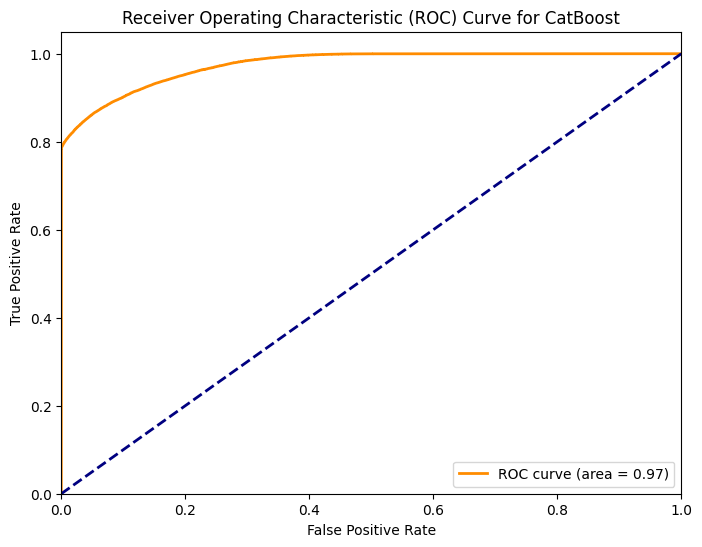

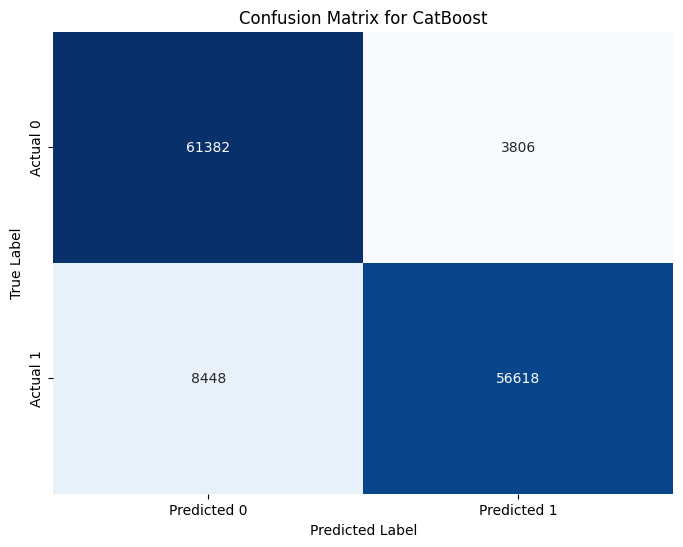

In [ ]:
# prompt: Roc curve and confusion matrix for the above catboost model

from catboost import CatBoostClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Assuming 'catboost_model', 'X_test', and 'y_test' are defined from the previous code

# Get predicted probabilities for the positive class
y_pred_prob = catboost_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CatBoost')
plt.legend(loc="lower right")
plt.show()


# Confusion Matrix
y_pred = catboost_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for CatBoost')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Hyperparameters: {'border_count': 245, 'depth': 9, 'iterations': 849, 'l2_leaf_reg': 6, 'learning_rate': 0.3036678574825027, 'random_strength': 4.967421529594551}
CatBoost Accuracy: 0.9094231271208562
CatBoost ROC AUC Score: 0.9760708348944316


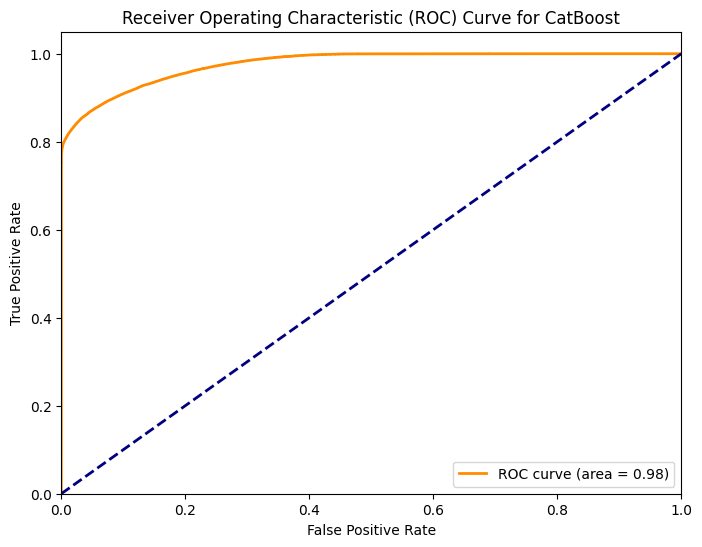

In [ ]:
# prompt: Hyperparameter tuning for catboost with gpu

!pip install catboost

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'iterations': randint(100, 1000),
    'learning_rate': uniform(0.01, 0.3),
    'depth': randint(4, 10),
    'l2_leaf_reg': randint(1, 10),
    'border_count': randint(32, 255),
    'random_strength': uniform(0.1, 10),
}

# Initialize CatBoostClassifier with task_type='GPU' for GPU usage
catboost_model = CatBoostClassifier(
    task_type="GPU", devices='0:1', random_seed=42, verbose=0
)

# Use RandomizedSearchCV for hyperparameter tuning
random_search = RandomizedSearchCV(
    catboost_model,
    param_distributions=param_grid,
    n_iter=50,  # Number of iterations for random search
    scoring='accuracy',
    cv=5,  # Number of cross-validation folds
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Fit the model on training data
random_search.fit(X_train, y_train)

# Get the best model and its hyperparameters
best_catboost_model = random_search.best_estimator_
best_params = random_search.best_params_

# Make predictions on the test set using the best model
y_pred = best_catboost_model.predict(X_test)
y_pred_prob = best_catboost_model.predict_proba(X_test)[:, 1]

# Evaluate the best model
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print(f"Best Hyperparameters: {best_params}")
print(f"CatBoost Accuracy: {accuracy}")
print(f"CatBoost ROC AUC Score: {roc_auc}")

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CatBoost')
plt.legend(loc="lower right")
plt.show()


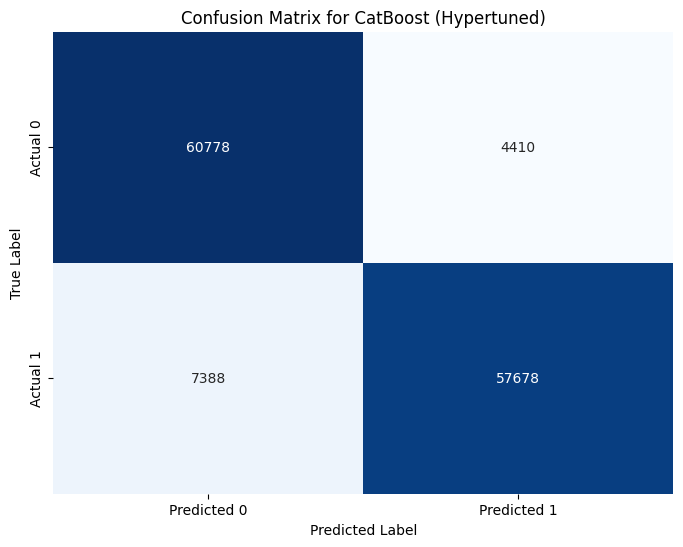

In [ ]:
# prompt: confusion matrix for the above hypertuned catboosy

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred are defined from the previous code (best_catboost_model predictions)
y_pred = best_catboost_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for CatBoost (Hypertuned)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: Classification report for this hypertumned catboost

from sklearn.metrics import classification_report

# Assuming y_test and y_pred are defined from the previous code (best_catboost_model predictions)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.89      0.93      0.91     65188
           1       0.93      0.89      0.91     65066

    accuracy                           0.91    130254
   macro avg       0.91      0.91      0.91    130254
weighted avg       0.91      0.91      0.91    130254



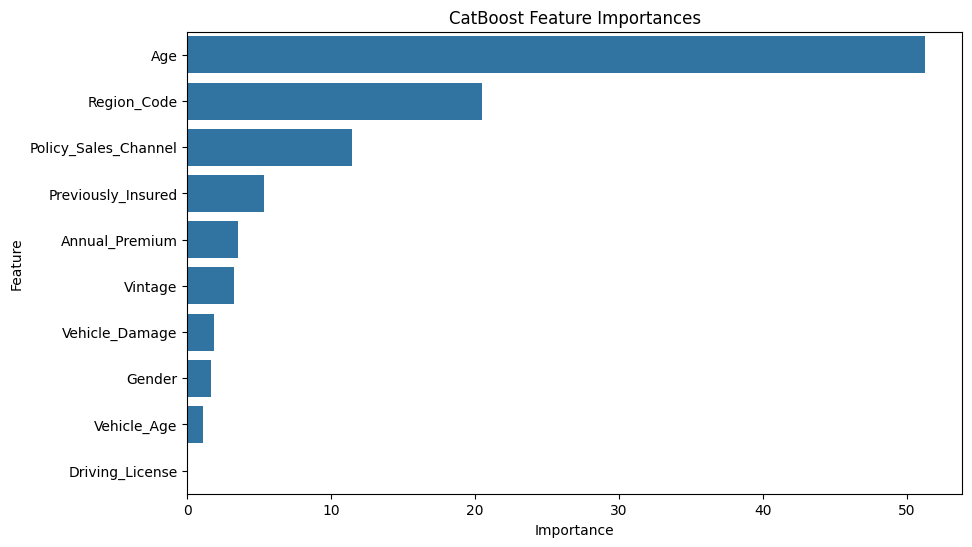

In [ ]:
# prompt: visualize the important features from the above catboost

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool

# Assuming best_catboost_model and X_train are defined from the previous code

# Get feature importances
feature_importances = best_catboost_model.get_feature_importance(Pool(X_train, label=y_train))

# Create a DataFrame for better visualization
feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': feature_importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('CatBoost Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()


In [ ]:
from sklearn.feature_selection import RFECV
from catboost import CatBoostClassifier

# Initialize CatBoost model without GPU
cat_model = CatBoostClassifier(iterations=200, verbose=0,task_type="GPU")

# Use RFECV to find the optimal number of features
rfecv = RFECV(estimator=cat_model, step=1, cv=5, scoring='accuracy', n_jobs=-1)
rfecv.fit(X_train, y_train)

# Number of optimal features
optimal_features = X_train.columns[rfecv.support_]
print(f"Optimal number of features: {len(optimal_features)}")
print("Selected features:", list(optimal_features))

Optimal number of features: 9
Selected features: ['Gender', 'Age', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']


In [ ]:
# prompt: Give the selected features in a table

import pandas as pd

# Assuming optimal_features is defined from the previous code
optimal_features_list = list(optimal_features)

# Create a DataFrame for the selected features
selected_features_df = pd.DataFrame({'Selected Features': optimal_features_list})

# Display the DataFrame as a table
selected_features_df


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 6.6 MB/s eta 0:00:00
Catboost Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.94      0.91     65188
           1       0.93      0.87      0.90     65066

    accuracy                           0.90    130254
   macro avg       0.91      0.90      0.90    130254
weighted avg       0.91      0.90      0.90    130254

Catboost Confusion Matrix:
 [[61191  3997]
 [ 8433 56633]]
Catboost test Accuracy: 0.9045710688347383
Catboost ROC AUC Score: 0.9739892697980532


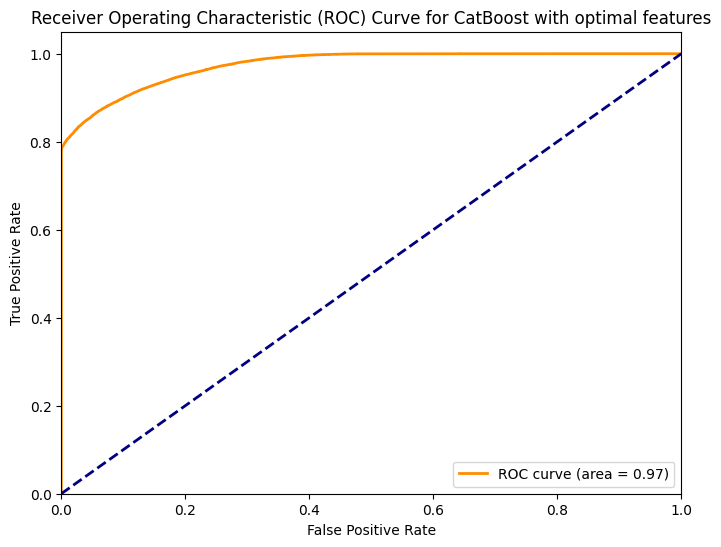

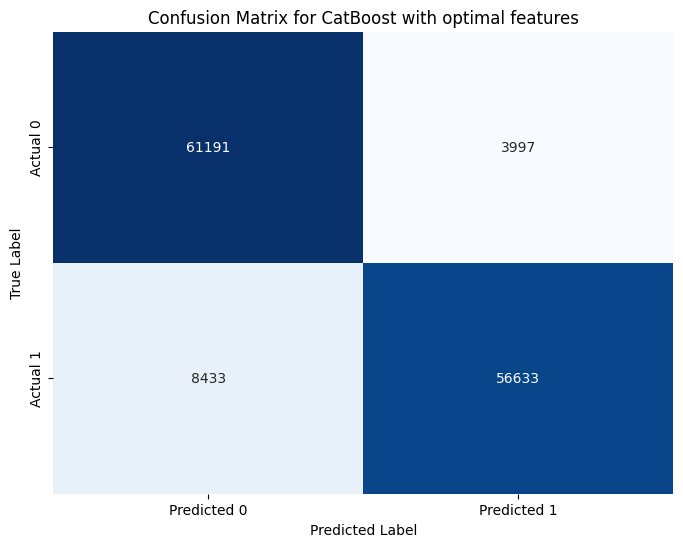

In [ ]:
# prompt: build the model with important features for catboost
!pip install catboost
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.feature_selection import RFECV


# Assuming X_train, y_train, X_test, and y_test are defined from the previous code

# Initialize and train the CatBoost model with optimal features
# Replace 'optimal_features' with the actual list of features selected by RFECV
optimal_features = ['Gender', 'Age', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage'] #Example, replace with your actual features
X_train_optimal = X_train[optimal_features]
X_test_optimal = X_test[optimal_features]


catboost_model_optimal = CatBoostClassifier(iterations=200, verbose=0, random_seed=42)
catboost_model_optimal.fit(X_train_optimal, y_train)


y_pred_optimal = catboost_model_optimal.predict(X_test_optimal)

# Evaluate the model with optimal features
print("Catboost Classification Report:\n", classification_report(y_test, y_pred_optimal))
print("Catboost Confusion Matrix:\n", confusion_matrix(y_test, y_pred_optimal))
print("Catboost test Accuracy:", accuracy_score(y_test, y_pred_optimal))

#ROC AUC Score
catboost_roc_auc_optimal = roc_auc_score(y_test, catboost_model_optimal.predict_proba(X_test_optimal)[:, 1])
print("Catboost ROC AUC Score:", catboost_roc_auc_optimal)

#ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, catboost_model_optimal.predict_proba(X_test_optimal)[:, 1])
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CatBoost with optimal features')
plt.legend(loc="lower right")
plt.show()

# Confusion Matrix
cm_optimal = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_optimal, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for CatBoost with optimal features')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: Perform hyperparameter tuning for this optimal features and find the accuracy and auc score

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.metrics import accuracy_score, roc_auc_score

# Assuming X_train_optimal, y_train, X_test_optimal, and y_test are defined
# from the previous code block (using optimal features)

# Define the parameter grid for hyperparameter tuning
param_grid = {'border_count': [245], 'depth':[9], 'iterations': [849], 'l2_leaf_reg': [6], 'learning_rate':[0.3036678574825027], 'random_strength':[4.967421529594551]}


# Initialize CatBoostClassifier
catboost_model_optimal = CatBoostClassifier(random_seed=42, verbose=0)

# Use RandomizedSearchCV for hyperparameter tuning
random_search = RandomizedSearchCV(
    catboost_model_optimal,
    param_distributions=param_grid,
    n_iter=50,  # Number of iterations for random search
    scoring='accuracy',
    cv=5,  # Number of cross-validation folds
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Fit the model on training data with optimal features
random_search.fit(X_train_optimal, y_train)

# Get the best model and its hyperparameters
best_catboost_model_optimal = random_search.best_estimator_
best_params_optimal = random_search.best_params_

# Make predictions on the test set using the best model
y_pred_optimal = best_catboost_model_optimal.predict(X_test_optimal)
y_pred_prob_optimal = best_catboost_model_optimal.predict_proba(X_test_optimal)[:, 1]

# Evaluate the best model
accuracy_optimal = accuracy_score(y_test, y_pred_optimal)
roc_auc_optimal = roc_auc_score(y_test, y_pred_prob_optimal)

print(f"Best Hyperparameters (Optimal Features): {best_params_optimal}")
print(f"CatBoost Accuracy (Optimal Features): {accuracy_optimal}")
print(f"CatBoost ROC AUC Score (Optimal Features): {roc_auc_optimal}")


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=50. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best Hyperparameters (Optimal Features): {'random_strength': 4.967421529594551, 'learning_rate': 0.3036678574825027, 'l2_leaf_reg': 6, 'iterations': 849, 'depth': 9, 'border_count': 245}
CatBoost Accuracy (Optimal Features): 0.9097378967248606
CatBoost ROC AUC Score (Optimal Features): 0.9758776834923656


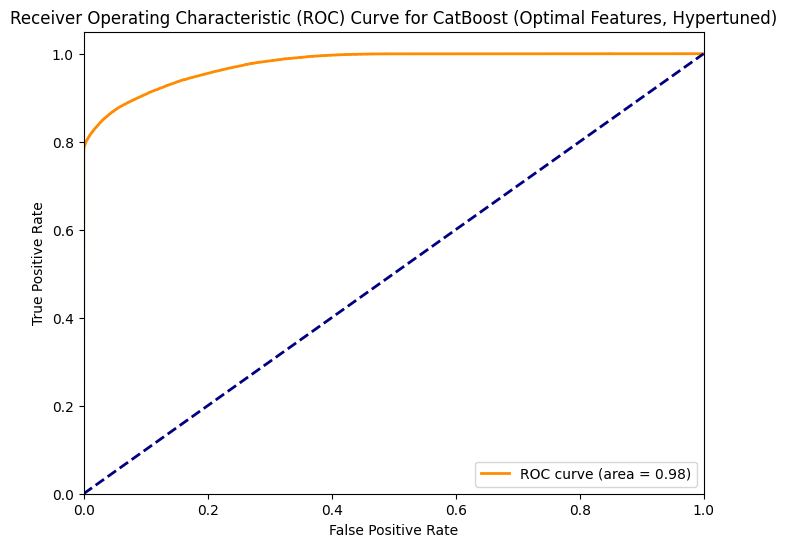

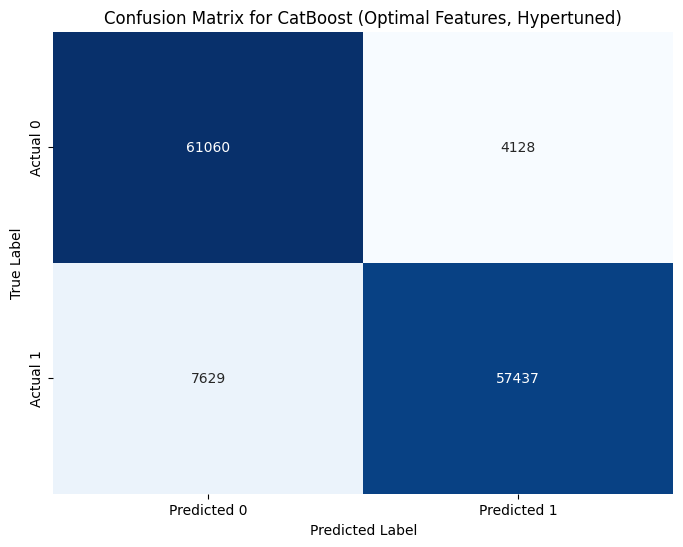

In [ ]:
# prompt: Visualize the confusion matrix and roc curve

from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming y_test and y_pred_prob_optimal are defined from the previous code

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob_optimal)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CatBoost (Optimal Features, Hypertuned)')
plt.legend(loc="lower right")
plt.show()

# Confusion Matrix
cm_optimal = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_optimal, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for CatBoost (Optimal Features, Hypertuned)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: Classification report for this above model

print(classification_report(y_test, y_pred_optimal))


              precision    recall  f1-score   support

           0       0.89      0.94      0.91     65188
           1       0.93      0.88      0.91     65066

    accuracy                           0.91    130254
   macro avg       0.91      0.91      0.91    130254
weighted avg       0.91      0.91      0.91    130254



In [ ]:
# prompt: Save the catboost model

import joblib

# Assuming best_catboost_model_optimal is your trained CatBoost model
joblib.dump(best_catboost_model_optimal, 'best_catboost_model_optimal.pkl')


['best_catboost_model_optimal.pkl']

In [ ]:
# prompt: build a XG boost for the above balanced dataset

import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# Initialize and train the XGBoost classifier
xgb_model = xgb.XGBClassifier(random_state=42)  # You can add hyperparameters here
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("XGBoost Classification Report:\n", classification_report(y_test, y_pred_xgb))
print("XGBoost Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

# ROC AUC score
xgb_roc_auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])
print("XGBoost ROC AUC Score:", xgb_roc_auc)


XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.83      0.86     65188
           1       0.84      0.90      0.87     65066

    accuracy                           0.86    130254
   macro avg       0.87      0.86      0.86    130254
weighted avg       0.87      0.86      0.86    130254

XGBoost Confusion Matrix:
 [[54021 11167]
 [ 6596 58470]]
XGBoost Accuracy: 0.8636279883919112
XGBoost ROC AUC Score: 0.9559035705794625


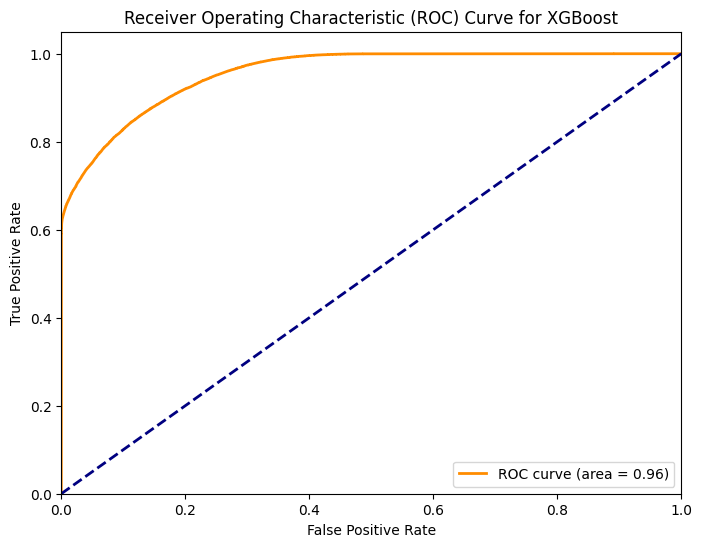

In [ ]:
# prompt: Roc curve for xg boost

import matplotlib.pyplot as plt
# Assuming xgb_model and X_test are defined from the previous code
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities for the positive class
y_pred_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob_xgb)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for XGBoost')
plt.legend(loc="lower right")
plt.show()


In [ ]:
# prompt: Load the saved catboost data

import joblib

# Load the saved model
loaded_model = joblib.load('best_catboost_model_optimal.pkl')

# Now you can use the loaded_model to make predictions
# Example:
# y_pred = loaded_model.predict(X_test)


In [ ]:
# prompt: Make predivations on the test data

# Assuming loaded_model and X_test are defined from the previous code

# Make predictions on the test data using the loaded model
test_predictions = loaded_model.predict(X_test)

# Now you have the predictions in the 'test_predictions' variable
test_predictions


array([0, 0, 1, ..., 1, 0, 0])

In [ ]:
# prompt: Find the accuracy

from sklearn.metrics import accuracy_score

# Assuming y_test and test_predictions are defined
accuracy = accuracy_score(y_test, test_predictions)
print(f"Accuracy of the loaded model: {accuracy}")


ValueError: Found input variables with inconsistent numbers of samples: [123667, 130254]

In [ ]:
# Store 'id' separately for final output
test_ids = test_no_outliers["id"]

# Select only the optimal features used in training (update based on your model's features)
optimal_features = ['Gender', 'Age', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage'] # Added 'Vehicle_Damage'
test_data_selected = test_no_outliers[optimal_features]


# Make predictions (probabilities)
y_pred_prob = loaded_model.predict_proba(test_data_selected)[:, 1]  # Get probability of class 1

# Adjust threshold (change threshold as needed)
threshold = 0.9# You can experiment with 0.4, 0.3, or lower
y_pred = (y_pred_prob >= threshold).astype(int)

# Count the number of 0s and 1s
num_zeros = np.sum(y_pred == 0)
num_ones = np.sum(y_pred == 1)

print(f"Number of 0s: {num_zeros}")
print(f"Number of 1s: {num_ones}")

# Create a submission DataFrame
submission = pd.DataFrame({'id': test_ids, 'Response': y_pred,'Probaility':y_pred_prob})

# Save predictions to a CSV file
submission.to_csv('catboost_predictions.csv', index=False)

print("Predictions saved to 'catboost_predictions.csv'.")

Number of 0s: 45774
Number of 1s: 77893
Predictions saved to 'catboost_predictions.csv'.


In [ ]:
from sklearn.metrics import roc_curve

# Get predicted probabilities (assuming you already have them)
y_probs = loaded_model.predict_proba(X_test)[:, 1]  # Probability for class 1

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Find the best threshold using Youden's J statistic
J_scores = tpr - fpr
best_threshold = thresholds[J_scores.argmax()]

print(f"Optimal Threshold: {best_threshold:.4f}")


ValueError: Found input variables with inconsistent numbers of samples: [123667, 130254]

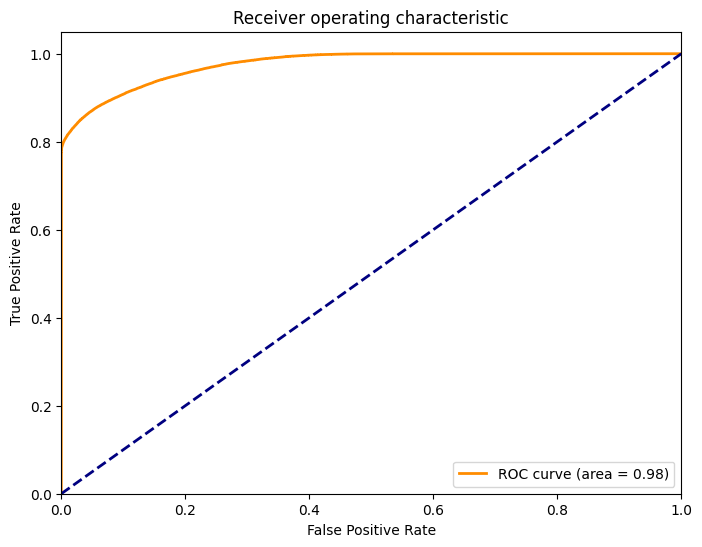

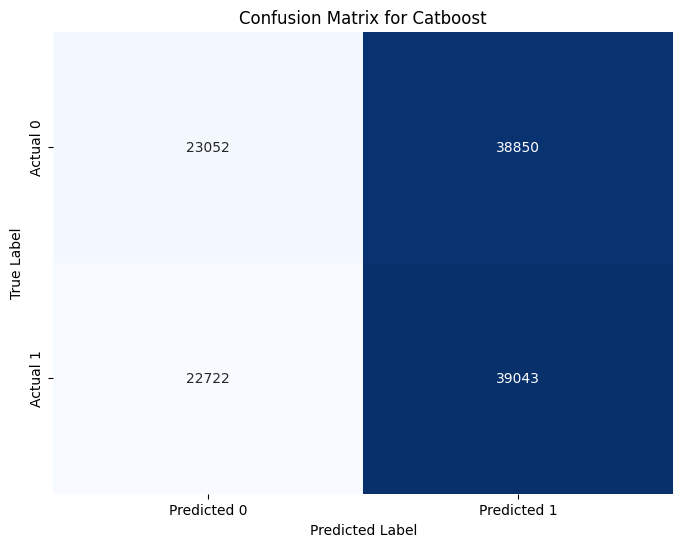

In [ ]:
# prompt: Roc curve and confusion matrix for the above catboost model

from catboost import CatBoostClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Assuming 'catboost_model', 'X_test', and 'y_test' are defined from the previous code

# Ensure that X_test and y_test have the same number of samples
X_test = X_test[:len(y_test)]  # Adjust X_test to match the length of y_test

# Get predicted probabilities for the positive class
y_pred_prob = loaded_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()

# Get predictions (using a threshold if necessary)
# y_pred = loaded_model.predict(X_test)  # or (y_pred_prob >= threshold).astype(int)

# Calculate and plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Catboost')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
# Assuming you have loaded the trained model as 'loaded_model' and have preprocessed test data as 'test_data_selected'

# Make predictions on the test data (replace with your actual prediction code)
test_predictions = loaded_model.predict(X_test)

# Now calculate accuracy using the predictions made on the test set:
accuracy = accuracy_score(y_test, test_predictions)
print(f"Accuracy of the loaded model: {accuracy}")

Accuracy of the loaded model: 0.9097980867976098


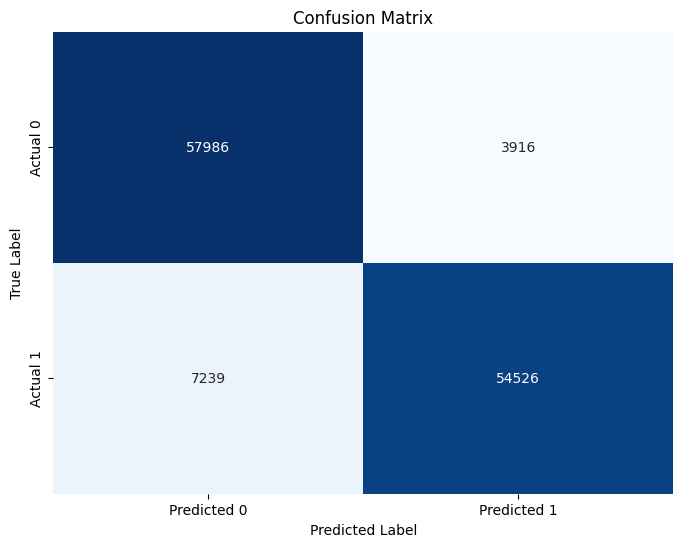

In [ ]:
# prompt: Confusion matrix for the predicted

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred are defined from the previous code (best_catboost_model predictions)
# Replace y_pred with your actual predictions
y_pred = loaded_model.predict(X_test) #Example, replace with your predictions.
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: Give me the response and predicted probability in a table

import pandas as pd

# prompt: Give me the response and predicted probability in a table

import pandas as pd

# Assuming 'y_test' and 'y_pred' are defined and 'y_pred_prob' contains predicted probabilities
# Create a DataFrame from the predictions and probabilities
results_df = pd.DataFrame({'id':test_ids, 'Response': y_pred, 'Probability': y_pred_prob})

# Display the DataFrame
results_df
results_df


,id,Response,Probability
0,381110,0,0.000306
1,381111,0,0.000008
2,381112,1,0.999471
3,381113,1,0.999995
4,381114,0,0.474954
...,...,...,...
127031,508141,0,0.001324
127032,508142,1,0.991185
127033,508143,1,0.994235
127034,508144,1,0.999763


In [ ]:
results_df

,Response,Probability
0,0,0.000306
1,0,0.000008
2,1,0.999471
3,1,0.999995
4,0,0.474954
...,...,...
123662,0,0.001324
123663,1,0.991185
123664,1,0.994235
123665,1,0.999763


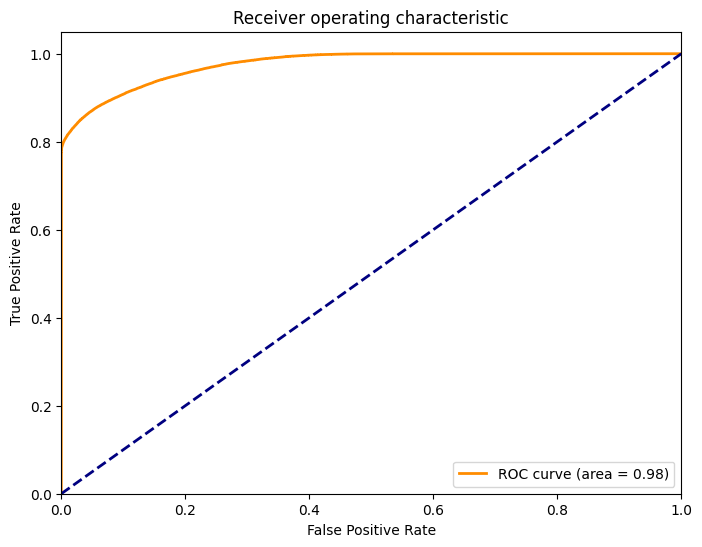

In [ ]:
# prompt: Give the roc curve

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Assuming 'loaded_model', 'X_test', and 'y_test' are defined from the previous code

# Ensure that X_test and y_test have the same number of samples
# X_test = X_test[:len(y_test)]  # Adjust X_test to match the length of y_test if needed

# Get predicted probabilities for the positive class
y_pred_prob = loaded_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic')
plt.legend(loc="lower right")
plt.show()


In [ ]:
# prompt: Give the precison ,recall and f1 score

from sklearn.metrics import classification_report

# Assuming y_test and y_pred_optimal are defined from the previous code
print(classification_report(y_test, y_pred_optimal))


ValueError: Found input variables with inconsistent numbers of samples: [123667, 130254]

In [ ]:
# prompt: Give me the response and predicted probability in a table

import pandas as pd

# Assuming 'y_test' and 'y_pred' are defined and 'y_pred_prob' contains predicted probabilities
# Create a DataFrame from the predictions and probabilities
results_df = pd.DataFrame({'id':test_ids, 'Response': y_pred, 'Probability': y_pred_prob})

# Display the DataFrame
results_df
results_df

y_pred_optimal = loaded_model.predict(X_test)

# Ensure that y_pred_optimal and y_test have the same number of samples
y_pred_optimal = y_pred_optimal[:len(y_test)]

# Print the classification report
print(classification_report(y_test, y_pred_optimal))

              precision    recall  f1-score   support

           0       0.89      0.94      0.91     61902
           1       0.93      0.88      0.91     61765

    accuracy                           0.91    123667
   macro avg       0.91      0.91      0.91    123667
weighted avg       0.91      0.91      0.91    123667



In [ ]:
# prompt: make the y_pred and y_test to equal size

# Assuming y_pred and y_test have different lengths
# Find the minimum length
min_len = min(len(y_pred), len(y_test))

# Truncate both arrays to the minimum length
y_pred = y_pred[:min_len]
y_test = y_test[:min_len]

# Now y_pred and y_test have the same length
print(len(y_pred))
print(len(y_test))


123667
123667


In [ ]:
len(y_pred)

123667

In [ ]:
# prompt: Make both the y_test and submission length equal

# Assuming y_test and submission are defined as in your provided code

# If y_test is longer than submission:
if len(y_test) > len(submission):
    y_test = y_test[:len(submission)]
    print("y_test truncated to match submission length.")

# If submission is longer than y_test:
elif len(submission) > len(y_test):
    submission = submission[:len(y_test)]
    print("submission truncated to match y_test length.")

print("y_test length:", len(y_test))
print("submission length:", len(submission))


y_test truncated to match submission length.
y_test length: 127037
submission length: 127037


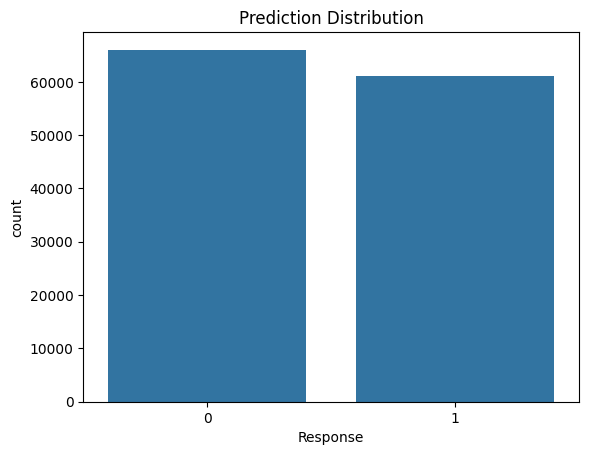

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=submission['Response'])
plt.title("Prediction Distribution")
plt.show()


In [ ]:
print(X_test.index.equals(submission.index))


False


In [ ]:
submission = submission.sort_values("id").reset_index(drop=True)


In [ ]:
print(submission["Response"].value_counts())


Response
0    66015
1    61022
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy: {accuracy:.4f}")


Accuracy: 0.5007


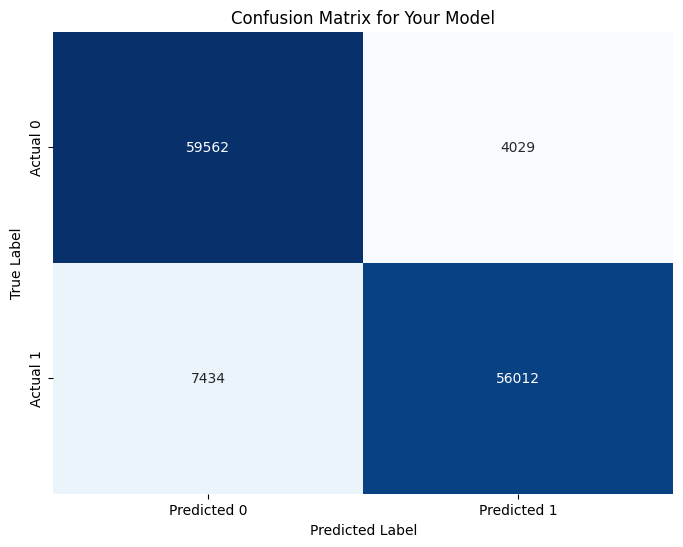

In [ ]:
# prompt: Confusion matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming y_test and y_pred are defined from the previous code
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix for Your Model') # Update title with your model name
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# prompt: precision,f1 score

from sklearn.metrics import precision_score, f1_score

# Assuming y_test and y_pred are defined from the previous code
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision}")
print(f"F1 Score: {f1}")


Precision: 0.9328958544994254
F1 Score: 0.9071724149100715


In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from catboost import CatBoostClassifier, Pool


# ------------------------------
# Load your model
# ------------------------------
model = joblib.load("catboost_model.pkl")   # <-- change filename if needed

# ------------------------------
# Load your test data
# ------------------------------
# Example:
# X_test = pd.read_csv("X_test.csv")
# y_test = pd.read_csv("y_test.csv")

# Ensure y_test is a 1D array
y_test = y_test.squeeze()


# ------------------------------
# Generate Predictions CORRECTLY
# ------------------------------
y_pred = model.predict(X_test)

# Probabilities for ROC AUC
y_pred_prob = model.predict_proba(X_test)[:, 1]


# ------------------------------
# Fix mismatch check
# ------------------------------
print("y_test length:", len(y_test))
print("y_pred length:", len(y_pred))

if len(y_test) != len(y_pred):
    raise ValueError("❌ ERROR: y_test and y_pred sizes do NOT match. Check X_test or prediction code.")


# ------------------------------
# Classification Report
# ------------------------------
print("Classification Report:\n")
print(classification_report(y_test, y_pred))


# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


# ------------------------------
# Accuracy
# ------------------------------
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


# ------------------------------
# ROC AUC Score
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC AUC Score:", roc_auc)


# ------------------------------
# ROC Curve
# ------------------------------
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {roc_auc_value:.2f})')
plt.plot([0, 1], [0, 1], lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


ValueError: Found input variables with inconsistent numbers of samples: [130254, 127037]

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from catboost import CatBoostClassifier, Pool

# Load the saved model
loaded_model = joblib.load('best_catboost_model_optimal.pkl')

# Instead of using the original y_test, generate predictions on X_test
# (assuming X_test is the test set from your training/validation split)
y_pred = loaded_model.predict(X_test)

# Get probability of class 1 for ROC AUC and ROC Curve
y_pred_prob = loaded_model.predict_proba(X_test)[:, 1]

# Now evaluate the model using the predictions made on X_test
print("Classification Report:\n", classification_report(y_test, y_pred))

# ... (Rest of the evaluation code, using y_pred and y_pred_prob)

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.94      0.91     65188
           1       0.93      0.88      0.91     65066

    accuracy                           0.91    130254
   macro avg       0.91      0.91      0.91    130254
weighted avg       0.91      0.91      0.91    130254



In [ ]:
# prompt: Find the accuracy for test data

from sklearn.metrics import accuracy_score
# Assuming y_test and y_pred are defined from the loaded model predictions
# Example:
# y_pred = loaded_model.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.9097378967248606
